<a href="https://colab.research.google.com/github/AugustoAnguita/ATHLETE.ExposomeAnalysis.Tutorial/blob/main/exposome_tutorial_v1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Exposome research analytics: A Hands-on Data Analysis Tutorial**  

<img src="https://github.com/AugustoAnguita/ATHLETE.ExposomeAnalysis.Tutorial_draft/blob/main/figures/2_ATHLETE_logo_subtitle_color.png?raw=1" alt="ISGlobal logo" width="450"/>  

<img src="https://github.com/AugustoAnguita/ATHLETE.ExposomeAnalysis.Tutorial_draft/blob/main/figures/exposoma.png?raw=1" alt="ISGlobal logo" width="500"/>

**Alan Domínguez**, Predoctoral Researcher at the Barcelona Institute for Global Health (ISGlobal).  

**Augusto Anguita-Ruiz**, Junior Leader Researcher at the Barcelona Institute for Global Health (ISGlobal).

**Juan Ramón Gonzalez**, Associate Professor at the Barcelona Institute for Global Health (ISGlobal).

**Xavier Basagaña**, Associate Professor at the Barcelona Institute for Global Health (ISGlobal).

The exposome, described as "the totality of human environmental exposures from conception onwards," recognizes that individuals are simultaneously exposed to multiple different environmental factors, adopting a holistic approach for the discovery of etiological factors of disease. The main advantage of the exposome approach over more traditional ones—“one exposure, one disease or health outcome”—is that it provides a framework for the study of multiple environmental risks (urban, chemical, lifestyle, social, etc...) and their combined effects on health.

The **objective** of this session is to offer an **introduction to the different statistical approaches** necessary to address the main questions of **exposome research**. Every exposome analysis should consist on two main tasks (descriptive analysis, and association analysis):

**1. Descriptive Analysis:**  
In the first part of the session, the concept of descriptive analysis in exposomics will be addressed, through which the first conclusions about the data are drawn. Among other objectives, descriptive analysis aims to identify possible outliers, confounding factors, or variables that require transformations prior to analysis. At the same time, descriptive analysis allows a preliminary comparison of the experimental groups under study, the examination of the existing patterns of correlation among exposure factors, and the identification of grouping phenomena in the data (both at the level of individuals and of features). All of these are essential steps to choose the most appropriate subsequent statistical approach.

Some of the contents we will review in this section:  
* **Visualization of the distribution and concentration of exposome variables.**  
* **Correlation between exposures.**  
* **Principal Component Analysis (PCA) applied to exposome variables.**

**2. Association Analysis:**  
Association analysis aims to identify possible environmental exposure factors associated with different health parameters. In this section of the session, different holistic analytical approaches focused on the study of the effects of multiple exposure factors and their mixtures on health will be presented. This includes mainly models such as ExWAS (Exposome-Wide Association Analysis), or others for the study of interactions or non-linearity phenomena (e.g., Bayesian Kernel Machine Regression). An introduction will also be presented to clustering methods or exposure mixture methods (e.g., Weighted Quantile Sum Regression). During their study, concepts of great importance in exposome analysis will be introduced, such as feature selection or multiple testing correction.

Some of the contents we will review in this section:  
* **Exposure Wide Association Analysis (ExWas)**  
* **Methods for variable selection (Stepwise, Elastic net, DSA)**  
* **Weighted quantile sum regression**  
* **Clustering**  
* **Bayesian Kernel Machine Regression**



# **Reminder: Introduction to NoteBook**

Within this notebook (*NoteBook*), you will be guided step by step from loading a dataset to performing analysis of its content.

The *Jupyter* notebook (here running R) is an approach that combines text blocks (like this one) together with code blocks or cells. The great advantage of this type of cell is its interactivity, as they can be executed to check the results directly within them. *Very important:* **the order of instructions is fundamental**, so each cell in this notebook must be executed sequentially. If any are omitted, the program may throw an error, so you should start from the beginning if in doubt.

First of all:

It is **very very important** that at the start you select **"*Open in draft mode*" (draft mode)**, at the top left. Otherwise, it will not allow you to execute any code block, for security reasons. When the first of the blocks is executed, the following message will appear: "*Warning: This notebook was not created by Google.*". Do not worry, you should trust the content of the notebook (*NoteBook*) and click "Run anyway".

Let’s go!

Click the "play" button on the left side of each code cell. Lines of code that begin with a hashtag (#) are comments and do not affect the execution of the program.

You can also click on each cell and press "*ctrl+enter*" (*cmd+enter* on Mac).

Each time you run a block, you will see the output just below it. The information is usually always related to the last instruction, along with all the `print()` commands in the code.



## **INDEX**
1. [Installation of the R environment and required libraries for exposome analysis](#install-libraries)    
2. [Load data](#load-data)
3. [Exposome descriptive analysis](#descriptive)   
4. [Exposome association analysis](#association)
5. [Other tutorials for exposome research](#tutorials)   
6. [Acknowledgement](#acknowledgement)   


## **1. Installation of the R Environment and Libraries for Exposome Analysis** <a name="install-libraries"></a>

Below, we install/load the libraries necessary for this session. In the context of exposome analysis, R libraries offer us a much more convenient way to process, manipulate, and analyze the data. Some of these libraries: `tidyverse`, `skimr`, `rexposome`, `bkmr`, `gWQS`.

**How we install the packages in Google Colab**

Every time we open the notebook, Google Colab gives us a new, empty machine: packages installed in a previous session are not kept, and installing everything from scratch takes about 30–40 minutes. To save time, we use one of these two options:

* **Option A (recommended for the session): download a copy of the packages already installed.** We installed all the packages once in Google Colab and saved a copy of the R library. The first cell downloads this copy (a few minutes) and tells R to use it. This copy only works with the same R version as the one Colab uses on the day of the session.
* **Option B: install the packages from scratch (≈ 30–40 minutes).** Use it if Option A fails (e.g., if Colab has changed its R version) or to run the notebook outside this course. The code is in the second cell, commented out: select the lines, press `Ctrl + /` to uncomment, and run it.

After either option, run the **loading** cell, which loads the packages with `pacman` and checks that all of them are available. `pacman::p_load()` combines `install.packages()` and `library()`: it loads each package and installs it only if it is missing.

**Note:** with Option A, run these cells a few minutes before the session. With Option B, start **30–40 minutes** before❗❗❗

* **On your local machine (RStudio, etc.):** you usually install once, then just load the packages in each new R session.
* **In Google Colab:** the runtime is temporary. When it resets or disconnects, previously installed packages disappear, so we need to repeat these steps at the start of every session.

In [ ]:
# OPTION A: download a copy of the packages already installed in Colab
# Estimated execution time: 2-5 minutes
t0 <- Sys.time()

# Copy of the R library, built with the companion notebook "build colab library"
lib_url <- "https://github.com/AugustoAnguita/ATHLETE.ExposomeAnalysis.Tutorial/releases/download/r_library_colab/r_library_colab.tar.gz"
lib_dir <- "/content/r_lib"

if (!dir.exists(lib_dir)) {
  options(timeout = 1200)  # large file: allow up to 20 minutes
  lib_tar <- file.path(tempdir(), "r_library_colab.tar.gz")
  download.file(lib_url, destfile = lib_tar, mode = "wb", quiet = TRUE)
  untar(lib_tar, exdir = "/content")
  unlink(lib_tar)
}

# Tell R to look for packages in the downloaded library first
.libPaths(c(lib_dir, .libPaths()))

# Check: the copy must have been built with the same R version as this session
built_with <- readLines(file.path(lib_dir, "R_VERSION.txt"))
cat("Library built with:", built_with, "\n")
cat("This session uses: ", R.version.string, "\n")
if (built_with != R.version.string) {
  cat("WARNING: different R version. If packages fail to load, use Option B (next cell).\n")
}

cat(sprintf("Execution time: %.1f minutes\n", as.numeric(difftime(Sys.time(), t0, units = "mins"))))

Library built with: R version 4.6.1 (2026-06-24) 
This session uses:  R version 4.6.1 (2026-06-24) 
Execution time: 0.2 minutes


In [ ]:
## OPTION B: install all packages from scratch (approx. 30-40 minutes)
## Use it only if Option A fails, or to run the notebook outside this course.
## To use it: select all the lines, press Ctrl + / to uncomment, and run the cell.

# t0 <- Sys.time()
#
# install.packages("pacman")  # allows us to install/load packages simultaneously
#
# # BiocManager and the packages needed by rexposome (around 20 minutes)
# if (!requireNamespace("BiocManager", quietly = TRUE)) install.packages("BiocManager")
# options(repos = BiocManager::repositories())  # CRAN + Bioconductor
#
# packages <- c("Biobase", "mice", "MultiDataSet", "lsr", "FactoMineR",
#               "stringr", "circlize", "corrplot", "ggplot2", "reshape2", "pryr",
#               "scales", "imputeLCMD", "scatterplot3d", "glmnet", "gridExtra",
#               "Hmisc", "gplots", "gtools", "S4Vectors", "qgcomp")
# for (pkg in packages) {
#   if (!pkg %in% rownames(installed.packages())) {
#     message("Installing ", pkg)
#     BiocManager::install(pkg, ask = FALSE, update = FALSE)
#   }
# }
#
# # rexposome from GitHub (around 2 minutes)
# # For older R versions (e.g., RStudio desktop) add: ref = "R-3.0"
# if (!requireNamespace("remotes", quietly = TRUE)) install.packages("remotes")
# remotes::install_github("isglobal-brge/rexposome", upgrade = "never")
#
# cat(sprintf("Execution time: %.1f minutes\n", as.numeric(difftime(Sys.time(), t0, units = "mins"))))

In [ ]:
# LOAD the packages (after Option A or Option B)
# Estimated execution time: seconds with Option A, up to 8 minutes with Option B
# (pacman::p_load() installs any package that is still missing before loading it)
session_pkgs <- c("tidyverse", "corrplot", "RColorBrewer", "skimr", "bkmr", "gWQS", "ggridges",
                  "rexposome", "qgcomp", "MASS", "caret", "glmnet", "partDSA")

pacman::p_load(char = session_pkgs)

# Check: all packages loaded?
not_loaded <- session_pkgs[!(session_pkgs %in% (.packages()))]
if (length(not_loaded) == 0) {
  cat("All packages loaded correctly\n")
} else {
  cat("NOT loaded:", not_loaded, "\n")
}

All packages loaded correctly


## **2. Load the Data** <a name="load-data"></a>

Below are the **lines of code** necessary to **load** the Exposome dataset into the R environment. For this practical session, we will use data from the HELIX (Human Early-Life Exposome) exposome study. The HELIX study is a collaborative project among six population-based birth cohort longitudinal studies from six European countries (France, Greece, Lithuania, Norway, Spain, and the United Kingdom).

<img src="https://github.com/AugustoAnguita/ATHLETE.ExposomeAnalysis.Tutorial_draft/blob/main/figures/HELIX.png?raw=1" alt="HELIX logo" width="500"/>


**Note:** The data provided in this introductory course were semi-simulated from the real data of the HELIX sub-cohort. For more details on the HELIX project and the origin of the data collected we recommend consulting the following publication: https://bmjopen.bmj.com/content/8/9/e021311 and website: https://www.projecthelix.eu/es.

* The **exposome data (n = 1301)** that we will use are contained in an Rdata archive, the archive contains the following files:

1. `phenotype` (outcomes)
2. `exposome` (exposome)
3. `covariates` (covariates)


The `exposome` database contains more than **200 exposures**.

<img src="https://github.com/AugustoAnguita/ATHLETE.ExposomeAnalysis.Tutorial_draft/blob/main/figures/exposures_helix.png?raw=1" alt="HELIX exposures" width="450"/>

The description of each variable (name, structure, variable type, transformation, ...) is detailed in the [codebook](https://github.com/AugustoAnguita/ATHLETE.ExposomeAnalysis.Tutorial_draft/blob/main/data/codebook.csv).


**1.-** We load the data required for the session.

In [ ]:
# Option 1 (we will load the databases as csv files)
phenotype <- read.csv2(url("https://raw.githubusercontent.com/AugustoAnguita/ATHLETE.ExposomeAnalysis.Tutorial_draft/main/data/phenotype.csv"),  header = TRUE) # outcomes
exposome <- read.csv2(url("https://raw.githubusercontent.com/AugustoAnguita/ATHLETE.ExposomeAnalysis.Tutorial_draft/main/data/exposome.csv"), header = TRUE) # exposures
covariates <- read.csv2(url("https://raw.githubusercontent.com/AugustoAnguita/ATHLETE.ExposomeAnalysis.Tutorial_draft/main/data/covariates.csv"), header = TRUE) # covariates
codebook <- read.csv2(url("https://raw.githubusercontent.com/AugustoAnguita/ATHLETE.ExposomeAnalysis.Tutorial_draft/main/data/codebook.csv")) # codebook

In [ ]:
# Option 2 (we load an RData file, this file contains the 3 datasets + the codebook)
load(url("https://raw.githubusercontent.com/AugustoAnguita/ATHLETE.ExposomeAnalysis.Tutorial_draft/main/data/exposome.RData")) #one single line to load the whole dataset

In [ ]:
phenotype
exposome
covariates
codebook

,ID,e3_bw,hs_asthma,hs_zbmi_who,hs_correct_raven,hs_Gen_Tot,hs_bmi_c_cat
,<int>,<int>,<dbl>,<dbl>,<int>,<dbl>,<fct>
1,1,4100,0,0.30,18,84.0000,2
2,2,4158,0,0.41,25,39.0000,2
3,3,4110,1,3.33,13,40.0000,4
4,4,3270,0,-0.76,28,54.5000,2
5,5,3950,0,0.98,19,18.0000,2
6,6,2900,1,-0.08,19,4.0000,2
7,7,3350,0,0.04,34,21.1875,2
8,8,3580,1,-0.10,16,8.0000,2
9,9,3000,0,-1.78,35,19.0625,2


,ID,h_abs_ratio_preg_Log,h_no2_ratio_preg_Log,h_pm10_ratio_preg_None,h_pm25_ratio_preg_None,hs_no2_dy_hs_h_Log,hs_no2_wk_hs_h_Log,hs_no2_yr_hs_h_Log,hs_pm10_dy_hs_h_None,hs_pm10_wk_hs_h_None,⋯,hs_globalexp2_None,hs_smk_parents_None,h_distinvnear1_preg_Log,h_trafload_preg_pow1over3,h_trafnear_preg_pow1over3,hs_trafload_h_pow1over3,hs_trafnear_h_pow1over3,h_bro_preg_Log,h_clf_preg_Log,h_thm_preg_Log
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,0.89671105,2.872304,25.94850,17.433798,2.530279,2.583284,2.612098,22.53583,20.850005,⋯,exposure,both,-5.629052,0.3458301,21.213987,135.99576,24.914911,-2.9759296,-0.5367134,0.2880726
2,2,0.89253797,2.980008,25.89774,18.470850,1.928600,2.652479,2.761064,14.07776,29.141274,⋯,no exposure,neither,-5.045588,0.3458301,22.649684,97.88442,27.905292,-2.9759296,1.0787497,3.1954784
3,3,0.77872299,3.056501,26.08735,18.711547,2.882591,2.591756,2.356163,46.85910,31.530981,⋯,no exposure,one,-4.204225,145.5727586,25.549436,127.53614,29.299706,-1.6044503,1.1887577,3.0239239
4,4,0.08905574,3.089157,14.99138,16.409771,1.390750,2.456717,2.403247,29.81744,25.232778,⋯,exposure,one,-3.088010,187.1200205,22.743850,114.86848,22.743850,2.7488186,3.6368129,3.8393351
5,5,0.60478093,3.848211,35.19730,14.889958,3.204449,3.499594,3.307663,29.81744,24.891465,⋯,no exposure,neither,-1.459250,158.4890394,29.872070,205.77478,14.131454,4.2621375,3.0278427,4.5727340
6,6,0.20045795,2.891142,19.76697,12.825988,3.537311,3.458832,3.443253,24.76304,22.893956,⋯,no exposure,neither,-2.722931,63.1132643,7.937005,150.94307,13.986892,2.7045022,3.6203667,3.8074699
7,7,0.49652571,3.373861,23.12116,19.425609,2.237178,2.044063,2.029703,24.01430,24.891465,⋯,no exposure,neither,-2.548100,30.2726349,7.937005,165.32919,15.095685,2.7089606,0.3371863,3.7164105
8,8,0.20515012,2.878540,19.68730,14.183917,3.082235,3.318016,3.367169,20.78633,23.188724,⋯,no exposure,neither,-4.383742,117.2477971,7.937005,153.93522,22.208216,2.7127035,3.5324524,3.8396766
9,9,0.15538213,3.365869,21.89084,18.900023,1.493143,1.930974,1.988530,21.19045,24.891465,⋯,no exposure,neither,-2.832079,51.7380022,8.962809,67.55812,8.962809,2.0083483,-6.9077553,1.8159404


,ID,h_cohort,e3_sex_None,e3_yearbir_None,h_mbmi_None,hs_wgtgain_None,e3_gac_None,h_age_None,h_edumc_None,h_native_None,h_parity_None,hs_child_age_None,hs_c_height_None,hs_c_weight_None
,<int>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>
1,1,4,male,2008,25.51020,17,41.00000,28.00000,2,2,0,6.165640,1.220,23.4
2,2,4,male,2007,26.49151,18,41.00000,22.84155,3,2,1,6.992471,1.220,27.6
3,3,4,male,2008,30.11621,11,39.00000,34.23242,3,2,1,6.110883,1.280,37.5
4,4,2,female,2005,21.04805,21,39.28571,32.72553,1,2,1,10.138261,1.345,27.7
5,5,3,male,2005,22.15102,20,43.00000,20.86516,1,2,0,9.451175,1.370,34.0
6,6,1,female,2007,24.90358,30,38.85714,27.00000,3,2,0,6.384782,1.130,21.5
7,7,2,male,2003,27.51718,20,40.00000,39.60027,1,2,2,11.343030,1.315,29.8
8,8,1,female,2008,28.14870,20,40.57143,34.00000,2,0,0,6.338125,1.225,22.5
9,9,2,female,2004,23.02895,12,40.85714,30.38741,2,2,1,10.715948,1.510,24.3


,variable_name,domain,family,subfamily,period,location,period_postnatal,description,var_type,transformation,labels,labelsshort
,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>
h_abs_ratio_preg_Log,h_abs_ratio_preg_Log,Outdoor exposures,Air Pollution,PMAbsorbance,Pregnancy,Home,NA,abs value (extrapolated back in time using ratio method)duringpregnancy,numeric,Natural Logarithm,PMabs,PMabs
h_no2_ratio_preg_Log,h_no2_ratio_preg_Log,Outdoor exposures,Air Pollution,NO2,Pregnancy,Home,NA,no2 value (extrapolated back in time using ratio method)during pregnancy,numeric,Natural Logarithm,NO2,NO2
h_pm10_ratio_preg_None,h_pm10_ratio_preg_None,Outdoor exposures,Air Pollution,PM10,Pregnancy,Home,NA,pm10 value (extrapolated back in time using ratio method)duringpregnancy,numeric,None,PM10,PM10
h_pm25_ratio_preg_None,h_pm25_ratio_preg_None,Outdoor exposures,Air Pollution,PM2.5,Pregnancy,Home,NA,pm25 value (extrapolated back in time using ratio method)duringpregnancy,numeric,None,PM2.5,PM2.5
hs_no2_dy_hs_h_Log,hs_no2_dy_hs_h_Log,Outdoor exposures,Air Pollution,NO2,Postnatal,Home,Day before examination,no2 value (extrapolated back in time using ratio method)one day before hs test at home,numeric,Natural Logarithm,NO2(day),NO2(day)
hs_no2_wk_hs_h_Log,hs_no2_wk_hs_h_Log,Outdoor exposures,Air Pollution,NO2,Postnatal,Home,Week before examination,no2 value (extrapolated back in time using ratio method)one week before hs test at home,numeric,Natural Logarithm,NO2(week),NO2(week)
hs_no2_yr_hs_h_Log,hs_no2_yr_hs_h_Log,Outdoor exposures,Air Pollution,NO2,Postnatal,Home,Year before examination,no2 value (extrapolated back in time using ratio method)one year before hs test at home,numeric,Natural Logarithm,NO2(year),NO2(year)
hs_pm10_dy_hs_h_None,hs_pm10_dy_hs_h_None,Outdoor exposures,Air Pollution,PM10,Postnatal,Home,Day before examination,pm10 value (extrapolated back in time using ratio method)one day before hs test at home,numeric,None,PM10(day),PM10(day)
hs_pm10_wk_hs_h_None,hs_pm10_wk_hs_h_None,Outdoor exposures,Air Pollution,PM10,Postnatal,Home,Week before examination,pm10 value (extrapolated back in time using ratio method)one week before hs test at home,numeric,None,PM10(week),PM10(week)


**2.-** We check the data structure and dimension

In [ ]:
dplyr::glimpse(phenotype) # we have 1301 individuals and 7 health outcomes in the dataset

Rows: 1,301
Columns: 7
$ ID               <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16…
$ e3_bw            <int> 4100, 4158, 4110, 3270, 3950, 2900, 3350, 3580, 3000,…
$ hs_asthma        <dbl> 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,…
$ hs_zbmi_who      <dbl> 0.30, 0.41, 3.33, -0.76, 0.98, -0.08, 0.04, -0.10, -1…
$ hs_correct_raven <int> 18, 25, 13, 28, 19, 19, 34, 16, 35, 32, 18, 24, 30, 3…
$ hs_Gen_Tot       <dbl> 84.0000, 39.0000, 40.0000, 54.5000, 18.0000, 4.0000, …
$ hs_bmi_c_cat     <fct> 2, 2, 4, 2, 2, 2, 2, 2, 2, 3, 4, 4, 2, 2, 4, 3, 2, 2,…


In [ ]:
dplyr::glimpse(exposome) # we have 1301 individuals and 223 exposures in the dataset

Rows: 1,301
Columns: 223
$ ID                           <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13…
$ h_abs_ratio_preg_Log         <dbl> 0.89671105, 0.89253797, 0.77872299, 0.089…
$ h_no2_ratio_preg_Log         <dbl> 2.872304, 2.980008, 3.056501, 3.089157, 3…
$ h_pm10_ratio_preg_None       <dbl> 25.94850, 25.89774, 26.08735, 14.99138, 3…
$ h_pm25_ratio_preg_None       <dbl> 17.433798, 18.470850, 18.711547, 16.40977…
$ hs_no2_dy_hs_h_Log           <dbl> 2.530279, 1.928600, 2.882591, 1.390750, 3…
$ hs_no2_wk_hs_h_Log           <dbl> 2.583284, 2.652479, 2.591756, 2.456717, 3…
$ hs_no2_yr_hs_h_Log           <dbl> 2.612098, 2.761064, 2.356163, 2.403247, 3…
$ hs_pm10_dy_hs_h_None         <dbl> 22.53583, 14.07776, 46.85910, 29.81744, 2…
$ hs_pm10_wk_hs_h_None         <dbl> 20.850005, 29.141274, 31.530981, 25.23277…
$ hs_pm10_yr_hs_h_None         <dbl> 31.39907, 31.25053, 27.51600, 23.96526, 2…
$ hs_pm25_dy_hs_h_None         <dbl> 16.950474, 11.155481, 28.454911, 4.624601…
$ hs_pm25_wk_hs

In [ ]:
dplyr::glimpse(covariates) # we have 1301 individuals and 14 covariates in the dataset

Rows: 1,301
Columns: 14
$ ID                <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 1…
$ h_cohort          <fct> 4, 4, 4, 2, 3, 1, 2, 1, 2, 1, 1, 3, 2, 2, 4, 4, 4, 4…
$ e3_sex_None       <fct> male, male, male, female, male, female, male, female…
$ e3_yearbir_None   <fct> 2008, 2007, 2008, 2005, 2005, 2007, 2003, 2008, 2004…
$ h_mbmi_None       <dbl> 25.51020, 26.49151, 30.11621, 21.04805, 22.15102, 24…
$ hs_wgtgain_None   <dbl> 17, 18, 11, 21, 20, 30, 20, 20, 12, 9, 10, 18, 5, 20…
$ e3_gac_None       <dbl> 41.00000, 41.00000, 39.00000, 39.28571, 43.00000, 38…
$ h_age_None        <dbl> 28.00000, 22.84155, 34.23242, 32.72553, 20.86516, 27…
$ h_edumc_None      <fct> 2, 3, 3, 1, 1, 3, 1, 2, 2, 1, 3, 3, 3, 2, 2, 3, 3, 2…
$ h_native_None     <fct> 2, 2, 2, 2, 2, 2, 2, 0, 2, 1, 0, 2, 2, 2, 2, 2, 2, 2…
$ h_parity_None     <fct> 0, 1, 1, 1, 0, 0, 2, 0, 1, 2, 1, 1, 1, 0, 0, 2, 1, 1…
$ hs_child_age_None <dbl> 6.165640, 6.992471, 6.110883, 10.138261, 9.451175, 6…
$ hs_c_height_No

In [ ]:
dplyr::glimpse(codebook) # the codebook file contains description and additional information for each variable in the dataset

Rows: 241
Columns: 12
$ variable_name    <fct> h_abs_ratio_preg_Log, h_no2_ratio_preg_Log, h_pm10_ra…
$ domain           <fct> Outdoor exposures, Outdoor exposures, Outdoor exposur…
$ family           <fct> Air Pollution, Air Pollution, Air Pollution, Air Poll…
$ subfamily        <fct> PMAbsorbance, NO2, PM10, PM2.5, NO2, NO2, NO2, PM10, …
$ period           <fct> Pregnancy, Pregnancy, Pregnancy, Pregnancy, Postnatal…
$ location         <fct> Home, Home, Home, Home, Home, Home, Home, Home, Home,…
$ period_postnatal <fct> NA, NA, NA, NA, Day before examination, Week before e…
$ description      <fct> "abs value (extrapolated back in time using ratio met…
$ var_type         <fct> numeric, numeric, numeric, numeric, numeric, numeric,…
$ transformation   <fct> Natural Logarithm, Natural Logarithm, None, None, Nat…
$ labels           <fct> PMabs, NO2, PM10, PM2.5, NO2(day), NO2(week), NO2(yea…
$ labelsshort      <fct> PMabs, NO2, PM10, PM2.5, NO2(day), NO2(week), NO2(yea…


* If we load the csv files (Option 1), the codebook needs an additional step: use the variable names as row names, as in the RData version. The code below only acts when the csv codebook is loaded (its first column is `X`), so it is safe to run it in any case.

In [ ]:
# Only for the csv codebook (Option 1): variable names as row names and drop the index column "X"
if ("X" %in% colnames(codebook)) {
  rownames(codebook) <- codebook[, 2]
  codebook <- codebook[, -1]
}

In [ ]:
dplyr::glimpse(codebook)

Rows: 241
Columns: 12
$ variable_name    <fct> h_abs_ratio_preg_Log, h_no2_ratio_preg_Log, h_pm10_ra…
$ domain           <fct> Outdoor exposures, Outdoor exposures, Outdoor exposur…
$ family           <fct> Air Pollution, Air Pollution, Air Pollution, Air Poll…
$ subfamily        <fct> PMAbsorbance, NO2, PM10, PM2.5, NO2, NO2, NO2, PM10, …
$ period           <fct> Pregnancy, Pregnancy, Pregnancy, Pregnancy, Postnatal…
$ location         <fct> Home, Home, Home, Home, Home, Home, Home, Home, Home,…
$ period_postnatal <fct> NA, NA, NA, NA, Day before examination, Week before e…
$ description      <fct> "abs value (extrapolated back in time using ratio met…
$ var_type         <fct> numeric, numeric, numeric, numeric, numeric, numeric,…
$ transformation   <fct> Natural Logarithm, Natural Logarithm, None, None, Nat…
$ labels           <fct> PMabs, NO2, PM10, PM2.5, NO2(day), NO2(week), NO2(yea…
$ labelsshort      <fct> PMabs, NO2, PM10, PM2.5, NO2(day), NO2(week), NO2(yea…


**3.-** We make a quick summary of our data, to check if it was loaded correctly.

In [ ]:
skimr::skim(phenotype)

,skim_type,skim_variable,n_missing,complete_rate,factor.ordered,factor.n_unique,factor.top_counts,numeric.mean,numeric.sd,numeric.p0,numeric.p25,numeric.p50,numeric.p75,numeric.p100,numeric.hist
,<chr>,<chr>,<int>,<dbl>,<lgl>,<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,factor,hs_bmi_c_cat,0,1,FALSE,4,"2: 904, 3: 253, 4: 131, 1: 13",NA,NA,NA,NA,NA,NA,NA,NA
2,numeric,ID,0,1,NA,NA,NA,651.0000000,375.7106599,1.00,326.0,651.00,976.0000,1301.00,▇▇▇▇▇
3,numeric,e3_bw,0,1,NA,NA,NA,3389.3020753,509.9945386,1100.00,3080.0,3398.00,3720.0000,5260.00,▁▁▇▅▁
4,numeric,hs_asthma,0,1,NA,NA,NA,0.1091468,0.3119432,0.00,0.0,0.00,0.0000,1.00,▇▁▁▁▁
5,numeric,hs_zbmi_who,0,1,NA,NA,NA,0.4032360,1.1898941,-3.58,-0.4,0.28,1.1300,4.72,▁▅▇▂▁
6,numeric,hs_correct_raven,0,1,NA,NA,NA,26.2882398,6.4448495,9.00,22.0,27.00,32.0000,36.00,▁▃▆▆▇
7,numeric,hs_Gen_Tot,0,1,NA,NA,NA,24.3767223,19.0282319,0.00,10.0,20.00,33.4375,133.00,▇▃▁▁▁


In [ ]:
skimr::skim(data.frame(exposome))

── Data Summary ────────────────────────
                           Values              
Name                       data.frame(exposome)
Number of rows             1301                
Number of columns          223                 
_______________________                        
Column type frequency:                         
  factor                   53                  
  numeric                  170                 
________________________                       
Group variables            None                

── Variable type: factor ───────────────────────────────────────────────────────
   skim_variable               n_missing complete_rate ordered n_unique
 1 e3_alcpreg_yn_None                  0             1 FALSE          2
 2 h_bfdur_Ter                         0             1 FALSE          3
 3 h_cereal_preg_Ter                   0             1 FALSE          3
 4 h_dairy_preg_Ter                    0             1 FALSE          3
 5 h_fastfood_preg_Ter               

ERROR: Error in is.null(text_repr) || nchar(text_repr) == 0L: 'length = 15' in coercion to 'logical(1)'


In [ ]:
skimr::skim(covariates)

── Data Summary ────────────────────────
                           Values    
Name                       covariates
Number of rows             1301      
Number of columns          14        
_______________________              
Column type frequency:               
  factor                   6         
  numeric                  8         
________________________             
Group variables            None      

── Variable type: factor ───────────────────────────────────────────────────────
  skim_variable   n_missing complete_rate ordered n_unique
1 h_cohort                0             1 FALSE          6
2 e3_sex_None             0             1 FALSE          2
3 e3_yearbir_None         0             1 FALSE          7
4 h_edumc_None            0             1 FALSE          3
5 h_native_None           0             1 FALSE          3
6 h_parity_None           0             1 FALSE          3
  top_counts                            
1 5: 272, 3: 224, 4: 207, 1: 202        
2 

ERROR: Error in is.null(text_repr) || nchar(text_repr) == 0L: 'length = 15' in coercion to 'logical(1)'


*   We will use the `rexposome::loadExposome` function to create a single dataset (`ExposomeSet`) from the `data.frames` we initially loaded. This will simplify analyses since it will allow us to use the library `rexposome`, previously loaded. First, let's arrange the data in the appropriate format for our analysis.




In [ ]:
levels(codebook$family)

[1] "Air Pollution"                             
 [2] "Built environment"                         
 [3] "Covariates"                                
 [4] "Indoor air"                                
 [5] "Lifestyle"                                 
 [6] "Metals"                                    
 [7] "Meteorological"                            
 [8] "Natural Spaces"                            
 [9] "Noise"                                     
[10] "Organochlorines"                           
[11] "Organophosphate pesticides"                
[12] "Per- and polyfluoroalkyl substances (PFAS)"
[13] "Phenols"                                   
[14] "Phenotype"                                 
[15] "Phthalates"                                
[16] "Polybrominated diphenyl ethers (PBDE)"     
[17] "Social and economic capital"               
[18] "Tobacco Smoke"                             
[19] "Traffic"                                   
[20] "Water DBPs"

In [ ]:
# We make a subset of the variables for illustrative purposes (you can try with other families).
#xpo.list <- as.character(codebook$variable_name[(codebook$family == "Organochlorines" |
                                                 #codebook$family == "Metals" |
                                                 #codebook$family == "Chemicals" |
                                                 #codebook$family == "Air Pollution" |
                                                 #codebook$family == "Indoor air" |
                                                 #codebook$family == "Built environment") &
                                                 #codebook$period == "Postnatal"]) cambiar por "Pregnancy"
#expo.list

In [ ]:
# we can try with another subset
expo.list <- as.character(codebook$variable_name[(codebook$family == "Organochlorines" |
                                                  codebook$family == "Metals" |
                                                  codebook$family == "Built environment") &
                                                  codebook$period == "Postnatal"])
expo.list

[1] "hs_accesslines300_h_dic0"   "hs_accesspoints300_h_Log"  
 [3] "hs_builtdens300_h_Sqrt"     "hs_connind300_h_Log"       
 [5] "hs_fdensity300_h_Log"       "hs_landuseshan300_h_None"  
 [7] "hs_popdens_h_Sqrt"          "hs_walkability_mean_h_None"
 [9] "hs_accesslines300_s_dic0"   "hs_accesspoints300_s_Log"  
[11] "hs_builtdens300_s_Sqrt"     "hs_connind300_s_Log"       
[13] "hs_fdensity300_s_Log"       "hs_landuseshan300_s_None"  
[15] "hs_popdens_s_Sqrt"          "hs_as_c_Log2"              
[17] "hs_cd_c_Log2"               "hs_co_c_Log2"              
[19] "hs_cs_c_Log2"               "hs_cu_c_Log2"              
[21] "hs_hg_c_Log2"               "hs_mn_c_Log2"              
[23] "hs_mo_c_Log2"               "hs_pb_c_Log2"              
[25] "hs_tl_cdich_None"           "hs_dde_cadj_Log2"          
[27] "hs_ddt_cadj_Log2"           "hs_hcb_cadj_Log2"          
[29] "hs_pcb118_cadj_Log2"        "hs_pcb138_cadj_Log2"       
[31] "hs_pcb153_cadj_Log2"        "hs_pcb170_cadj_Log2"       
[33] "hs_pcb180_cadj_Log2"        "hs_sumPCBs5_cadj_Log2"

In [ ]:
# We can exclude some exposure variables in which we have no interest.
expo.list <- expo.list[-which(expo.list == "hs_tl_cdich_None")]
expo.list <- expo.list[-which(expo.list == "hs_sumPCBs5_cadj_Log2")]

In [ ]:
# select specific columns(variables) from the families we selected in the previous step and add the variable ID
expo2 <- exposome[ ,c("ID", expo.list)]

In [ ]:
# we scale the continuous exposures by dividing them by their IQR (without centering them),
# so that regression coefficients are expressed per IQR increase.
# Columns 2 and 10 (hs_accesslines300_*_dic0) are dichotomous and are not scaled
index.cont <- c(3:9,11:ncol(expo2))
for (i in index.cont) {
  expo2[,i] <- expo2[,i]/IQR(expo2[,i],na.rm=T)
}

In [ ]:
# we review the selected variables
dplyr::glimpse(expo2)

Rows: 1,301
Columns: 33
$ ID                         <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, …
$ hs_accesslines300_h_dic0   <dbl> 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0…
$ hs_accesspoints300_h_Log   <dbl> 1.0410206, 1.7236128, 0.3585836, 2.8483688,…
$ hs_builtdens300_h_Sqrt     <dbl> 2.5614489, 2.4102779, 2.3607646, 3.0238301,…
$ hs_connind300_h_Log        <dbl> 4.761417, 3.915685, 3.002645, 5.709277, 5.0…
$ hs_fdensity300_h_Log       <dbl> 4.935381, 4.935381, 4.935381, 6.721231, 5.2…
$ hs_landuseshan300_h_None   <dbl> 1.9739687, 1.7899665, 2.6763931, 2.5376134,…
$ hs_popdens_h_Sqrt          <dbl> 1.54657294, 0.18646883, 0.18646883, 1.21078…
$ hs_walkability_mean_h_None <dbl> 3.75, 2.00, 2.50, 5.25, 3.00, 3.75, 3.00, 3…
$ hs_accesslines300_s_dic0   <dbl> 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0…
$ hs_accesspoints300_s_Log   <dbl> 0.3585836, 1.3583974, 1.3583974, 2.0410206,…
$ hs_builtdens300_s_Sqrt     <dbl> 2.3222513, 2.3141441, 2.2101754, 2.4506088,…
$ hs_connind300_

In [ ]:
# list of exposure variables
codebook[expo.list,]$labels

[1] Access_ lines_home     Access_stops_home      Building_home         
 [4] Connectivity           Facility_dens          Land use              
 [7] Population             Walkability            Access_ lines_school  
[10] Access_stops_school    Building_school_school Connectivity_school   
[13] Facility_dens_school   Land use_school        Population_school     
[16] As                     Cd                     Co                    
[19] Cs                     Cu                     Hg                    
[22] Mn                     Mo                     Pb                    
[25] DDE                    DDT                    HCB                   
[28] PCB 118                PCB 138                PCB 153               
[31] PCB 170                PCB 180               
178 Levels: Access_ lines Access_ lines_home ... Yogurt

* We will combine the `phenotype` and `covariates` files

In [ ]:
dat <- cbind(hs_zbmi_who = phenotype[ ,4],  # select the 4th column of the phenotype dataframe and name it hs_zbmi_who
             covariates[ ,2:13])  # we select from columns 2 to 13 of the dataframe covariates

# then, we can combine them
data <- data.frame(expo2, dat)

In [ ]:
# we review the database generated
dplyr::glimpse(data)

Rows: 1,301
Columns: 46
$ ID                         <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, …
$ hs_accesslines300_h_dic0   <dbl> 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0…
$ hs_accesspoints300_h_Log   <dbl> 1.0410206, 1.7236128, 0.3585836, 2.8483688,…
$ hs_builtdens300_h_Sqrt     <dbl> 2.5614489, 2.4102779, 2.3607646, 3.0238301,…
$ hs_connind300_h_Log        <dbl> 4.761417, 3.915685, 3.002645, 5.709277, 5.0…
$ hs_fdensity300_h_Log       <dbl> 4.935381, 4.935381, 4.935381, 6.721231, 5.2…
$ hs_landuseshan300_h_None   <dbl> 1.9739687, 1.7899665, 2.6763931, 2.5376134,…
$ hs_popdens_h_Sqrt          <dbl> 1.54657294, 0.18646883, 0.18646883, 1.21078…
$ hs_walkability_mean_h_None <dbl> 3.75, 2.00, 2.50, 5.25, 3.00, 3.75, 3.00, 3…
$ hs_accesslines300_s_dic0   <dbl> 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0…
$ hs_accesspoints300_s_Log   <dbl> 0.3585836, 1.3583974, 1.3583974, 2.0410206,…
$ hs_builtdens300_s_Sqrt     <dbl> 2.3222513, 2.3141441, 2.2101754, 2.4506088,…
$ hs_connind300_

In [ ]:
str(data)

'data.frame':	1301 obs. of  46 variables:
 $ ID                        : int  1 2 3 4 5 6 7 8 9 10 ...
 $ hs_accesslines300_h_dic0  : num  0 0 0 1 1 0 0 0 0 0 ...
 $ hs_accesspoints300_h_Log  : num  1.041 1.724 0.359 2.848 2.25 ...
 $ hs_builtdens300_h_Sqrt    : num  2.56 2.41 2.36 3.02 1.32 ...
 $ hs_connind300_h_Log       : num  4.76 3.92 3 5.71 5.03 ...
 $ hs_fdensity300_h_Log      : num  4.94 4.94 4.94 6.72 5.27 ...
 $ hs_landuseshan300_h_None  : num  1.97 1.79 2.68 2.54 2.85 ...
 $ hs_popdens_h_Sqrt         : num  1.547 0.186 0.186 1.211 0.083 ...
 $ hs_walkability_mean_h_None: num  3.75 2 2.5 5.25 3 3.75 3 3.25 2.75 5.25 ...
 $ hs_accesslines300_s_dic0  : num  0 0 0 1 0 0 0 0 0 0 ...
 $ hs_accesspoints300_s_Log  : num  0.359 1.358 1.358 2.041 1.358 ...
 $ hs_builtdens300_s_Sqrt    : num  2.322 2.314 2.21 2.451 0.373 ...
 $ hs_connind300_s_Log       : num  2.83 4.15 4.76 6.76 5.66 ...
 $ hs_fdensity300_s_Log      : num  4.46 4.46 4.46 5.36 4.76 ...
 $ hs_landuseshan300_s_None  : n

Now we will create our `ExposomeSet` object by combining our three files that we worked on in the previous lines. This dataset is composed of:

* **3 families of exposures** (built environment, metals, organochlorines), with a total of **32 exposures**. [continuous variables]  
* **1 outcome** (z-score BMI) [continuous variable]  
* **1 exposure window** [postnatal period]


In [ ]:
exp <- rexposome::loadExposome(
  exposures = expo2[expo.list],
  description = codebook[expo.list,],
  phenotype = dat,
  description.famCol = "family"
  )

In [ ]:
dplyr::glimpse(exp)

Formal class 'ExposomeSet' [package "rexposome"] with 7 slots
  ..@ assayData        :<environment: 0x59adfc2d7260> 
  ..@ phenoData        :Formal class 'AnnotatedDataFrame' [package "Biobase"] with 4 slots
  ..@ featureData      :Formal class 'AnnotatedDataFrame' [package "Biobase"] with 4 slots
  ..@ experimentData   :Formal class 'MIAME' [package "Biobase"] with 13 slots
  ..@ annotation       : chr(0) 
  ..@ protocolData     :Formal class 'AnnotatedDataFrame' [package "Biobase"] with 4 slots
  ..@ .__classVersion__:Formal class 'Versions' [package "Biobase"] with 1 slot


We can also join our databases using the `dplyr::inner_join` function, this `exp_all` object will be a `data.frame` and not an `ExposomeSet` object so we will not be able to use all the functionality of the `rexposome` package.

In [ ]:
# with the following line we can join all the databases using ID as the key variable (to ensure they are all merged in the same row order)
exp_all <- phenotype %>%
           dplyr::inner_join(exposome, by = "ID") %>%
           dplyr::inner_join(covariates, by = "ID")

In [ ]:
dplyr::glimpse(exp_all) # in total we have 1,301 individuals and 242 variables

Rows: 1,301
Columns: 242
$ ID                           <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13…
$ e3_bw                        <int> 4100, 4158, 4110, 3270, 3950, 2900, 3350,…
$ hs_asthma                    <dbl> 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0,…
$ hs_zbmi_who                  <dbl> 0.30, 0.41, 3.33, -0.76, 0.98, -0.08, 0.0…
$ hs_correct_raven             <int> 18, 25, 13, 28, 19, 19, 34, 16, 35, 32, 1…
$ hs_Gen_Tot                   <dbl> 84.0000, 39.0000, 40.0000, 54.5000, 18.00…
$ hs_bmi_c_cat                 <fct> 2, 2, 4, 2, 2, 2, 2, 2, 2, 3, 4, 4, 2, 2,…
$ h_abs_ratio_preg_Log         <dbl> 0.89671105, 0.89253797, 0.77872299, 0.089…
$ h_no2_ratio_preg_Log         <dbl> 2.872304, 2.980008, 3.056501, 3.089157, 3…
$ h_pm10_ratio_preg_None       <dbl> 25.94850, 25.89774, 26.08735, 14.99138, 3…
$ h_pm25_ratio_preg_None       <dbl> 17.433798, 18.470850, 18.711547, 16.40977…
$ hs_no2_dy_hs_h_Log           <dbl> 2.530279, 1.928600, 2.882591, 1.390750, 3…
$ hs_no2_wk_hs_

## **3.- Descriptive analysis of the Exposome** <a name="descriptive"></a>

For the descriptive analysis of the exposome we are going to use the `rexposome` library. This library contains different functions designed to explore and describe exposome data (missing data, distribution, correlation). Some of its functions are: `normalityTest` ,`plotMissing`, `plotHistogram`, `plotFamily`, `correlation`, `plotCorrelation`.

In [ ]:
# we check the database we will use (it needs to be an ExposomeSet object)
str(exp)

Formal class 'ExposomeSet' [package "rexposome"] with 7 slots
  ..@ assayData        :<environment: 0x59adfc2d7260> 
  ..@ phenoData        :Formal class 'AnnotatedDataFrame' [package "Biobase"] with 4 slots
  .. .. ..@ varMetadata      :'data.frame':	13 obs. of  1 variable:
  .. .. .. ..$ labelDescription: chr [1:13] NA NA NA NA ...
  .. .. ..@ data             :'data.frame':	1301 obs. of  13 variables:
  .. .. .. ..$ hs_zbmi_who      : num [1:1301] 0.3 1.75 0.01 -0.5 -0.13 -1.25 0.87 -0.05 -0.2 1.35 ...
  .. .. .. ..$ h_cohort         : Factor w/ 6 levels "1","2","3","4",..: 4 1 3 3 3 1 5 3 5 4 ...
  .. .. .. ..$ e3_sex_None      : Factor w/ 2 levels "female","male": 2 1 1 1 1 2 2 1 2 1 ...
  .. .. .. ..$ e3_yearbir_None  : Factor w/ 7 levels "2003","2004",..: 6 6 4 3 3 6 3 3 3 6 ...
  .. .. .. ..$ h_mbmi_None      : num [1:1301] 25.5 40.3 23.3 24.1 20.3 ...
  .. .. .. ..$ hs_wgtgain_None  : num [1:1301] 17 9 9 10 8 8 12 11 17 16 ...
  .. .. .. ..$ e3_gac_None      : num [1:1301] 41 

We will use the `rexposome::normalityTest` function to evaluate the exposome variables that follow a normal distribution, which is required by some methods.

In [ ]:
nm <- rexposome::normalityTest(exp)
table(nm$normality)


FALSE  TRUE 
   29     1 

In [ ]:
# we check all variables that do not have a normal distribution
nm$exposure[!nm$normality]

[1] "hs_pcb170_cadj_Log2"        "hs_hcb_cadj_Log2"          
 [3] "hs_mo_c_Log2"               "hs_pcb138_cadj_Log2"       
 [5] "hs_ddt_cadj_Log2"           "hs_fdensity300_h_Log"      
 [7] "hs_pcb180_cadj_Log2"        "hs_as_c_Log2"              
 [9] "hs_accesspoints300_h_Log"   "hs_cd_c_Log2"              
[11] "hs_fdensity300_s_Log"       "hs_accesspoints300_s_Log"  
[13] "hs_connind300_s_Log"        "hs_popdens_h_Sqrt"         
[15] "hs_co_c_Log2"               "hs_pcb118_cadj_Log2"       
[17] "hs_connind300_h_Log"        "hs_dde_cadj_Log2"          
[19] "hs_hg_c_Log2"               "hs_popdens_s_Sqrt"         
[21] "hs_builtdens300_s_Sqrt"     "hs_walkability_mean_h_None"
[23] "hs_cu_c_Log2"               "hs_landuseshan300_s_None"  
[25] "hs_pb_c_Log2"               "hs_builtdens300_h_Sqrt"    
[27] "hs_landuseshan300_h_None"   "hs_pcb153_cadj_Log2"       
[29] "hs_cs_c_Log2"

### **3.1.- Visualizing distribution and dispersion of exposome variables**

In [ ]:
str(exp)

Formal class 'ExposomeSet' [package "rexposome"] with 7 slots
  ..@ assayData        :<environment: 0x59adfc2d7260> 
  ..@ phenoData        :Formal class 'AnnotatedDataFrame' [package "Biobase"] with 4 slots
  .. .. ..@ varMetadata      :'data.frame':	13 obs. of  1 variable:
  .. .. .. ..$ labelDescription: chr [1:13] NA NA NA NA ...
  .. .. ..@ data             :'data.frame':	1301 obs. of  13 variables:
  .. .. .. ..$ hs_zbmi_who      : num [1:1301] 0.3 1.75 0.01 -0.5 -0.13 -1.25 0.87 -0.05 -0.2 1.35 ...
  .. .. .. ..$ h_cohort         : Factor w/ 6 levels "1","2","3","4",..: 4 1 3 3 3 1 5 3 5 4 ...
  .. .. .. ..$ e3_sex_None      : Factor w/ 2 levels "female","male": 2 1 1 1 1 2 2 1 2 1 ...
  .. .. .. ..$ e3_yearbir_None  : Factor w/ 7 levels "2003","2004",..: 6 6 4 3 3 6 3 3 3 6 ...
  .. .. .. ..$ h_mbmi_None      : num [1:1301] 25.5 40.3 23.3 24.1 20.3 ...
  .. .. .. ..$ hs_wgtgain_None  : num [1:1301] 17 9 9 10 8 8 12 11 17 16 ...
  .. .. .. ..$ e3_gac_None      : num [1:1301] 41 

* **Histograms**.  

Using the `plotHistogram` function we check the distribution of the categorical and continuous variables in our database. In the histograms we can see an exposition of each family.



Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the rexposome package.
  Please report the issue to the authors.”
Warning message:
“The dot-dot notation (`..density..`) was deprecated in ggplot2 3.4.0.
ℹ Please use `after_stat(density)` instead.
ℹ The deprecated feature was likely used in the rexposome package.
  Please report the issue to the authors.”
`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


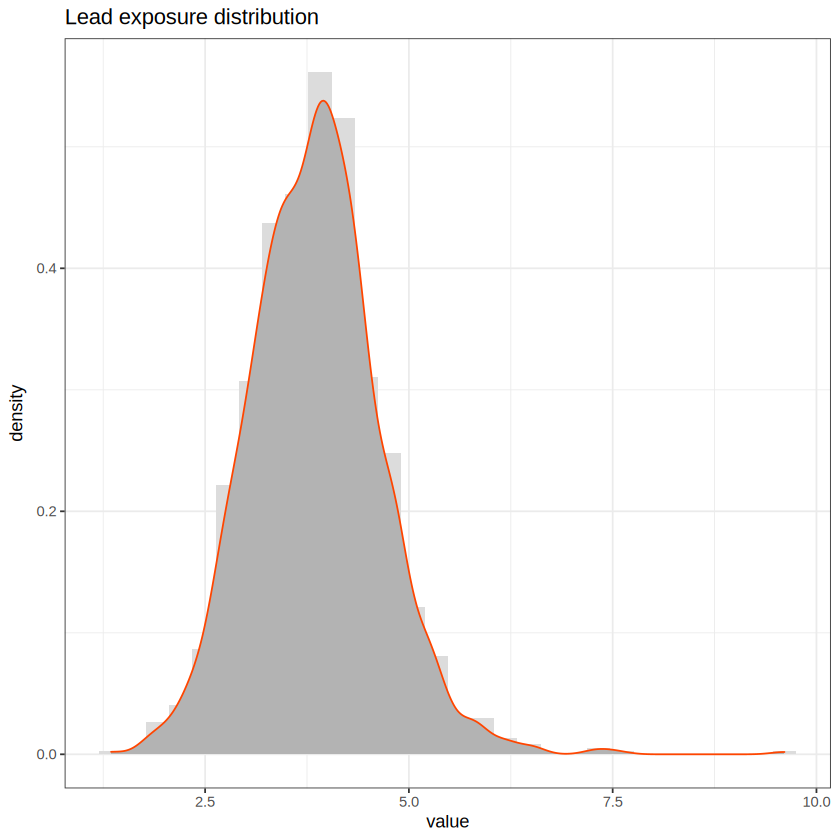

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


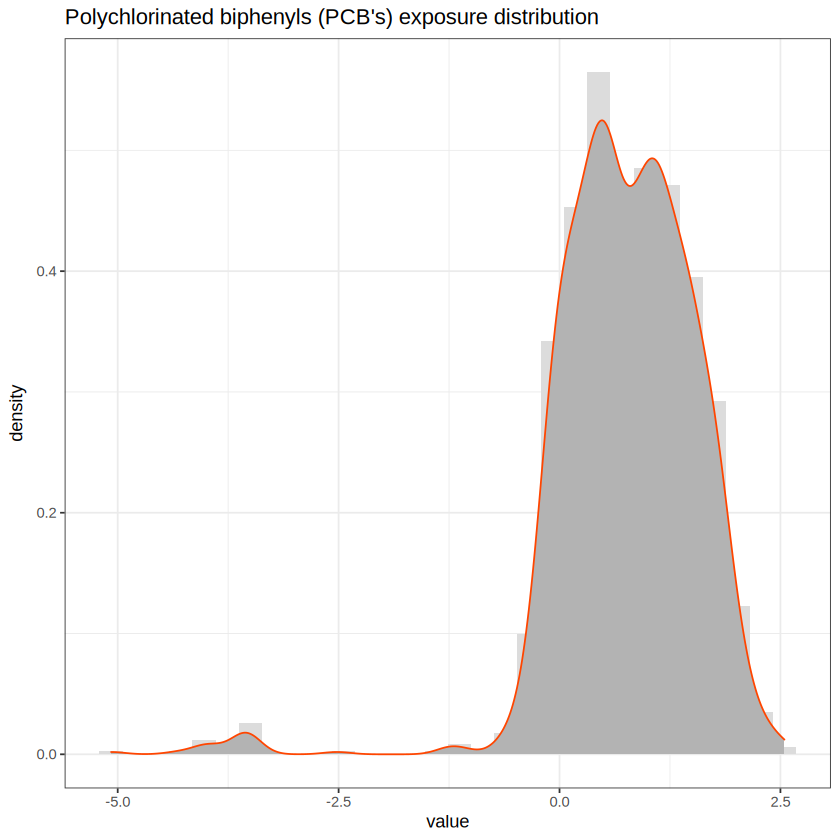

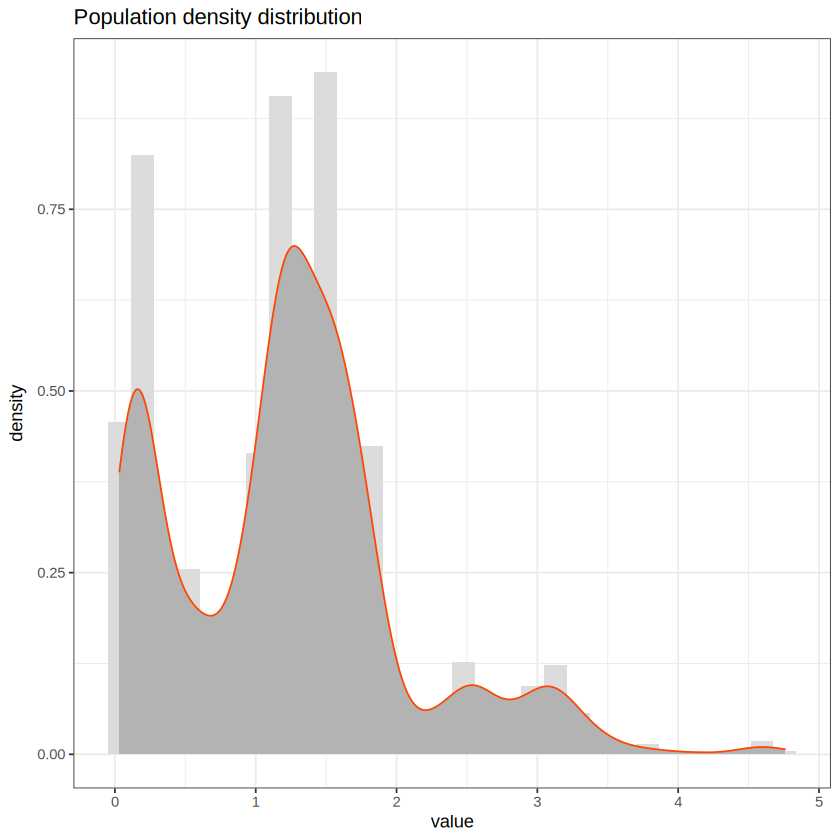

In [ ]:
rexposome::plotHistogram(exp, select = "hs_pb_c_Log2") + ggtitle("Lead exposure distribution")  # Lead histogram
rexposome::plotHistogram(exp, select = "hs_pcb180_cadj_Log2") + ggtitle("Polychlorinated biphenyls (PCB's) exposure distribution") # Pcb180 histogram
rexposome::plotHistogram(exp, select = "hs_popdens_h_Sqrt") + ggtitle("Population density distribution") # Population density histogram

**Interpretation of the histograms.** The distribution of **population density** is **multimodal** (it has several peaks) and **right-skewed**. This is not a problem for linear regression, which makes no assumption about the distribution of the predictors (its assumptions concern the residuals). However, several peaks announce the **existence of subgroups** in the data. In a multi-cohort study such as HELIX, the obvious candidate is the cohort: each cohort comes from a different city or region, with its own urban density. The next cell checks it. Subgroups of this kind are one of the reasons why we adjust all the association models for cohort, and why we center the exposures by cohort before clustering (Section 4.3).

1         2         3         4         5         6 
1.2746043 0.2042664 2.0659887 1.5465729 1.2219189 0.9135052

Picking joint bandwidth of 0.154



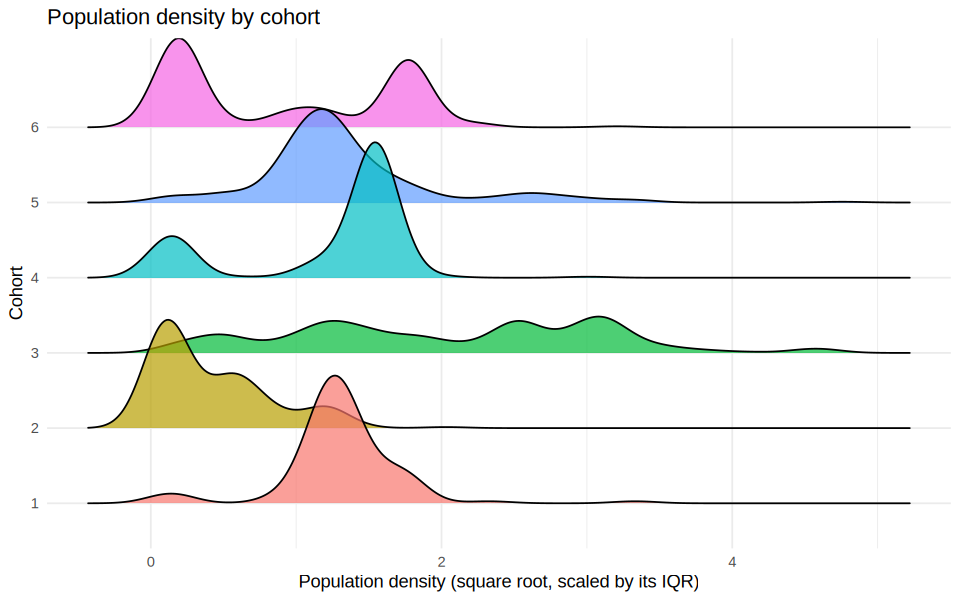

In [ ]:
# Are the peaks explained by the cohorts? Median population density and its distribution by cohort
tapply(data$hs_popdens_h_Sqrt, data$h_cohort, median)

options(repr.plot.width = 8, repr.plot.height = 5)
ggplot(data, aes(x = hs_popdens_h_Sqrt, y = h_cohort, fill = h_cohort)) +
  ggridges::geom_density_ridges(alpha = 0.7) +
  labs(title = "Population density by cohort",
       x = "Population density (square root, scaled by its IQR)", y = "Cohort") +
  theme_minimal() +
  theme(legend.position = "none")

* **Boxplots**.

Using the `plotFamily` function we can describe an exposure by family and stratify by group. Here are a few examples (you can try with other families)

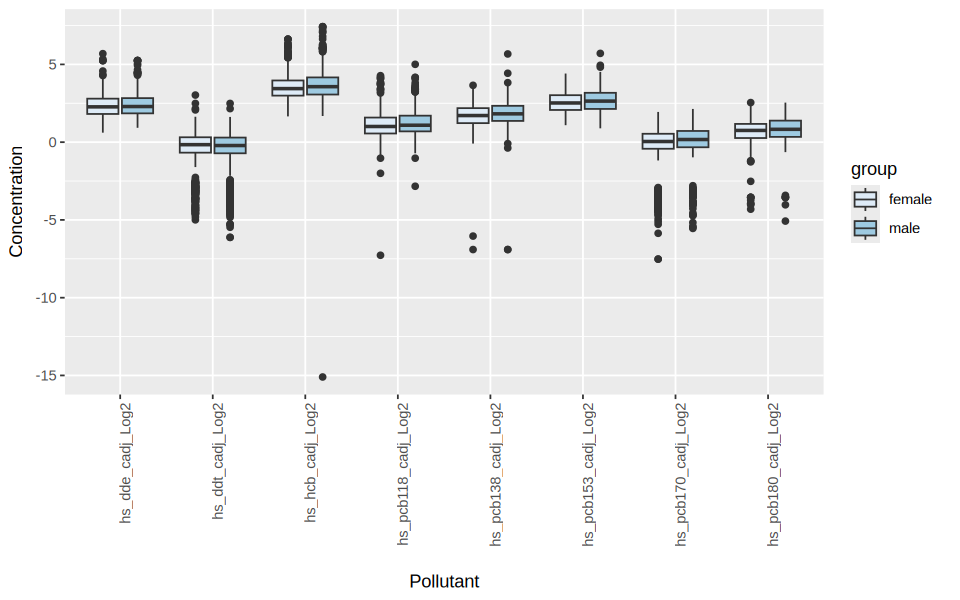

In [ ]:
# Organochlorine Contaminants stratified by Sex
rexposome::plotFamily(exp, family = "Organochlorines", group = "e3_sex_None") +
   xlab('Pollutant') +
   ylab('Concentration')

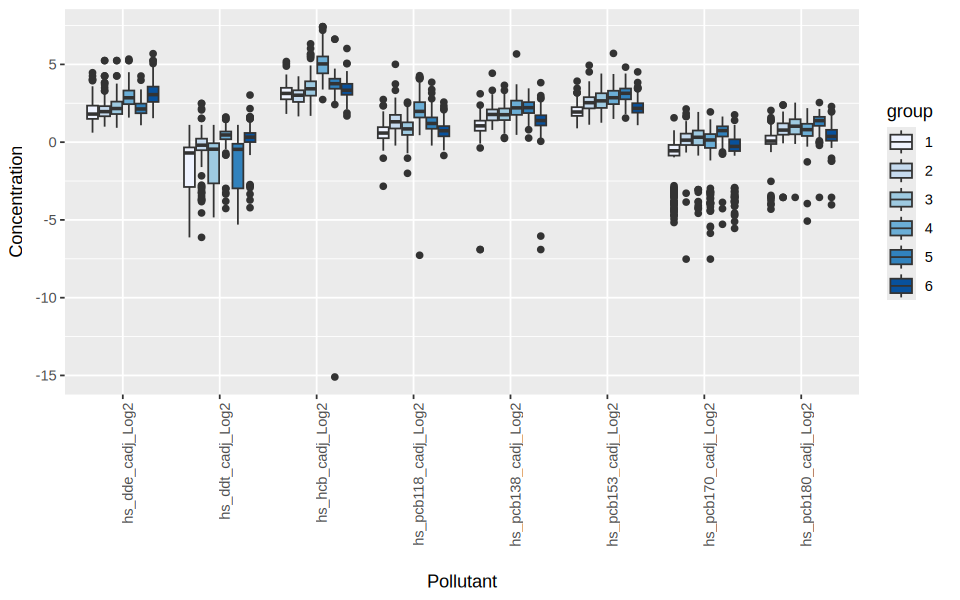

In [ ]:
# Organochlorine Contaminants stratified by Cohort
rexposome::plotFamily(exp, family = "Organochlorines", group = "h_cohort") +
                      xlab('Pollutant') +
                      ylab('Concentration')

In [ ]:
# Indoor pollutants stratified by Cohort
#rexposome::plotFamily(exp, family = "Indoor air", group = "h_cohort")

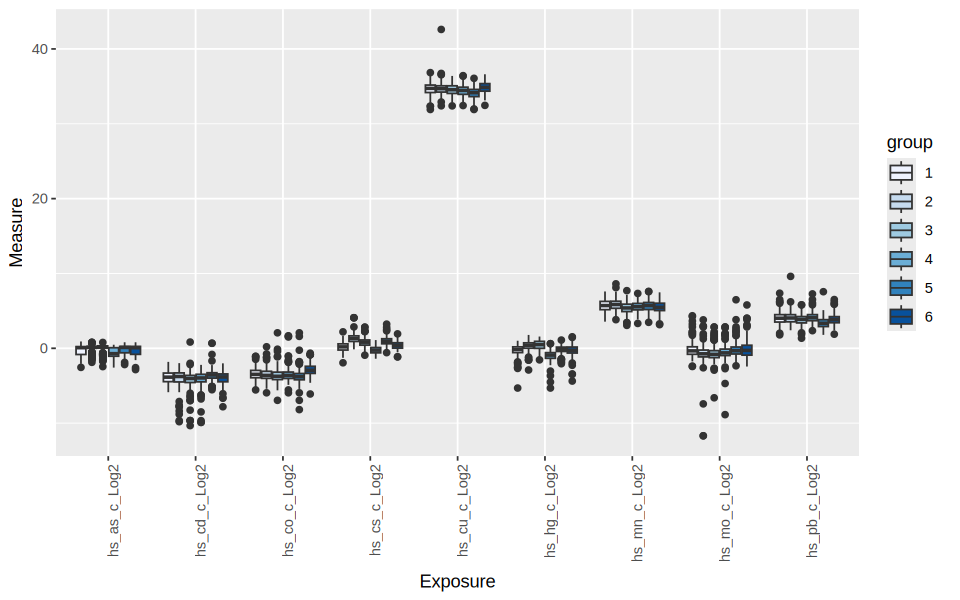

In [ ]:
# Metals levels in blood stratified by Cohort
rexposome::plotFamily(exp, family = "Metals", group = "h_cohort")

**Note on copper (Cu).** In this plot, Cu shows much higher values than the other metals. This does **not** mean that children are more exposed to Cu: it is an artefact of how we scaled the data. In Section 2 we divided each exposure by its IQR **without centering it**. Cu is an essential element under tight homeostatic control, so its distribution is very narrow (small IQR on the log2 scale), and dividing its log2 values by such a small IQR produces very large numbers.

Two lessons:
* Values in this type of plot are not comparable across exposures measured on different scales.
* Methods that depend on the scale of the variables, such as penalised regression (elastic net), PCA or k-means clustering, require the exposures to be on a common scale (standardised or IQR-scaled). Otherwise, the variables with larger variance dominate the penalty, the components or the distances. What matters for these methods is the spread of each variable, not its mean level. `glmnet` standardises the predictors internally by default (`standardize = TRUE`), and before the PCA we will use `rexposome::standardize()`. In unpenalised linear models (ExWAS, stepwise), scaling does not change the fit, only the units of the coefficients (here, per IQR increase).

### **3.2.- Correlation between exposures**

Correlation between variables is an important thing to take into consideration when we want to do exposome analysis. To look at the intra- and inter-family correlation of different exposures, we will use the function `rexposome::correlation`.

We use the **Spearman** correlation because most exposures are not normally distributed (see the normality test above). Spearman works on ranks, so it does not assume normality, it is robust to outliers and it captures any monotonic relationship (not only linear ones). If the exposures were normally distributed, the Pearson correlation would be the natural choice.

In [ ]:
# Spearman (rank-based) correlation: most exposures are not normally distributed (normalityTest above).
# With normally distributed exposures we would use method.cor = "pearson".
# use = "pairwise.complete.obs": each pair of exposures uses all the individuals with data for both.
exp_cor <- rexposome::correlation(exp, use = "pairwise.complete.obs", method.cor = "spearman")

In [ ]:
extract(exp_cor)[1:4, 1:4]

,hs_accesslines300_h_dic0,hs_accesslines300_s_dic0,hs_accesspoints300_h_Log,hs_accesspoints300_s_Log
hs_accesslines300_h_dic0,1.0000000,0.8735366,0.2994728,0.3298710
hs_accesslines300_s_dic0,0.8735366,1.0000000,0.2708063,0.3297577
hs_accesspoints300_h_Log,0.2994728,0.2708063,1.0000000,0.6331554
hs_accesspoints300_s_Log,0.3298710,0.3297577,0.6331554,1.0000000


We can visualise the correlation of all exposures in the exposome (from our dataset) using two types of plots with the `rexposome::plotCorrelation` function. By changing the type argument to `circos` or `matrix` we get a different plot.

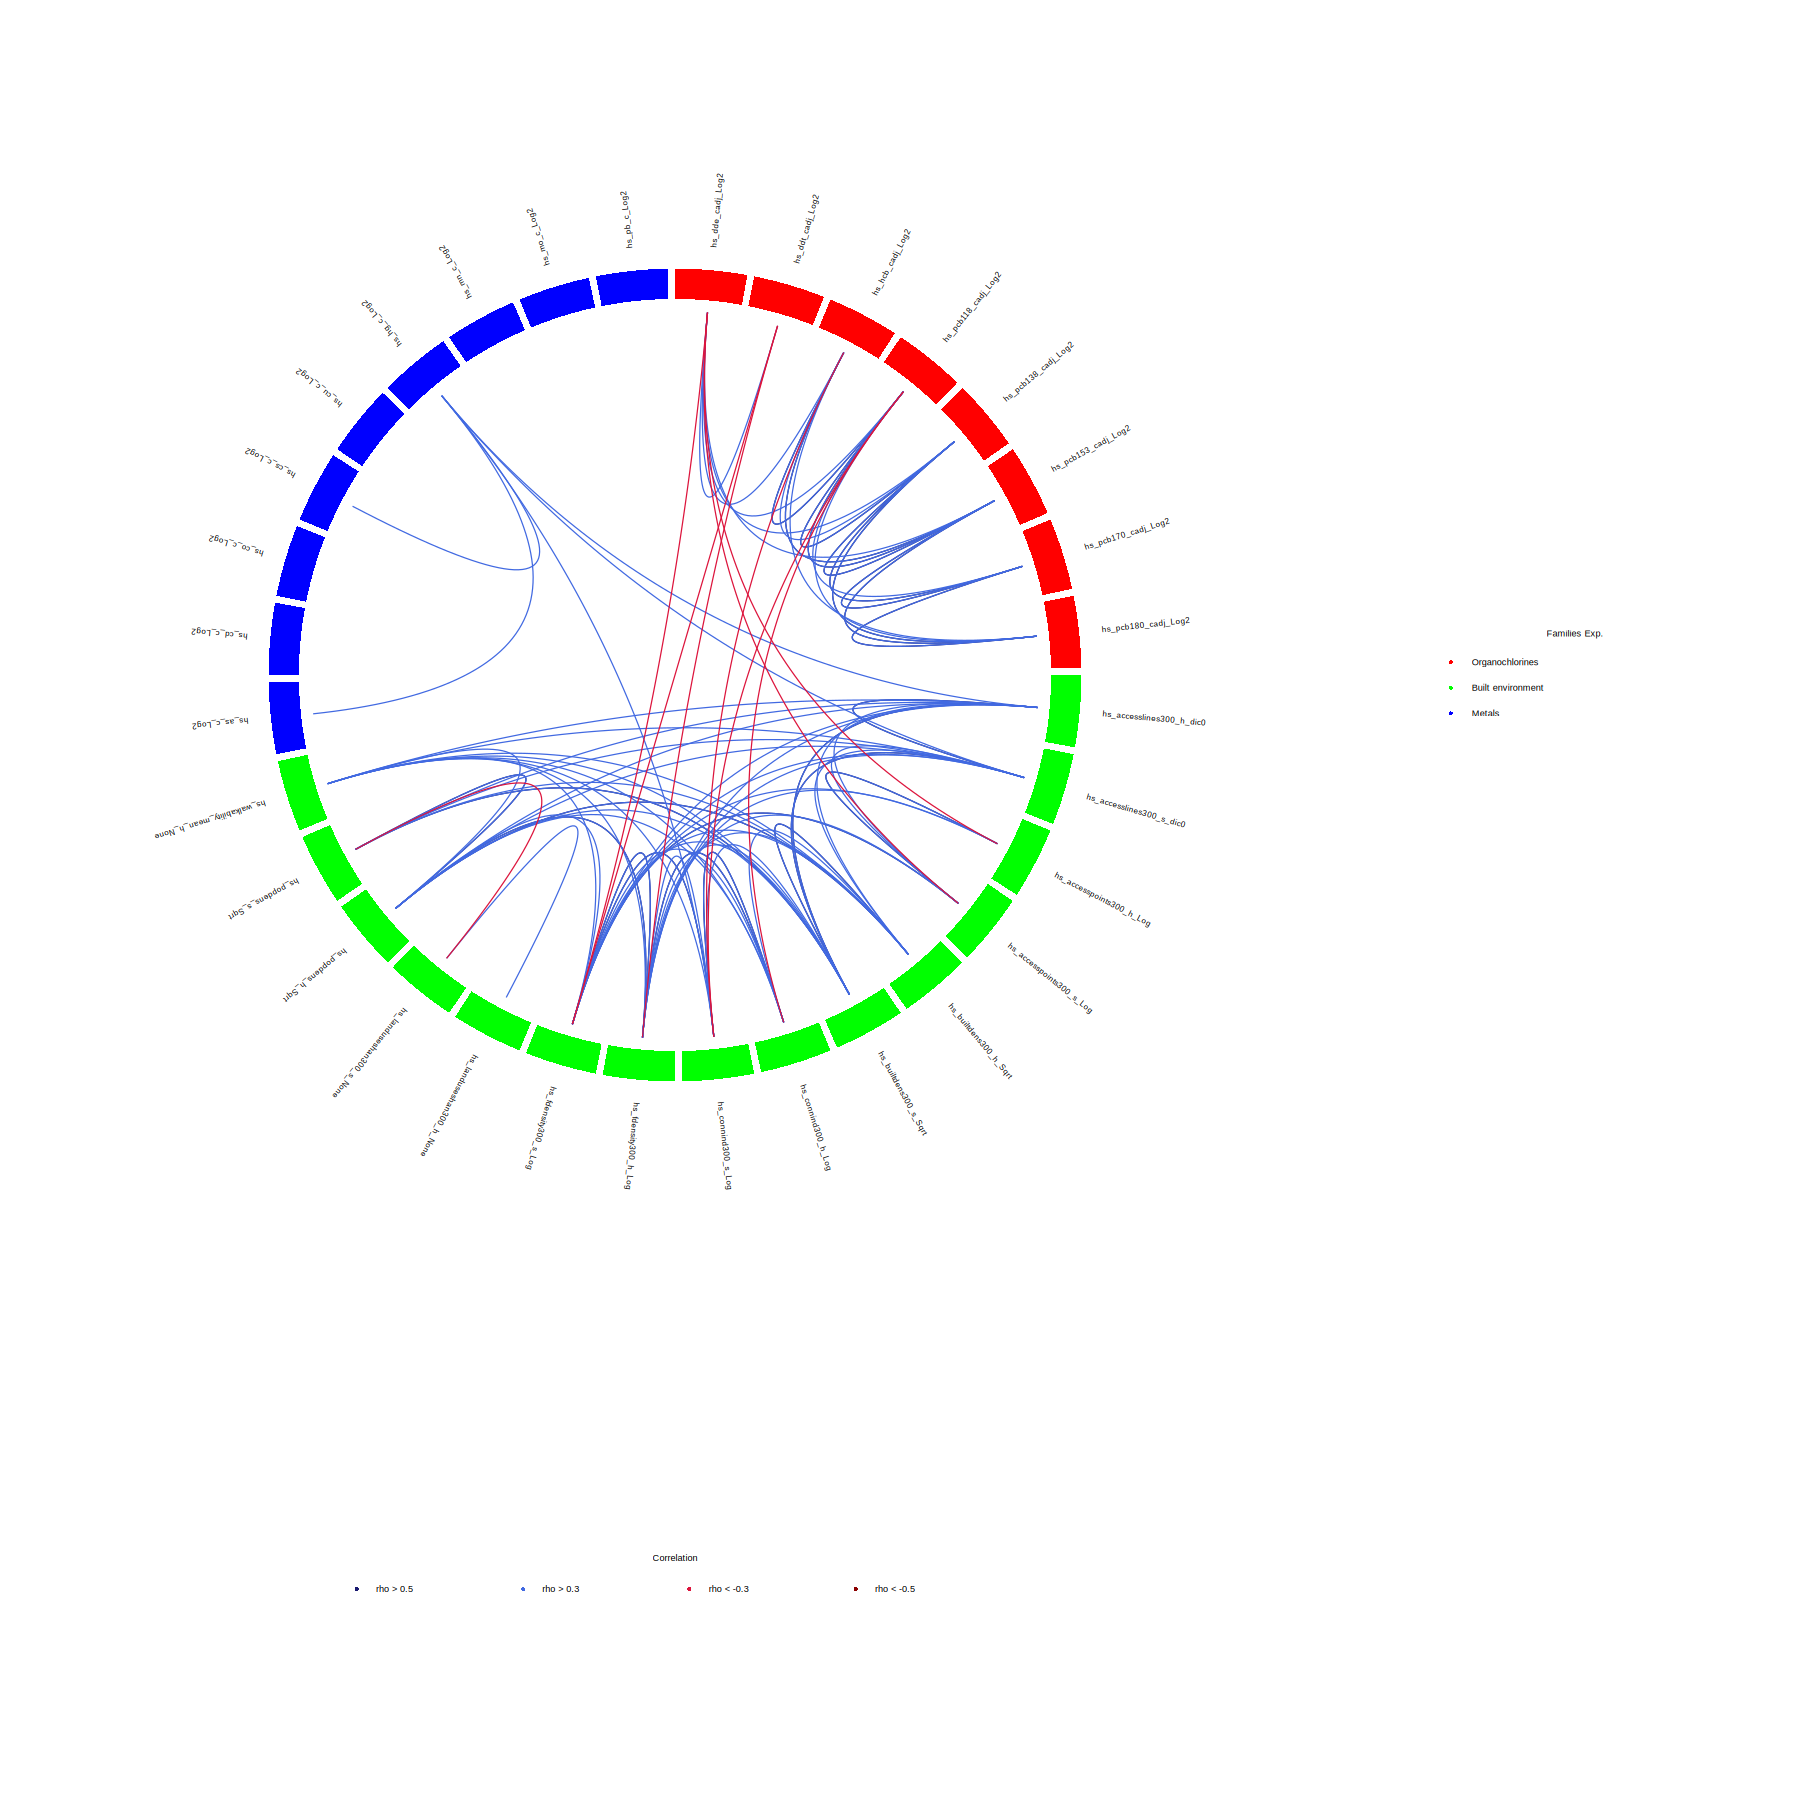

In [ ]:
options(repr.plot.width=15, repr.plot.height=15)
rexposome::plotCorrelation(exp_cor, type = "circos")

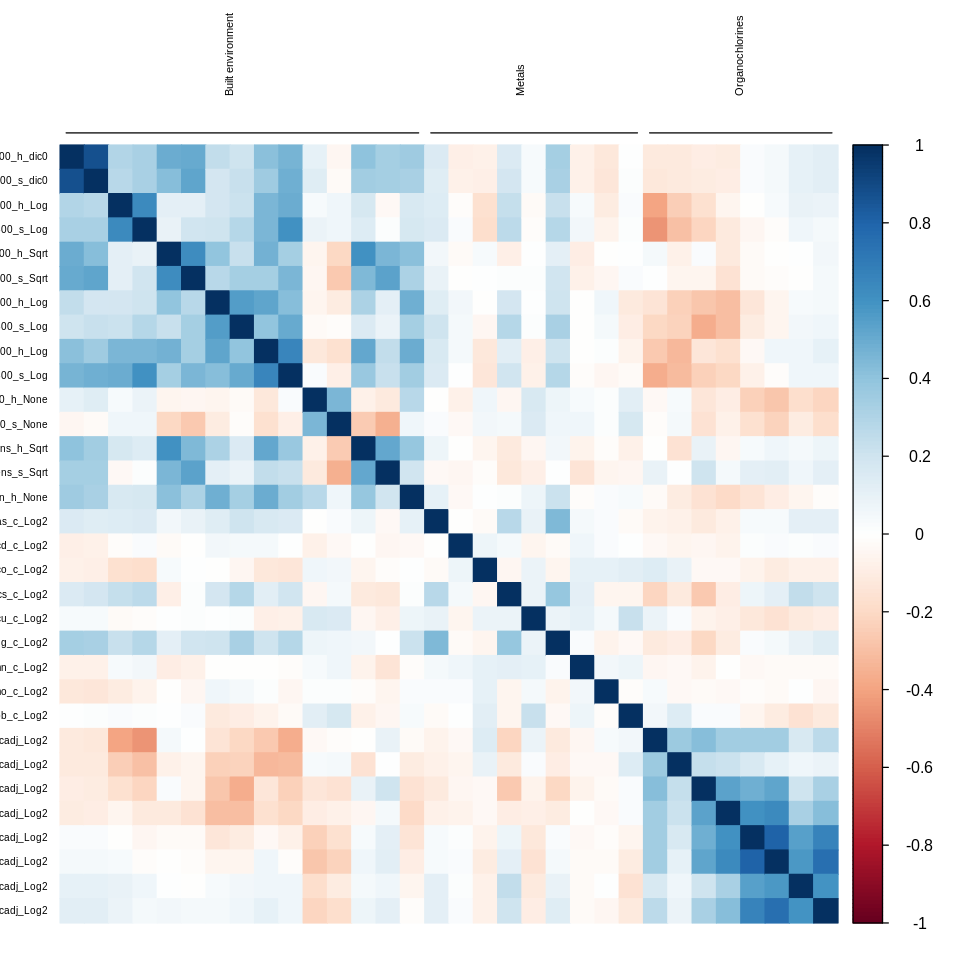

In [ ]:
options(repr.plot.width=8, repr.plot.height=8)
rexposome::plotCorrelation(exp_cor, type = "matrix")


### **3.3.- Principal Component Analysis (PCA)**

PCA is an unsupervised machine learning algorithm used for exploratory analysis and to reduce the dimensionality of data. To apply this analysis it is necessary that the exposures are previously standardised, for this the `rexposome` package has the `rexposome::standardize` function that prepares our data to later apply the PCA using the `rexposome::pca` function. After applying the PCA we can visualise our analysis using the `rexposome::plotPCA` function.

In [ ]:
dplyr::glimpse(exp)

Formal class 'ExposomeSet' [package "rexposome"] with 7 slots
  ..@ assayData        :<environment: 0x59adfc2d7260> 
  ..@ phenoData        :Formal class 'AnnotatedDataFrame' [package "Biobase"] with 4 slots
  ..@ featureData      :Formal class 'AnnotatedDataFrame' [package "Biobase"] with 4 slots
  ..@ experimentData   :Formal class 'MIAME' [package "Biobase"] with 13 slots
  ..@ annotation       : chr(0) 
  ..@ protocolData     :Formal class 'AnnotatedDataFrame' [package "Biobase"] with 4 slots
  ..@ .__classVersion__:Formal class 'Versions' [package "Biobase"] with 1 slot


In [ ]:
# We standardise the exposure variables of our exp object.
exp_std <- rexposome::standardize(exp, method = "normal")
exp_std

Warning message in rexposome::standardize(exp, method = "normal"):
“Given categorical exposures.”
Warning message in rexposome::standardize(exp, method = "normal"):
“Categorical exposures will not be standardized.”


Object of class 'ExposomeSet' (storageMode: environment)
 . exposures description:
    . categorical:  2 
    . continuous:  30 
 . exposures transformation:
    . categorical: 0 
    . transformed: 0 
    . standardized: 30 
    . imputed: 0 
 . assayData: 32 exposures 1301 individuals
    . element names: exp 
    . exposures: hs_accesslines300_h_dic0, ..., hs_popdens_s_Sqrt 
    . individuals: 1, ..., 998 
 . phenoData: 1301 individuals 13 phenotypes
    . individuals: 1, ..., 998 
    . phenotypes: hs_zbmi_who, ..., hs_child_age_None 
 . featureData: 32 exposures 17 explanations
    . exposures: hs_accesslines300_h_dic0, ..., hs_popdens_s_Sqrt 
    . descriptions: Family, ..., .imp 
experimentData: use 'experimentData(object)'
Annotation:  

In [ ]:
# We apply the PCA to our new standardised object exp_std
exp_pca <- rexposome::pca(exp_std)
exp_pca

Object of class 'ExposomePCA' (storageMode: environment)
 . num. prin. components: 10 
 . assayData: 32 exposures 1301 samples
    . element names: exp 
    . exposures: hs_accesslines300_h_dic0, ..., hs_popdens_s_Sqrt 
    . samples: 1, ..., 998 
 . phenoData: 1301 samples 13 phenotypes
    . samples: 1, ..., 998 
    . phenotypes: hs_zbmi_who, ..., hs_child_age_None 
 . featureData: 32 exposures 17 explanations
    . exposures: hs_accesslines300_h_dic0, ..., hs_popdens_s_Sqrt 
    . descriptions: Family, ..., .imp 

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the rexposome package.
  Please report the issue to the authors.”


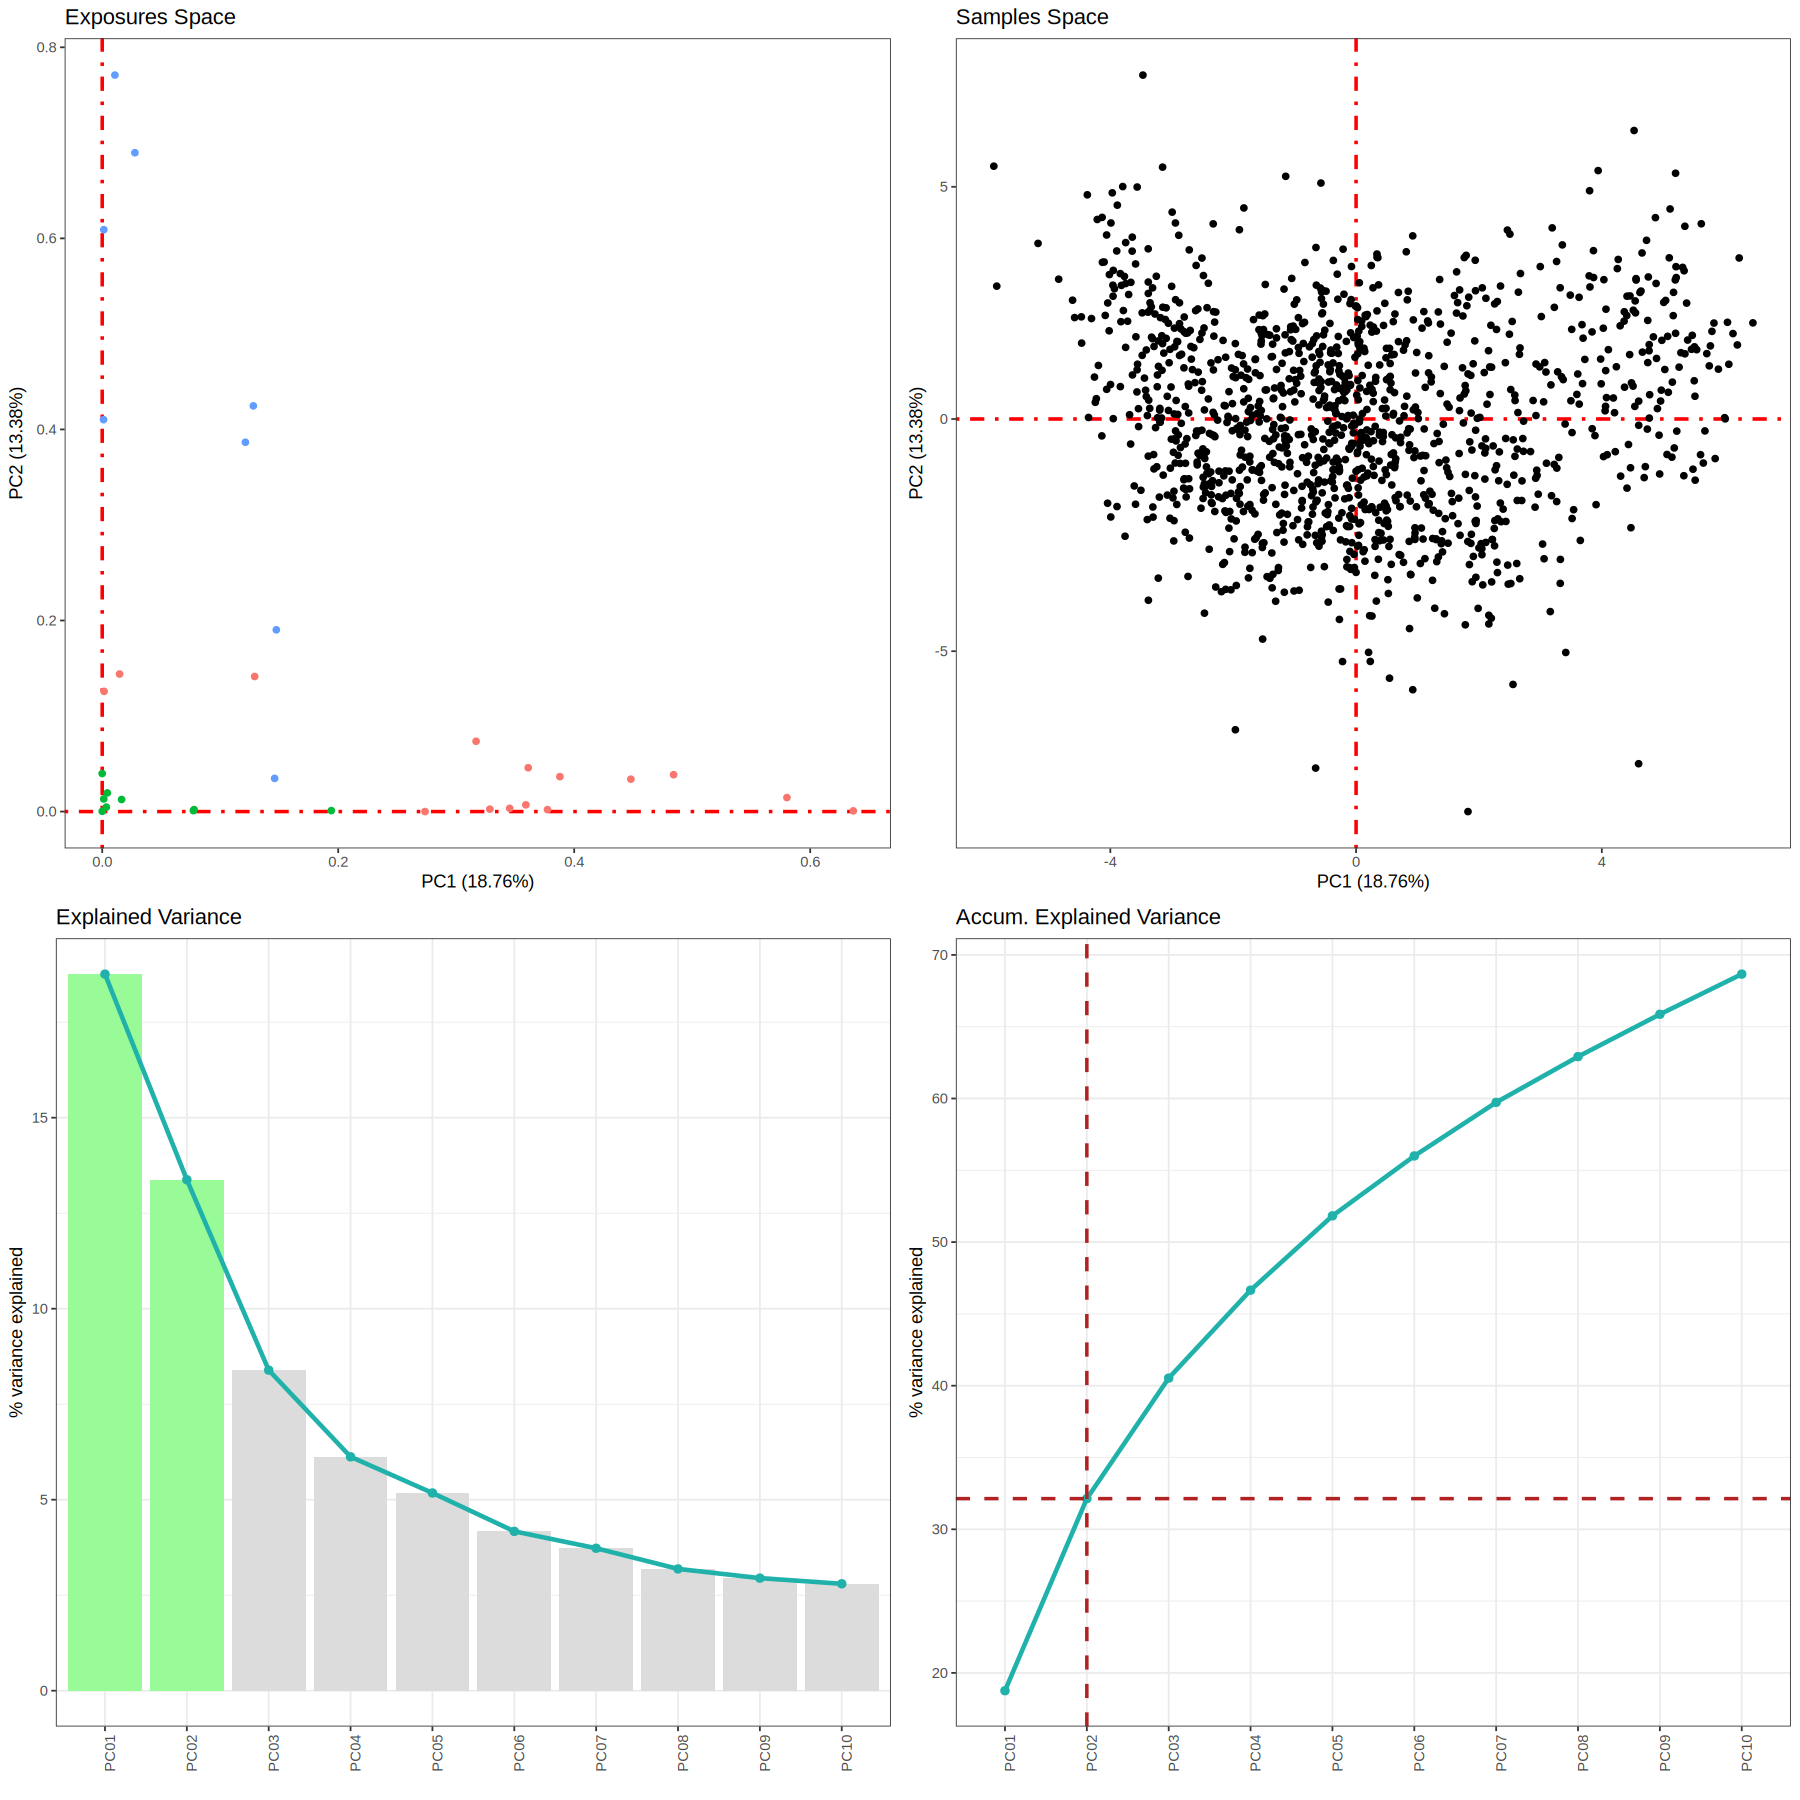

In [ ]:
# We visualise the results of the PCA
rexposome::plotPCA(exp_pca, set = "all")

***PCA Interpretation***

* **Exposures Space:** This plot represents the variability among the different exposures (i.e., the features or input variables). Each point in this space corresponds to a specific exposure. The position of each point on the PC1 and PC2 axes indicates how much variability of that feature is captured in those two principal components.

* **Samples Space:** This plot represents the variability among the different samples or subjects. Each point represents an observation (individuals in our example), and its position on the PC1 and PC2 axes indicates how much of the total variability of that sample is described by those two principal components.

* **Explained Variance:** This bar chart shows the percentage of the dataset’s total variance that is explained by each individual principal component. The first component (PC1) usually explains the largest portion of the variability, followed by the second (PC2), and so on. The height of each bar indicates how much variance each component explains.

* **Accum. Explained Variance:** This plot indicates how much total variability has been captured after summing each successive principal component. For example, the variance explained by PC1 + PC2 together, then PC1 + PC2 + PC3, and so on.

In **summary**, we can conclude from our **PCA** analysis:

**1.** PC1 explains 18.76% of the total variance, while PC2 explains 13.39%.  
**2.** The exposures (exposome features) cluster in specific regions in the exposure space, indicating that some features are similar to each other.  
**3.** The individuals in the sample space cluster densely around a central area, with some groups of points scattered, which could indicate possible patterns within the data (clusters).  








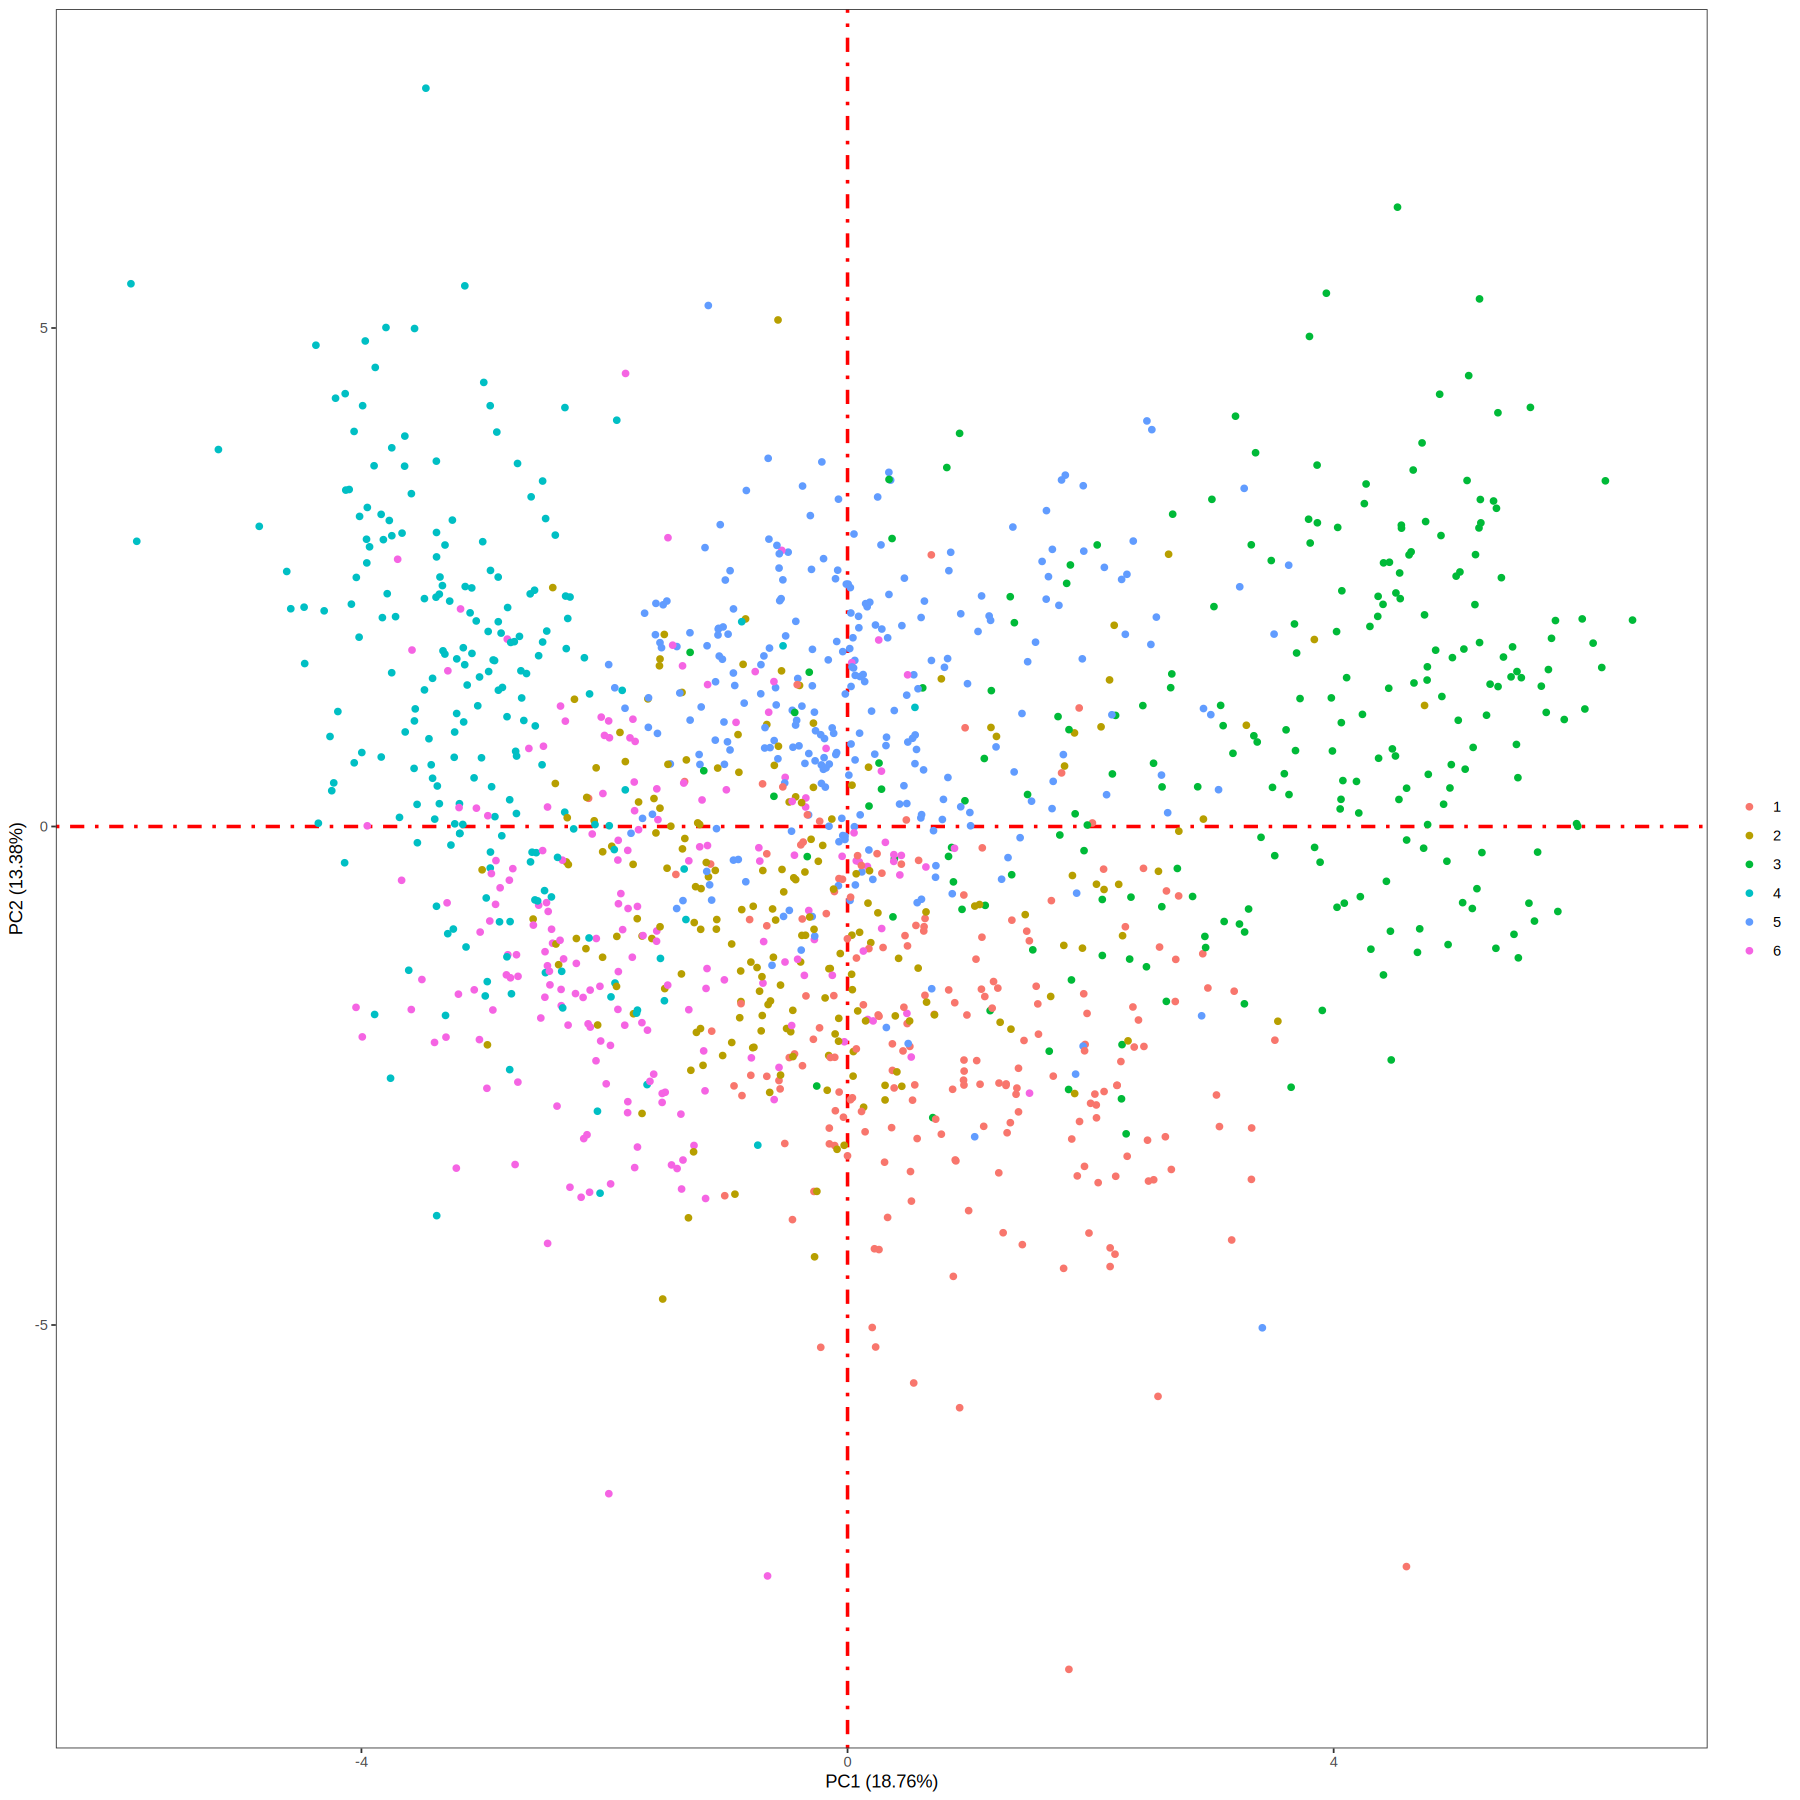

In [ ]:
rexposome::plotPCA(exp_pca, set = "samples", phenotype = "h_cohort")

**PCA interpretation - cohort**

In the graph we can see that the observations of the different cohorts overlap to a large extent, but there are also areas where certain observations tend to cluster more densely. Although we see some clustering or grouping of observations, there is significant overlap between the points, **which may indicate that differences between cohorts are not the main sources of variation in this dataset**. This type of graph is useful to visualise how the samples relate to each other in terms of their variability and how they are distributed in terms of a category of interest, in this case the cohort variable.

## **4.- Exposome association analysis** <a name="association"></a>
Once the exposome variables we want to study have been explored and described, we can look at the association between the different exposures and health outcomes using different approaches.


### **4.1.- Exposome-Wide association analysis (ExWAS)**

The ExWAS method is an approach that allows us to deal with high-dimensionality data. This method tests the association of each of the exposures with the health outcome of interest, adjusting for confounding variables (but not for co-exposure effects), and additionally allows us to control for multiple testing. In order to control for multiple testing, we need to compute the effective number of tests (considering correlation among predictors) and apply a p-value correction method. The ExWAS method can be applied through the `rexposome::exwas` function.

In [ ]:
exwas <- rexposome::exwas(exp, formula = hs_zbmi_who ~ h_cohort + e3_sex_None + e3_yearbir_None, family = "gaussian")
# Arguments:
# - exp: ExposomeSet with the exposures and, in its phenotype data, the outcome and the covariates.
# - formula: outcome ~ covariates. exwas() fits one regression per exposure, adding each exposure to this
#   model, so the effects are adjusted for the covariates but NOT for the other exposures.
# - family = "gaussian": linear regression for a continuous outcome (use "binomial" for 0/1 outcomes).
# - tef = TRUE (default): also computes the threshold for the effective number of tests (next cell).
exwas

An object of class 'ExWAS'

       ~ hs_zbmi_who h_cohort + e3_sex_None + e3_yearbir_None 

Tested exposures:  32 
Threshold for effective tests (TEF):  2.58e-03 
 . Tests < TEF: 1 
Robust standar errors: Computed

In [ ]:
# We obtain the threshold for the effective number of tests (TEF), to account for multiple testing.
# The TEF is a significance THRESHOLD, not an adjusted p-value, and it does NOT control the FDR.
# rexposome estimates the effective number of independent tests (Meff) from the eigenvalues of the
# correlation matrix of the exposures, and applies a Sidak correction: TEF = 1 - (1 - 0.05)^(1/Meff).
# This is a Bonferroni-type correction: it controls the family-wise error rate (FWER), i.e. the probability
# of at least one false positive. It is less strict than Bonferroni (0.05/32 = 0.0016) because correlated
# exposures count as fewer independent tests. The p-values reported by exwas() are raw (unadjusted).
rexposome::tef(exwas)

# Effective number of tests implied by the threshold
log(1 - 0.05) / log(1 - rexposome::tef(exwas))

[1] 0.002578593

[1] 19.86631

In [ ]:
rexposome::extract(exwas)

In [ ]:
exwas_result <- round(as.data.frame(extract(exwas)),6)
View(exwas_result)

,pvalue,effect,X2.5,X97.5
,<dbl>,<dbl>,<dbl>,<dbl>
hs_pcb153_cadj_Log2,0.000000,-0.601448,-0.700145,-0.502751
hs_pcb170_cadj_Log2,0.000000,-0.267357,-0.316641,-0.218073
hs_pcb138_cadj_Log2,0.000000,-0.394363,-0.471809,-0.316917
hs_pcb180_cadj_Log2,0.000000,-0.410830,-0.492683,-0.328976
hs_hcb_cadj_Log2,0.000000,-0.266632,-0.329649,-0.203616
hs_dde_cadj_Log2,0.000000,-0.378716,-0.471500,-0.285933
hs_pcb118_cadj_Log2,0.000000,-0.244863,-0.319822,-0.169905
hs_accesslines300_s_dic0,0.000000,0.530678,0.353632,0.707725
hs_accesslines300_h_dic0,0.000000,0.514561,0.338675,0.690448


In [ ]:
# We select the exposures that have a p-value lower than the tef
exwas_result[exwas_result$pvalue<tef(exwas),]

,pvalue,effect,X2.5,X97.5
,<dbl>,<dbl>,<dbl>,<dbl>
hs_pcb153_cadj_Log2,0.000000,-0.601448,-0.700145,-0.502751
hs_pcb170_cadj_Log2,0.000000,-0.267357,-0.316641,-0.218073
hs_pcb138_cadj_Log2,0.000000,-0.394363,-0.471809,-0.316917
hs_pcb180_cadj_Log2,0.000000,-0.410830,-0.492683,-0.328976
hs_hcb_cadj_Log2,0.000000,-0.266632,-0.329649,-0.203616
hs_dde_cadj_Log2,0.000000,-0.378716,-0.471500,-0.285933
hs_pcb118_cadj_Log2,0.000000,-0.244863,-0.319822,-0.169905
hs_accesslines300_s_dic0,0.000000,0.530678,0.353632,0.707725
hs_accesslines300_h_dic0,0.000000,0.514561,0.338675,0.690448


Using the `rexposome::plotExwas` function we can visualise the exwas results using a Manhattan plot. This type of plot is particularly useful as it allows us to visualise the statistical association through the p-value grouped by the different exposure families. It is important to mention that the Manhattan plot only shows the p-values, but no metric of the effect of the exposures is shown.

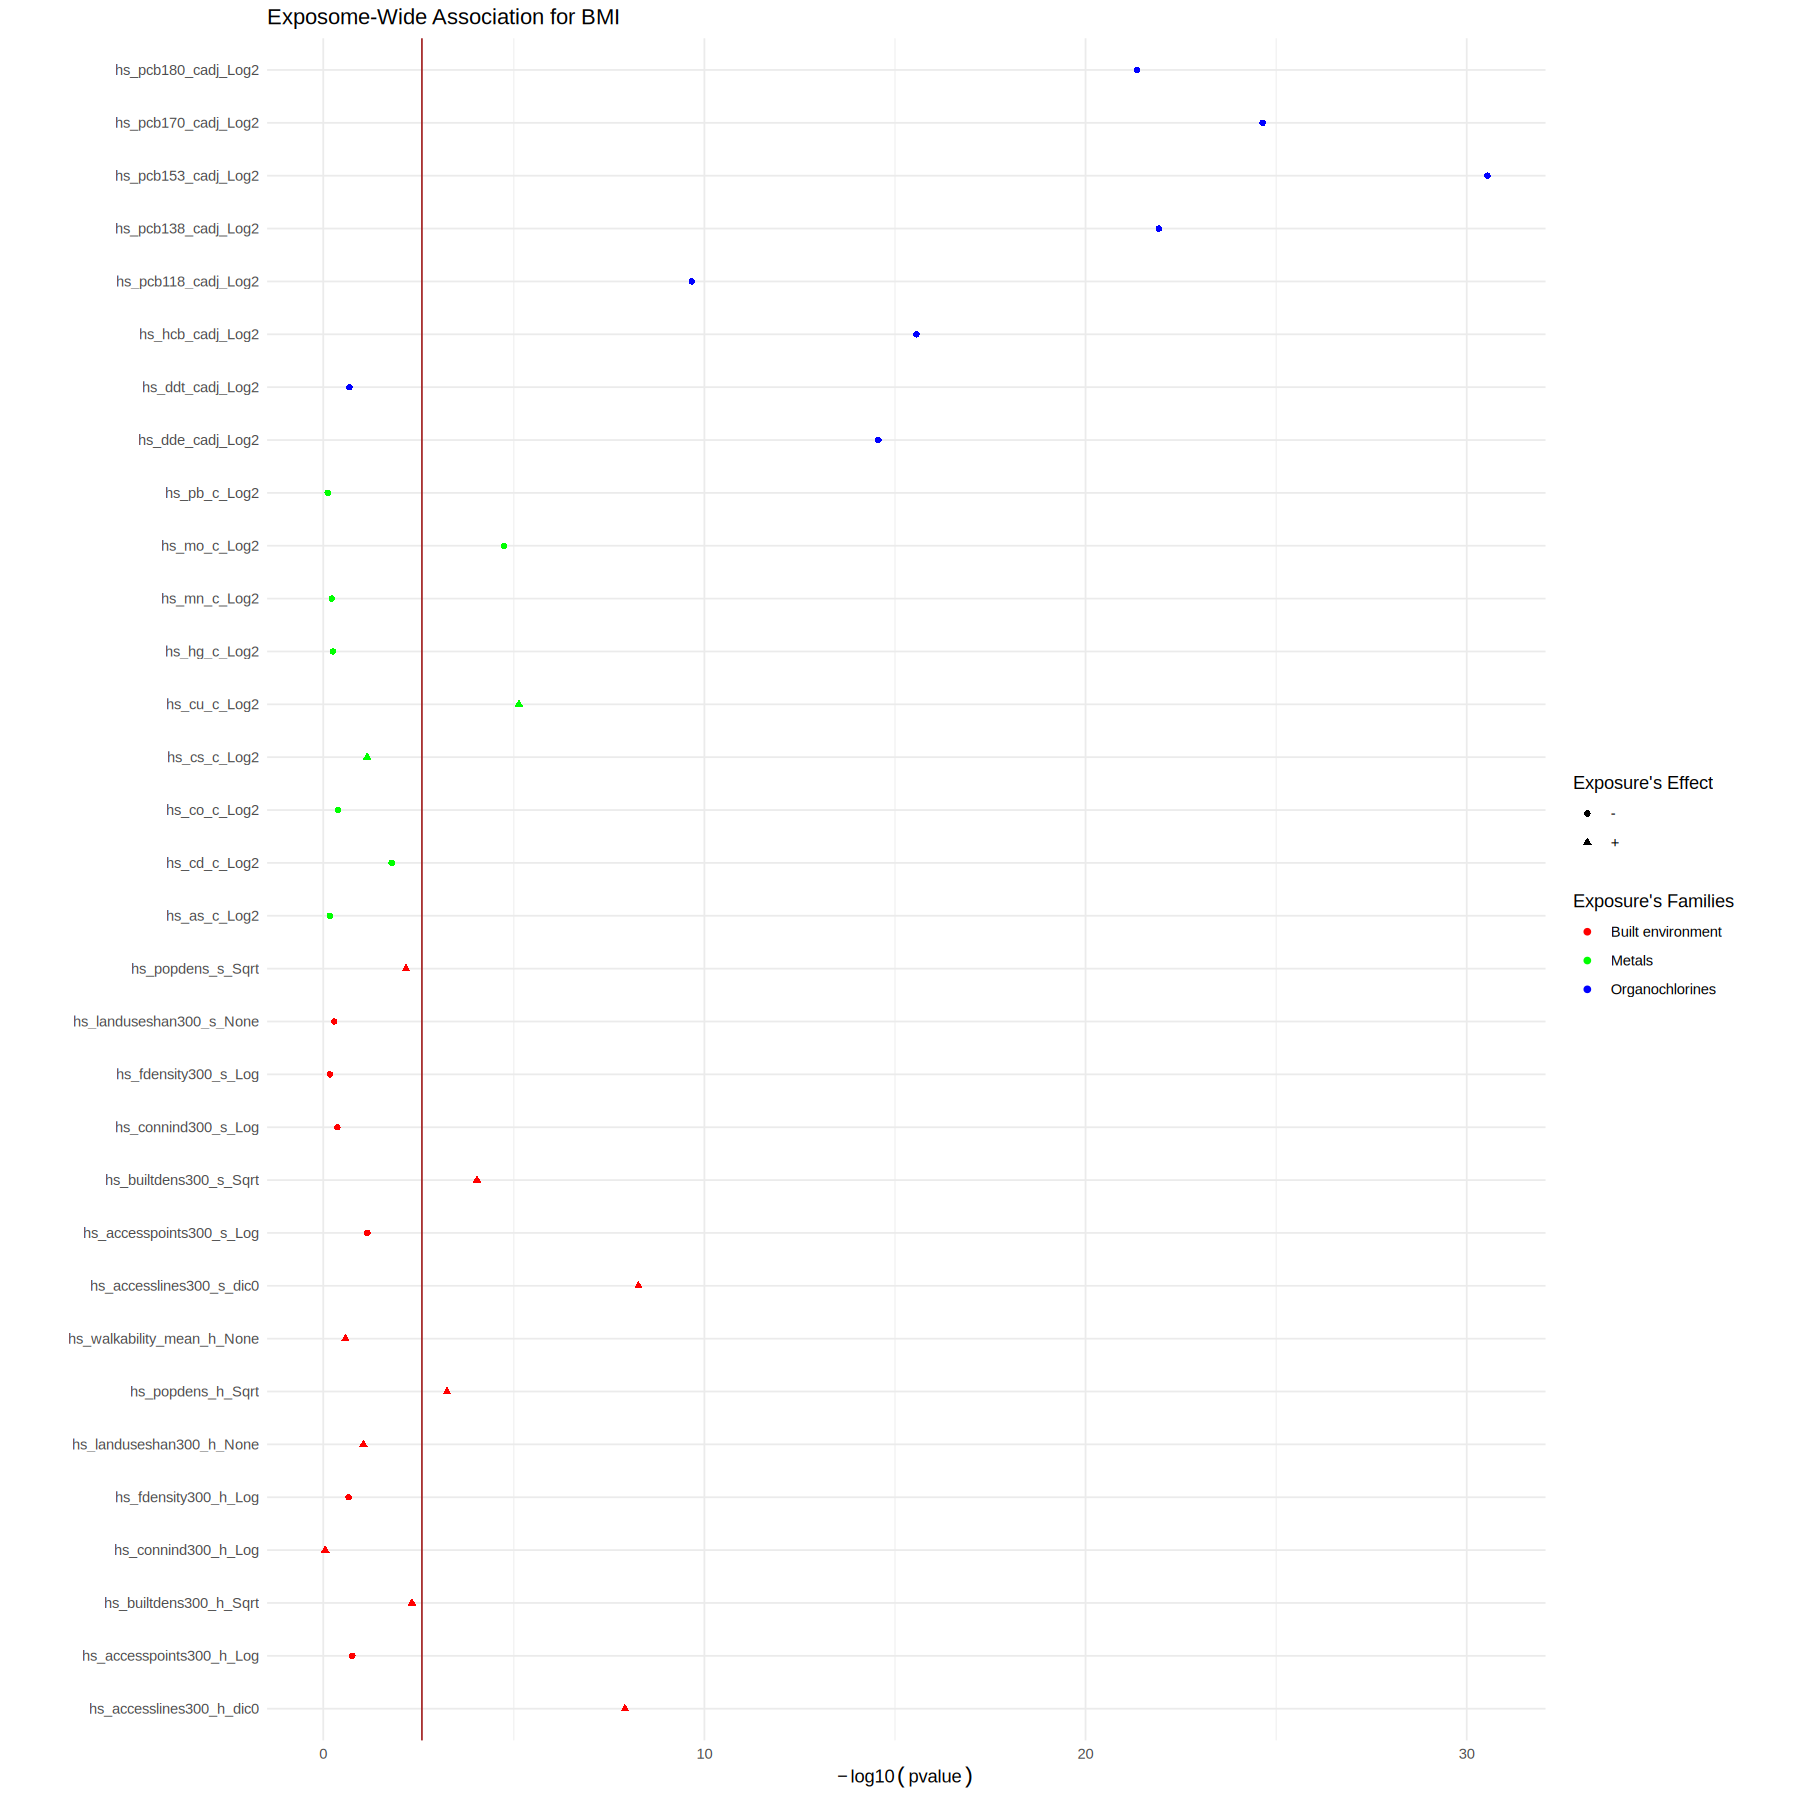

In [ ]:
clr <- rainbow(length(familyNames(exp)))
names(clr) <- familyNames(exp)

rexposome::plotExwas(exwas, color = clr, show.effective = TRUE,
          exp.order=expo.list) +
  ggtitle("Exposome-Wide Association for BMI")

*   **Question 1:** <font color='red'> **Is ExWas analysis controlled by multiple testing?** </font> <font color='green'> **Yes, but through a significance threshold rather than adjusted p-values. `exwas()` reports raw p-values and, with `tef = TRUE` (default), a threshold based on the effective number of tests (a Sidak correction on the number of independent tests, which accounts for the correlation among exposures). Exposures with a p-value below this threshold are significant while controlling the family-wise error rate (FWER). Alternatively, the p-values can be adjusted with `p.adjust()`, using Bonferroni (FWER) or Benjamini-Hochberg (false discovery rate, FDR), which is less conservative.** </font>

*   **Question 2:** <font color='red'> **If a participant is exposed to PCB153, can we say that if he/she is also exposed to PCB118, will his/her BMI be reduced?** </font> <font color='green'> **ExWAS does not tell us anything about co-exposure effects and co-ocurrence of events. It just looks at the association between each individual exposure and the health outcome (adjusted for potential confounders) independently** </font>


Using the `rexposome::plotEffect` function we can see the estimated effect for a given model, in this case the effect of postnatal exposures of the selected families (Built environment, Metals, Organochlorines) on BMI.

Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the rexposome package.
  Please report the issue to the authors.”


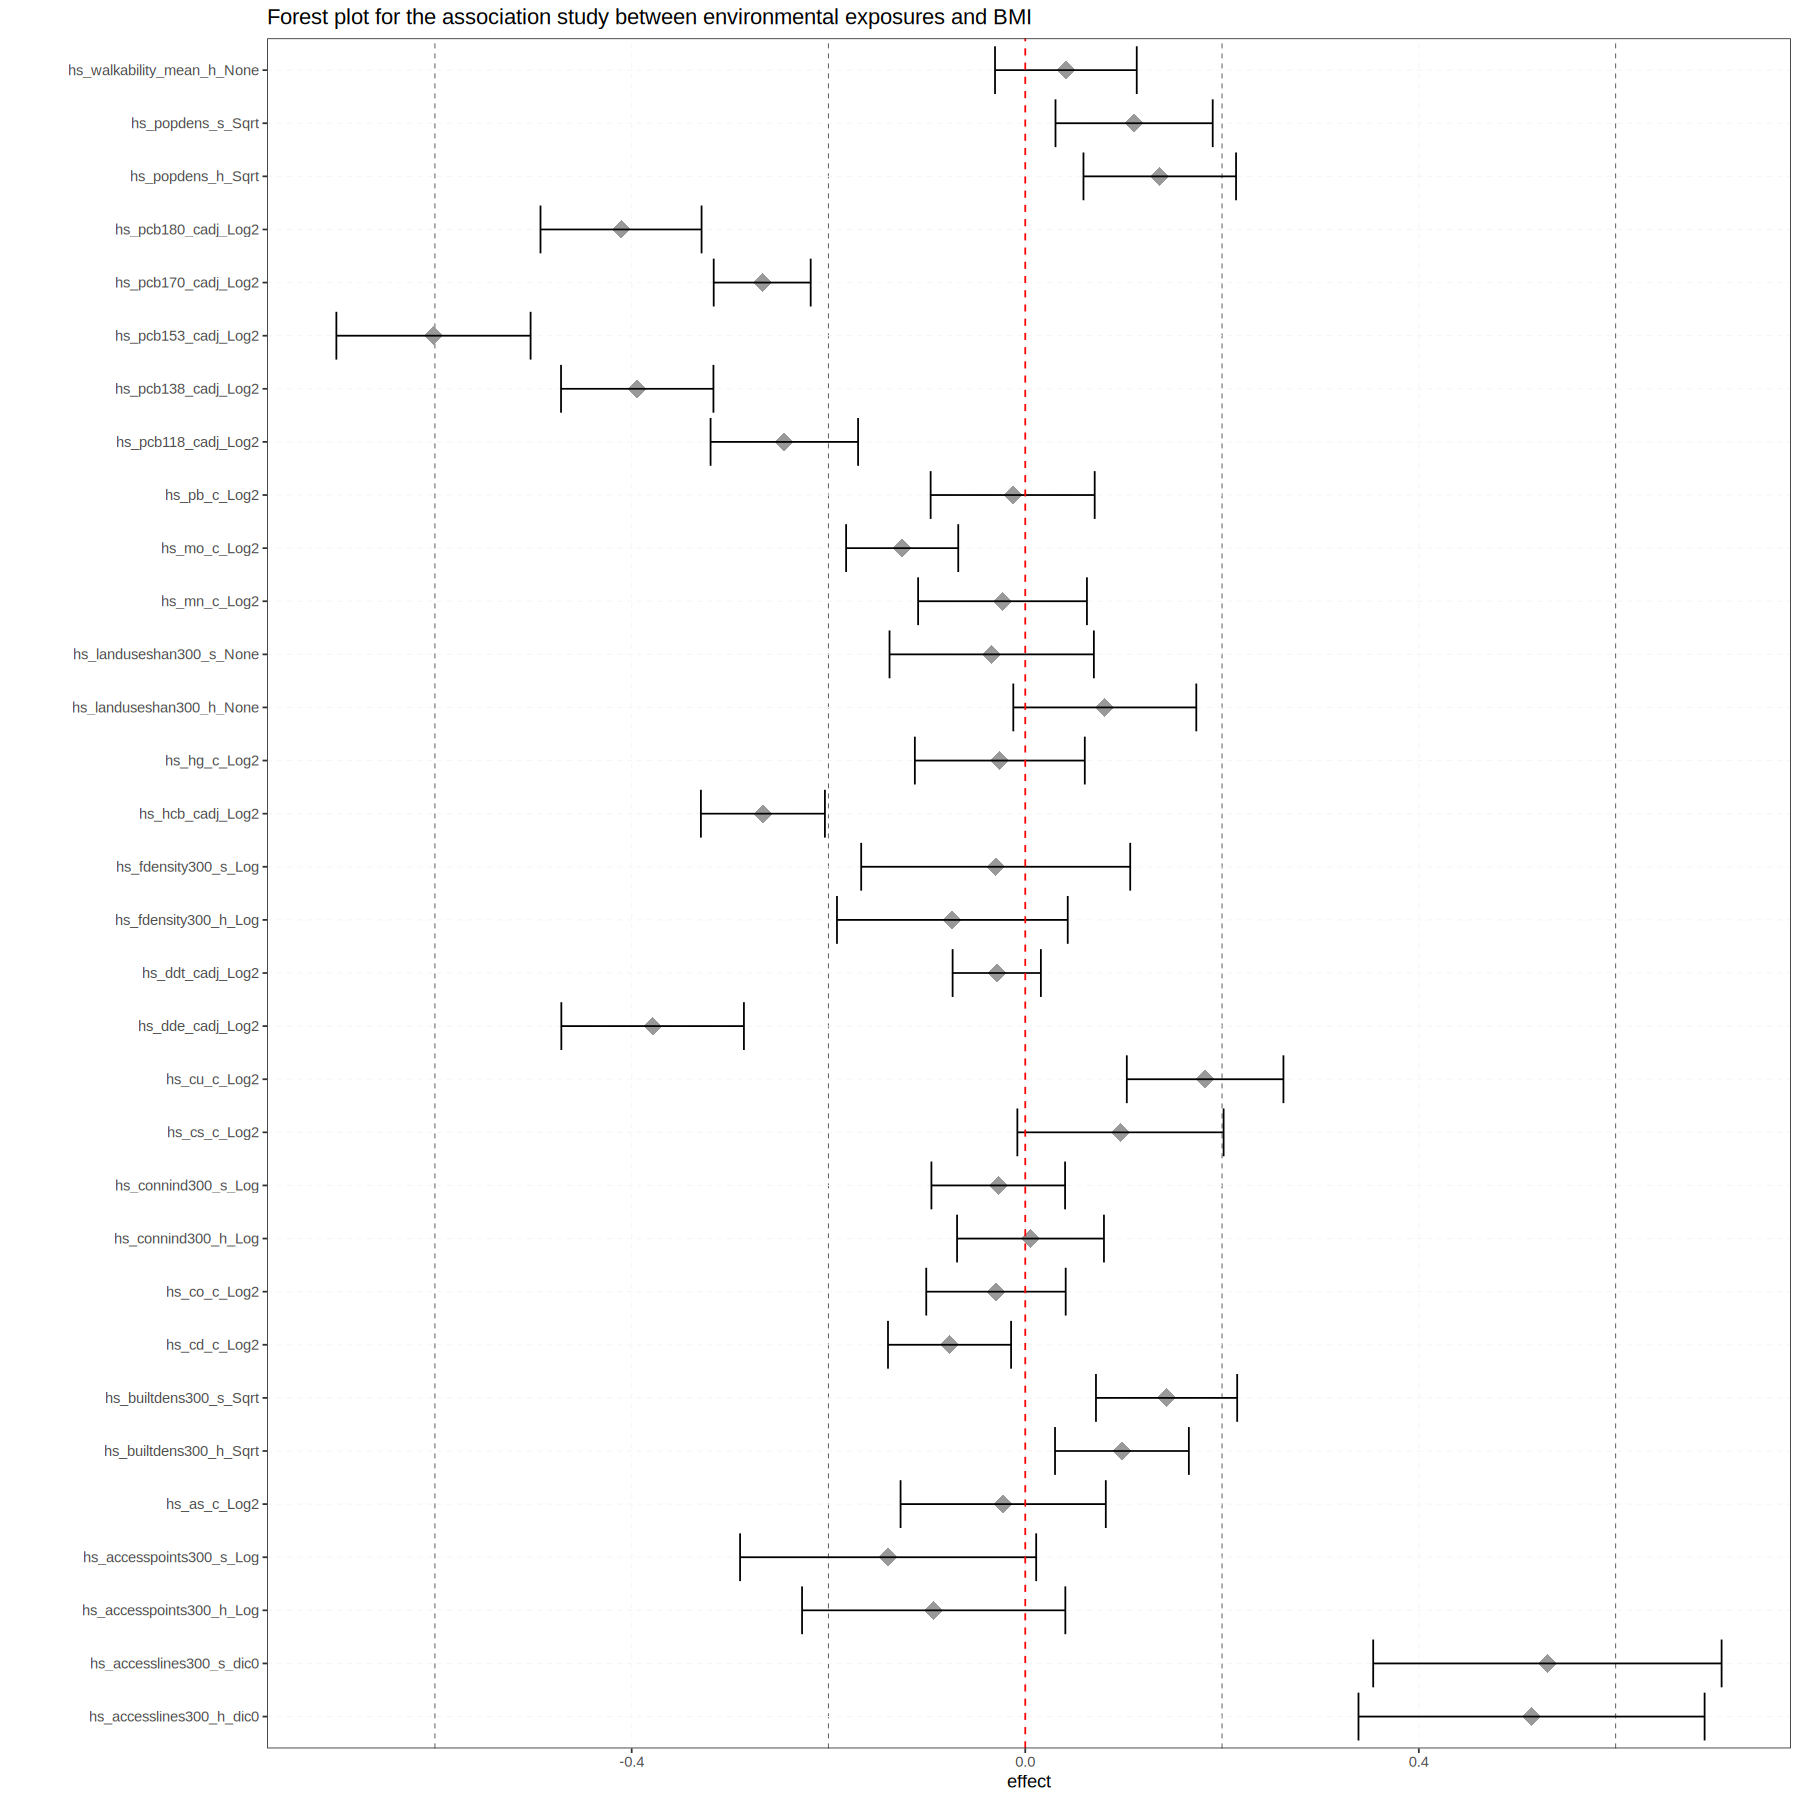

In [ ]:
rexposome::plotEffect(exwas) + ggtitle("Forest plot for the association study between environmental exposures and BMI") + geom_vline(xintercept = 0, linetype = "dashed", color = "red")

Another way to visualise the ExWAS results is by means of a volcano-plot, this type of graph is more illustrative as it combines the visualisation techniques taught above. This type of graph shows the p-value and effect size of the different exposures with the studied health outcome (BMI). The volcano-plot can be generated using the function `rexposome::plotVolcano`.

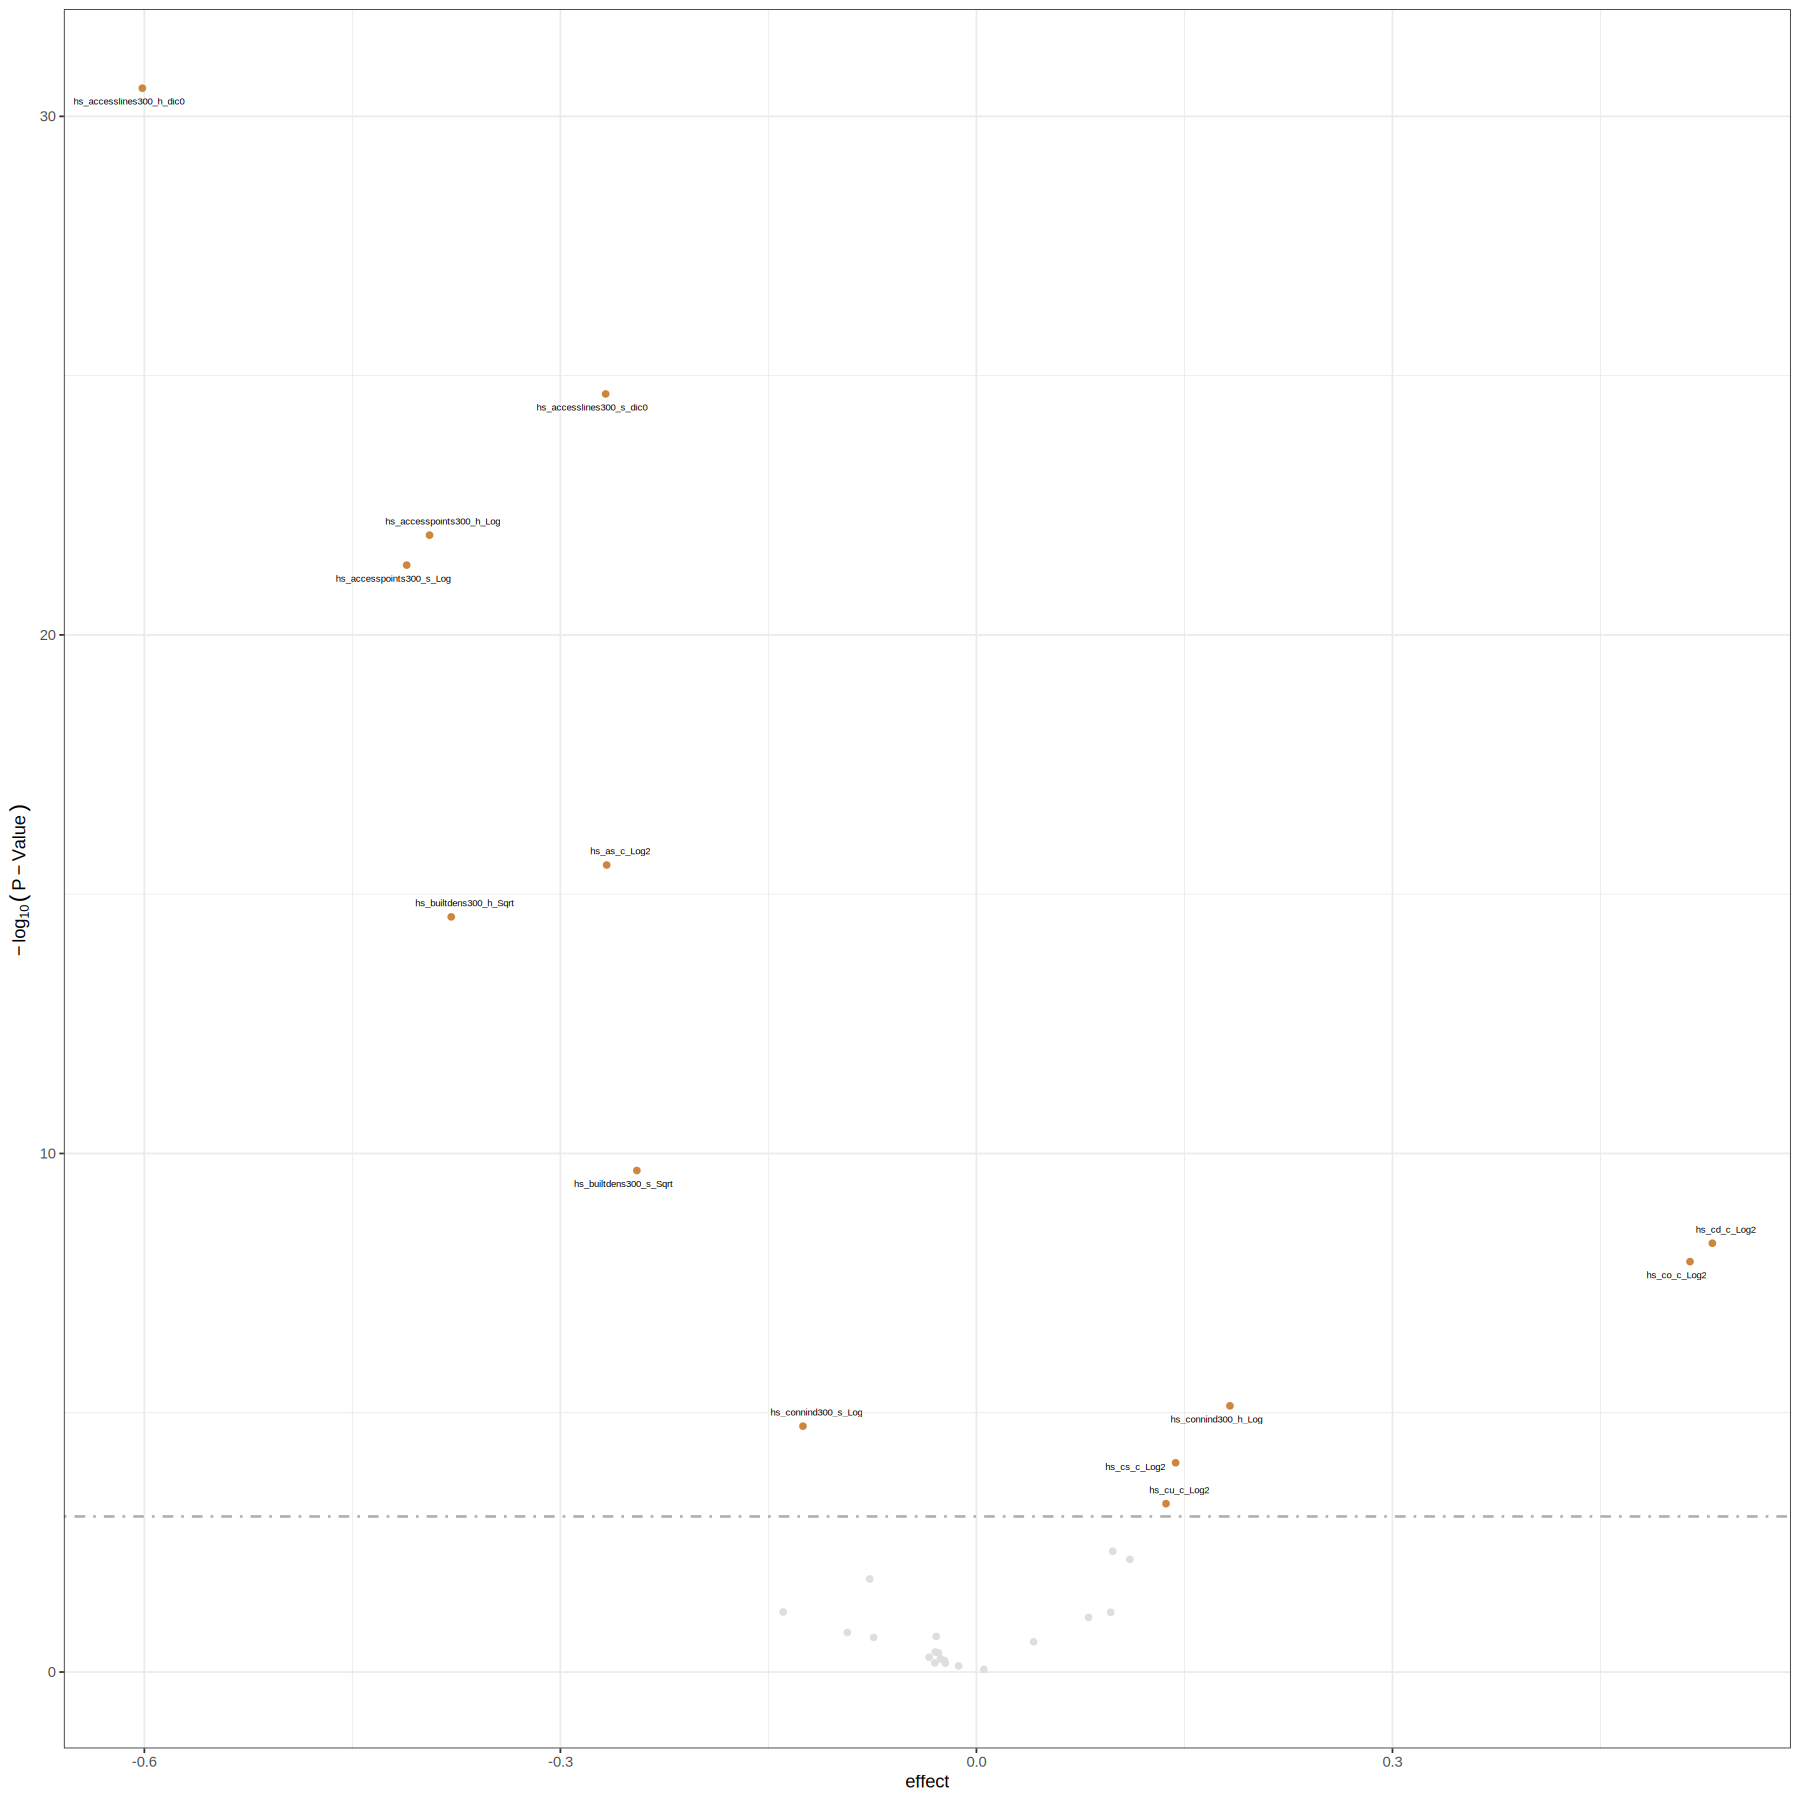

In [ ]:
rexposome::plotVolcano(exwas)

### **4.2.- Methods for variable selection**
Variable selection techniques are generally performed automatically by algorithms (widely used in high dimensional problems). In principle these techniques allow us to discriminate those variables or exposures that are not associated with a health outcome. These variable selection methods are implemented in other libraries, some of them are: `MASS` (stepwise), `glmnet` and `caret` (elastic net) and `partDSA` (DSA).


* **Stepwise selection:** This selection technique uses a sequence of steps to allow predictor variables to enter or exit a regression model one at a time (generating multiple models). Often, this procedure converges on a subset of variables. In this tutorial we use `MASS::stepAIC()`, which compares models with the Akaike Information Criterion (AIC) instead of p-values. Entry and exit criteria are commonly based on the significance of the p-value. The significance of the characteristics is ranked according to their individual ability to explain the variation in the outcome.






In [ ]:
set.seed(234) # we need to define a seed to find reproducible results everytime we run the algorithm
full.model <- lm(hs_zbmi_who ~ h_cohort + e3_sex_None + e3_yearbir_None +
                   hs_accesslines300_h_dic0 + hs_accesspoints300_h_Log +
                   hs_builtdens300_h_Sqrt + hs_connind300_h_Log +
                   hs_fdensity300_h_Log + hs_landuseshan300_h_None +
                   hs_popdens_h_Sqrt + hs_walkability_mean_h_None +
                   hs_accesslines300_s_dic0 + hs_accesspoints300_s_Log +
                   hs_builtdens300_s_Sqrt + hs_connind300_s_Log +
                   hs_fdensity300_s_Log + hs_landuseshan300_s_None +
                   hs_popdens_s_Sqrt + hs_as_c_Log2 +
                   hs_cd_c_Log2 + hs_co_c_Log2 + hs_cs_c_Log2 +
                   hs_cu_c_Log2 + hs_hg_c_Log2 + hs_mn_c_Log2 +
                   hs_mo_c_Log2 + hs_pb_c_Log2 + hs_dde_cadj_Log2 +
                   hs_ddt_cadj_Log2 + hs_hcb_cadj_Log2+
                   hs_pcb118_cadj_Log2 + hs_pcb138_cadj_Log2+
                   hs_pcb153_cadj_Log2 + hs_pcb170_cadj_Log2 +
                   hs_pcb180_cadj_Log2,
                 data = data)

In [ ]:
step.model <- stepAIC(full.model, direction = "both",
                      trace = FALSE,
                      scope = list(lower = ~ h_cohort + e3_sex_None + e3_yearbir_None))
# Arguments:
# - full.model: starting model, with the covariates and all the exposures.
# - direction = "both": at each step a variable may be removed from or added (back) to the model.
# - trace = FALSE: do not print every step.
# - scope: lower = smallest model allowed, so cohort, sex and year of birth are always kept (confounders).
# The algorithm stops when no removal or addition improves the AIC. Models are compared by AIC
# (each parameter costs 2 points of AIC), not by p-values.

In [ ]:
# inspect model results with the summary order
summary(step.model)


Call:
lm(formula = hs_zbmi_who ~ h_cohort + e3_sex_None + e3_yearbir_None + 
    hs_fdensity300_h_Log + hs_popdens_h_Sqrt + hs_accesspoints300_s_Log + 
    hs_cs_c_Log2 + hs_cu_c_Log2 + hs_hg_c_Log2 + hs_mo_c_Log2 + 
    hs_pb_c_Log2 + hs_dde_cadj_Log2 + hs_hcb_cadj_Log2 + hs_pcb118_cadj_Log2 + 
    hs_pcb153_cadj_Log2 + hs_pcb170_cadj_Log2, data = data)

Residuals:
    Min      1Q  Median      3Q     Max 
-4.6604 -0.6715 -0.0348  0.6512  3.5459 

Coefficients:
                         Estimate Std. Error t value Pr(>|t|)    
(Intercept)              -2.63227    1.41767  -1.857 0.063576 .  
h_cohort2                 0.50608    0.29397   1.722 0.085391 .  
h_cohort3                 1.34331    0.22622   5.938 3.71e-09 ***
h_cohort4                 0.88197    0.16891   5.222 2.07e-07 ***
h_cohort5                 0.76452    0.21720   3.520 0.000447 ***
h_cohort6                 0.55264    0.16886   3.273 0.001094 ** 
e3_sex_Nonemale           0.19688    0.05866   3.356 0.000814 ***
e3_ye

* **Elastic net:** This technique is based on the combination of LASSO and Ridge penalisation methods, with the aim of overcoming some of their limitations. Because in the presence of correlated variables LASSO tends to select one variable from a group and ignore the rest and Ridge keeps all of them with similar coefficients, a good compromise is achieved when using Elastic net. The penalty parameters are optimised using the cross-validation procedure (which can lead to problems of instability in the results). There are two type of parameters (lambda and alpha). Lambda sets the overall strength of the penalty: the larger it is, the more the coefficients shrink towards zero (lambda = 0 gives an ordinary, unpenalised regression). Alpha sets the mix between the two penalties: alpha = 0 is Ridge (L2 penalty), which shrinks all coefficients but keeps every variable in the model, alpha = 1 is LASSO (L1 penalty), which can set coefficients exactly to zero and so selects variables, and values in between give the Elastic net.We can follow two approaches when optimizing the penalty parameters:



1.   lambda min: The lambda with the lowest mean cross-validated error across the 10 folds.
2.   lambda 1-SE: The largest lambda (more penalty, fewer exposures) whose mean error does not exceed the minimum by more than one standard error (horizontal line).

**Lambda min keeps the exact minimum, even if in practice it is tied with more penalised lambdas. The 1-SE rule says: among all the models that cannot be told apart from the best one, choose the simplest. It has fewer exposures, a more stable selection and fewer false positives**. In exchange, the error is slightly higher and it may miss exposures with small but real effects.




In [ ]:
# We define the predictor variables of the model (basically all exposures and covariates).
x <- model.matrix(hs_zbmi_who ~ h_cohort + e3_sex_None + e3_yearbir_None +
                    hs_accesslines300_h_dic0 + hs_accesspoints300_h_Log +
                    hs_builtdens300_h_Sqrt + hs_connind300_h_Log +
                    hs_fdensity300_h_Log + hs_landuseshan300_h_None +
                    hs_popdens_h_Sqrt + hs_walkability_mean_h_None +
                    hs_accesslines300_s_dic0 + hs_accesspoints300_s_Log +
                    hs_builtdens300_s_Sqrt + hs_connind300_s_Log +
                    hs_fdensity300_s_Log + hs_landuseshan300_s_None +
                    hs_popdens_s_Sqrt + hs_as_c_Log2 +
                    hs_cd_c_Log2 + hs_co_c_Log2 + hs_cs_c_Log2 +
                    hs_cu_c_Log2 + hs_hg_c_Log2 + hs_mn_c_Log2 +
                    hs_mo_c_Log2 + hs_pb_c_Log2 + hs_dde_cadj_Log2 +
                    hs_ddt_cadj_Log2 + hs_hcb_cadj_Log2+
                    hs_pcb118_cadj_Log2 + hs_pcb138_cadj_Log2+
                    hs_pcb153_cadj_Log2 + hs_pcb170_cadj_Log2 +
                    hs_pcb180_cadj_Log2, data)[,-1]


In [66]:
# penalty factor: 0 = not penalised (the first 12 columns of x are the covariates: cohort, sex and year
# of birth dummies, always kept in the model), 1 = penalised (the 32 exposures)
pen.fac <- c(rep(0,12),rep(1,ncol(x)-12))

tg <- expand.grid(
  alpha  = c(0.25, 0.5, 0.75),       # From Ridge to Lasso
  lambda = 10 ^ seq(2, -.5, length = 10)    # lambda penalty
)

print(tg)
# alpha = 0 ⇒ Pure Ridge
# alpha = 1 ⇒ Pure Lasso
# 0 < alpha < 1 ⇒ Elastic Net

   alpha      lambda
1   0.25 100.0000000
2   0.50 100.0000000
3   0.75 100.0000000
4   0.25  52.7499706
5   0.50  52.7499706
6   0.75  52.7499706
7   0.25  27.8255940
8   0.50  27.8255940
9   0.75  27.8255940
10  0.25  14.6779927
11  0.50  14.6779927
12  0.75  14.6779927
13  0.25   7.7426368
14  0.50   7.7426368
15  0.75   7.7426368
16  0.25   4.0842387
17  0.50   4.0842387
18  0.75   4.0842387
19  0.25   2.1544347
20  0.50   2.1544347
21  0.75   2.1544347
22  0.25   1.1364637
23  0.50   1.1364637
24  0.75   1.1364637
25  0.25   0.5994843
26  0.50   0.5994843
27  0.75   0.5994843
28  0.25   0.3162278
29  0.50   0.3162278
30  0.75   0.3162278


In [ ]:
set.seed(123)
model <- train(x=x, y=data$hs_zbmi_who,
  method = "glmnet",
  trControl = trainControl(method = "cv", number = 10, search = "grid"),
  tuneGrid = tg,
  tuneLength = 25, penalty.factor=pen.fac
)
# Arguments:
# - x, y: predictors (covariates + exposures) and outcome.
# - method = "glmnet": elastic net, fitted with the glmnet package.
# - trControl: 10-fold cross-validation; search = "grid" evaluates every combination in tuneGrid.
# - tuneGrid = tg: combinations of alpha and lambda to evaluate (previous cell).
# - tuneLength = 25: only used when tuneGrid is NOT given, so here it has no effect.
# - penalty.factor = pen.fac: passed on to glmnet (0 = covariates always kept, 1 = exposures penalised).
# The best combination is the one with the lowest cross-validated RMSE (caret's default metric).

In [ ]:
# Best tuning parameter
model$bestTune

# Coefficient of the final model. You need
# to specify the best lambda
coef(model$finalModel, model$bestTune$lambda)

,alpha,lambda
,<dbl>,<dbl>
1,0.25,0.3162278


45 x 1 sparse Matrix of class "dgCMatrix"
                           s=0.3162278
(Intercept)                 0.63762610
h_cohort2                   0.55397969
h_cohort3                   1.26105857
h_cohort4                   0.79106017
h_cohort5                   0.65952609
h_cohort6                   0.71682725
e3_sex_Nonemale             0.15274227
e3_yearbir_None2004        -0.24308404
e3_yearbir_None2005        -0.17191611
e3_yearbir_None2006        -0.18197395
e3_yearbir_None2007         0.13054234
e3_yearbir_None2008         0.21775185
e3_yearbir_None2009         0.51611616
hs_accesslines300_h_dic0    .         
hs_accesspoints300_h_Log    .         
hs_builtdens300_h_Sqrt      .         
hs_connind300_h_Log         .         
hs_fdensity300_h_Log        .         
hs_landuseshan300_h_None    .         
hs_popdens_h_Sqrt           .         
hs_walkability_mean_h_None  .         
hs_accesslines300_s_dic0    .         
hs_accesspoints300_s_Log    .         
hs_builtdens300_s_Sqrt

Variables that have a **dot (.)** instead of a coefficient have been excluded by the method; these coefficients have been reduced to zero and are not part of the final model. This indicates that, according to the model, they do not provide information that would significantly improve the predictive ability of the model given the current regularisation parameters and the information contained in the other variables.

* **Elastic net (alternative): data-driven lambda sequence and visualisation of the fit.** Above, the lambda values were fixed by hand (10 values from 100 to 0.32). Check `model$bestTune`: in our data, the selected lambda is the smallest value of the grid, which suggests that the optimum may lie below the range we explored. A more agnostic option is to let `glmnet` compute its own lambda sequence for each alpha: up to 100 values, from the smallest lambda that sets all the penalised coefficients to zero (*lambda max*) down to *lambda max* / 10,000, evenly spaced on the log scale. Then we:

1. choose alpha and lambda by 10-fold cross-validation;
2. summarise, for each alpha, the lambda with the minimum cross-validated error (*lambda min*) and the largest lambda whose error is within one standard error of that minimum (*lambda 1-SE*, which gives a sparser and more stable model);
3. plot the cross-validated error along the lambda sequence and the coefficient paths.

In [ ]:
# 1. glmnet's default lambda sequence for each alpha (fitting the whole path takes less than a second)
alphas <- c(0.25, 0.5, 0.75)

tg_auto <- do.call(rbind, lapply(alphas, function(a) {
  path <- glmnet(x, data$hs_zbmi_who, alpha = a, penalty.factor = pen.fac)
  data.frame(alpha = a, lambda = path$lambda)
}))
table(tg_auto$alpha)   # number of lambda values for each alpha
range(tg_auto$lambda)  # compare with the hand-made grid (0.32 to 100)

# 2. Choose alpha and lambda by 10-fold cross-validation, using the mean squared error (MSE)
mse_summary <- function(data, lev = NULL, model = NULL) {
  c(MSE = mean((data$obs - data$pred)^2))
}

set.seed(123)
model_auto <- train(x = x, y = data$hs_zbmi_who,
                    method = "glmnet",
                    trControl = trainControl(method = "cv", number = 10,
                                             summaryFunction = mse_summary,
                                             returnResamp = "all"),
                    metric = "MSE", maximize = FALSE,
                    tuneGrid = tg_auto,
                    penalty.factor = pen.fac)
# Arguments (differences with the previous model):
# - tuneGrid = tg_auto: alpha-lambda combinations taken from glmnet's own sequence.
# - summaryFunction = mse_summary, metric = "MSE", maximize = FALSE: the best model is the one with the
#   lowest cross-validated MSE (caret uses RMSE by default; we use MSE to apply the 1-SE rule below,
#   as cv.glmnet does).
# - returnResamp = "all": keep the error of every fold for every alpha-lambda combination (for the plot).
# glmnet standardises the predictors internally (standardize = TRUE), so the penalty treats all the
# exposures equally whatever their scale (see the note on Cu in Section 3.1).

model_auto$bestTune
coef(model_auto$finalModel, model_auto$bestTune$lambda)


0.25  0.5 0.75 
  74   73   73 

[1] 0.0003840859 0.9346317793

,alpha,lambda
,<dbl>,<dbl>
48,0.25,0.08320233


45 x 1 sparse Matrix of class "dgCMatrix"
                           s=0.08320233
(Intercept)                -2.330804186
h_cohort2                   0.612777517
h_cohort3                   1.356084173
h_cohort4                   1.090608076
h_cohort5                   0.842537817
h_cohort6                   0.800387458
e3_sex_Nonemale             0.179511275
e3_yearbir_None2004        -0.248063261
e3_yearbir_None2005        -0.159482910
e3_yearbir_None2006        -0.151052627
e3_yearbir_None2007         0.200159101
e3_yearbir_None2008         0.305626096
e3_yearbir_None2009         0.596034280
hs_accesslines300_h_dic0    .          
hs_accesspoints300_h_Log    .          
hs_builtdens300_h_Sqrt      .          
hs_connind300_h_Log         .          
hs_fdensity300_h_Log        .          
hs_landuseshan300_h_None    .          
hs_popdens_h_Sqrt           0.047225438
hs_walkability_mean_h_None  .          
hs_accesslines300_s_dic0    .          
hs_accesspoints300_s_Log   -0.04026617

In [ ]:
# 3. For each alpha: lambda with minimum CV error (lambda_min) and 1-SE lambda (lambda_1se)
cv_res <- model_auto$results
cv_res$MSE_SE <- cv_res$MSESD / sqrt(10)   # standard error of the CV error (10 folds)
exposures <- colnames(x)[pen.fac == 1]     # penalised columns (the exposures)

summary_table <- do.call(rbind, lapply(alphas, function(a) {
  res_a <- cv_res[cv_res$alpha == a, ]
  i_min <- which.min(res_a$MSE)
  lambda_min <- res_a$lambda[i_min]
  # 1-SE rule: largest lambda whose CV error is within one SE of the minimum
  lambda_1se <- max(res_a$lambda[res_a$MSE <= res_a$MSE[i_min] + res_a$MSE_SE[i_min]])
  # finalModel only contains the best alpha, so we refit glmnet with this alpha on the whole data
  # to count the exposures with a non-zero coefficient at each lambda
  fit_a <- glmnet(x, data$hs_zbmi_who, alpha = a, penalty.factor = pen.fac)
  b <- as.matrix(coef(fit_a, s = c(lambda_min, lambda_1se)))[exposures, ]
  data.frame(alpha = a,
             lambda_min = lambda_min, mse_min = res_a$MSE[i_min], n_exposures_min = sum(b[, 1] != 0),
             lambda_1se = lambda_1se, n_exposures_1se = sum(b[, 2] != 0))
}))
summary_table

alpha,lambda_min,mse_min,n_exposures_min,lambda_1se,n_exposures_1se
<dbl>,<dbl>,<dbl>,<int>,<dbl>,<int>
0.25,0.08320233,1.165472,16,0.3686380,6
0.50,0.04565723,1.176067,15,0.2436589,6
0.75,0.03043815,1.180988,15,0.1624393,4


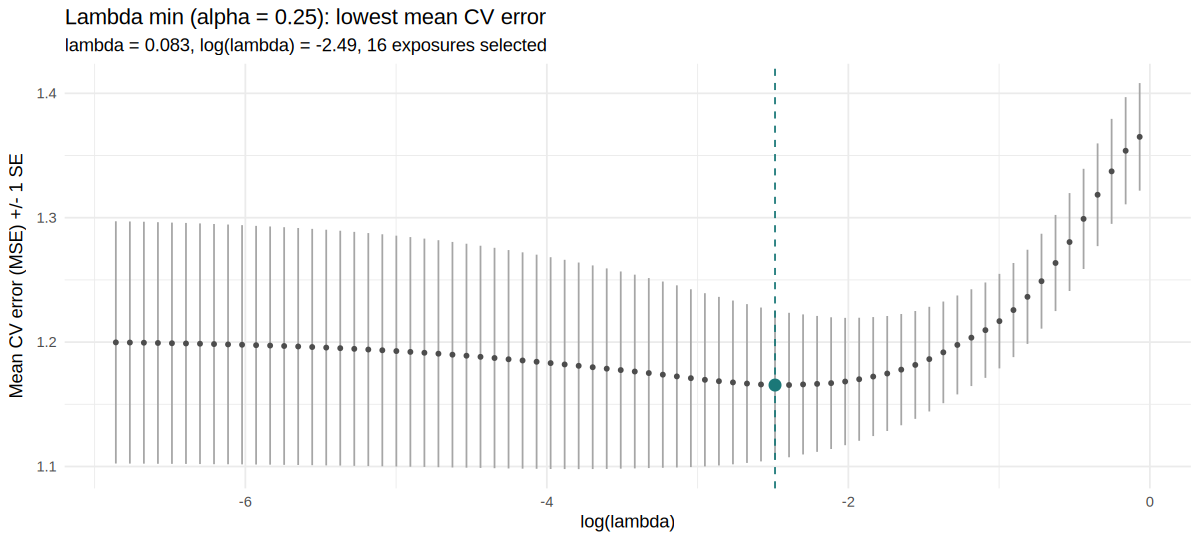

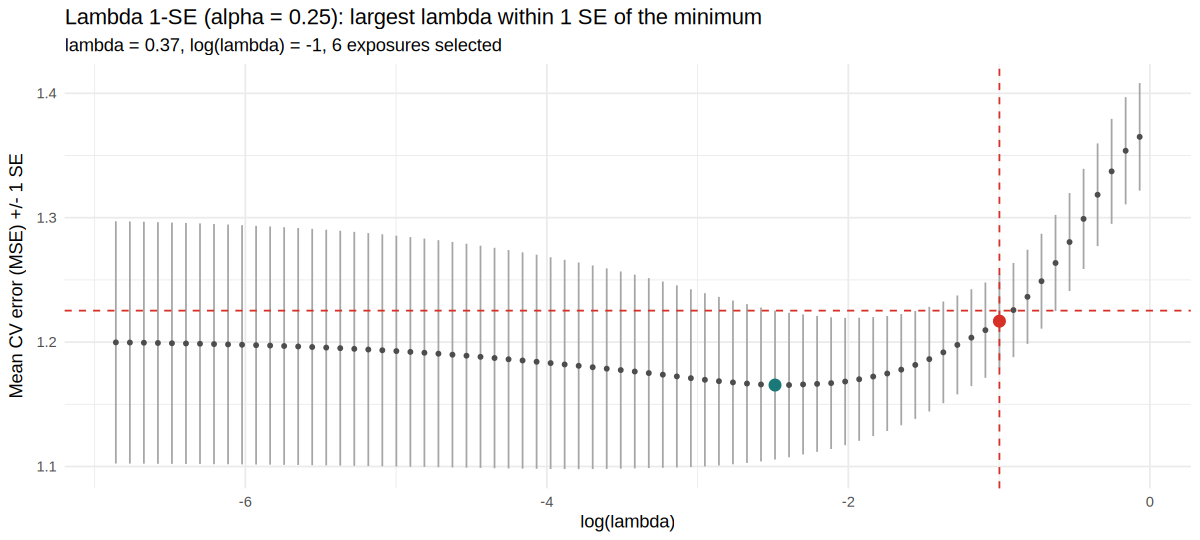

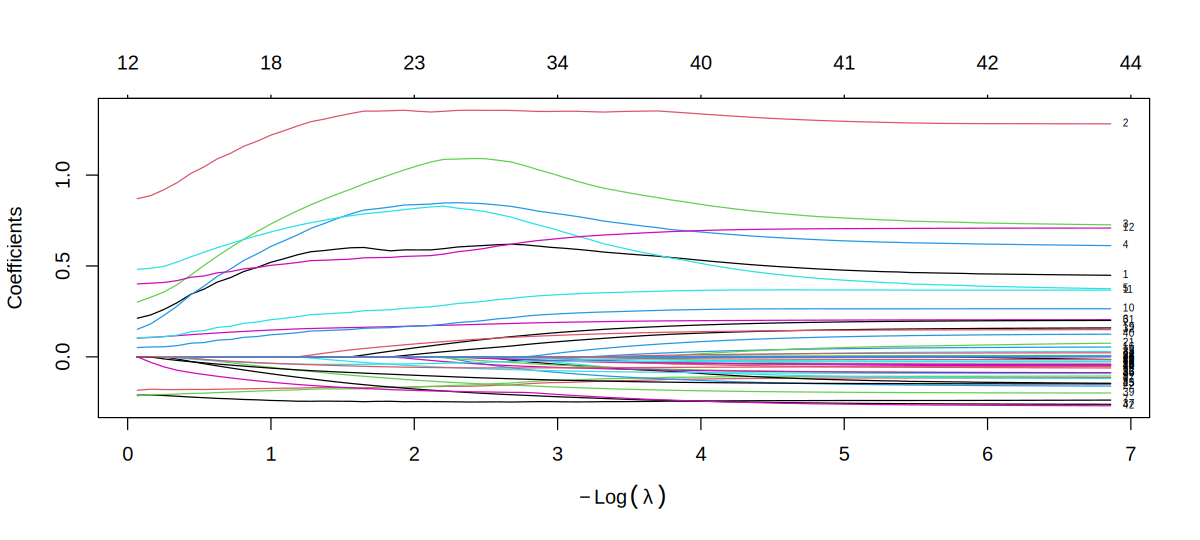

In [ ]:
# 4. Cross-validated error along the lambda sequence for the best alpha, one plot per criterion.
#    Points: mean CV error over the 10 folds. Error bars: +/- 1 standard error (SE).
# - Plot 1, lambda min: log(lambda) ≈ -2.5, i.e. lambda ≈ 0.08 in our data. The lambda with the lowest
#   mean cross-validated error across the 10 folds.
# - Plot 2, lambda 1-SE: log(lambda) ≈ -1, i.e. lambda ≈ 0.37 in our data. The largest lambda (more
#   penalty, fewer exposures) whose mean error does not exceed the minimum by more than one standard
#   error (horizontal line).
# - Lambda min keeps the exact minimum, even if in practice it is tied with more penalised lambdas.
# - The 1-SE rule says: among all the models that cannot be told apart from the best one, choose the
#   simplest. It has fewer exposures, a more stable selection and fewer false positives. In exchange,
#   the error is slightly higher and it may miss exposures with small but real effects.

a_plot <- model_auto$bestTune$alpha   # change to 0.25, 0.5 or 0.75 to see the other alphas
res_plot <- cv_res[cv_res$alpha == a_plot, ]
lines_a <- summary_table[summary_table$alpha == a_plot, ]
pt_min <- res_plot[res_plot$lambda == lines_a$lambda_min, ]   # point with the lowest mean CV error
pt_1se <- res_plot[res_plot$lambda == lines_a$lambda_1se, ]   # point chosen by the 1-SE rule

# Part shared by both plots: mean CV error at each lambda with its +/- 1 SE error bar
p_base <- ggplot(res_plot, aes(x = log(lambda), y = MSE)) +
  geom_errorbar(aes(ymin = MSE - MSE_SE, ymax = MSE + MSE_SE), width = 0, colour = "grey65") +
  geom_point(size = 1, colour = "grey30") +
  labs(x = "log(lambda)", y = "Mean CV error (MSE) +/- 1 SE") +
  theme_minimal()

options(repr.plot.width = 10, repr.plot.height = 4.5)

# Plot 1: lambda min
p_min <- p_base +
  geom_vline(xintercept = log(pt_min$lambda), linetype = "dashed", colour = "#1b7878") +
  geom_point(data = pt_min, colour = "#1b7878", size = 3) +
  labs(title = paste0("Lambda min (alpha = ", a_plot, "): lowest mean CV error"),
       subtitle = paste0("lambda = ", signif(pt_min$lambda, 2),
                         ", log(lambda) = ", round(log(pt_min$lambda), 2),
                         ", ", lines_a$n_exposures_min, " exposures selected"))
print(p_min)

# Plot 2: lambda 1-SE. The horizontal line is the minimum error + 1 SE, i.e. the top of the error bar
# of the lambda min point (teal). Lambda 1-SE (red) is the point furthest to the right whose mean
# error is still below that line.
p_1se <- p_base +
  geom_hline(yintercept = pt_min$MSE + pt_min$MSE_SE, linetype = "dashed", colour = "#d73027") +
  geom_vline(xintercept = log(pt_1se$lambda), linetype = "dashed", colour = "#d73027") +
  geom_point(data = pt_min, colour = "#1b7878", size = 3) +
  geom_point(data = pt_1se, colour = "#d73027", size = 3) +
  labs(title = paste0("Lambda 1-SE (alpha = ", a_plot, "): largest lambda within 1 SE of the minimum"),
       subtitle = paste0("lambda = ", signif(pt_1se$lambda, 2),
                         ", log(lambda) = ", round(log(pt_1se$lambda), 2),
                         ", ", lines_a$n_exposures_1se, " exposures selected"))
print(p_1se)

# Coefficient paths of the final model: how each coefficient shrinks towards zero as lambda grows
# (the lines that never reach zero are the unpenalised covariates).
# Dashed line: lambda min. Dotted line: lambda 1-SE.
plot(model_auto$finalModel, xvar = "lambda", label = TRUE)
abline(v = log(c(lines_a$lambda_min, lines_a$lambda_1se)), lty = c(2, 3))

**How to read these results.** The table shows, for each alpha, how many exposures remain in the model at *lambda min* and at *lambda 1-SE*. *Lambda min* gives the best predictive performance in cross-validation. *Lambda 1-SE* gives a simpler model whose performance cannot be distinguished from the best one, and it is often preferred for variable selection (`caret` uses *lambda min* for the final model). In the plots, compare the error bars with the change in the mean error across lambdas: if the differences between neighbouring lambdas are small compared with the error bars, the choice of lambda (and of the selected exposures) is unstable and could change with another split of the data (another `set.seed()`). Exposures selected consistently across alphas, lambdas and methods (ExWAS, stepwise, DSA) are the most robust candidates.

* **Deletion Substitution Addition (DSA):** It is a technique based on multiple iterations using cross-validation, where a variable is removed, substituted or added to the model. Like the previous technique it is subject to unstable results.

In [ ]:
# install/load DSA package
pacman::p_load(partDSA)

In [ ]:
# vfold = 1: no cross-validation, the model is fitted once on the whole dataset.
# (The default, vfold = 10, uses 10-fold CV to choose the number of partitions, but it is much slower.)
control <- DSA.control(vfold=1)

In [ ]:
# Estimated execution time: approx. 20 seconds.

model_dsa <- partDSA(x, data$hs_zbmi_who, control = control)
# Arguments:
# - x: predictor matrix (the same one used for elastic net: covariates + exposures).
#   Unlike in our elastic net, the covariates are not forced into the model: they compete with the exposures.
# - data$hs_zbmi_who: outcome.
# - control: settings defined above. By default, models with up to 10 partitions are explored
#   (cut.off.growth = 10).
# DSA splits the sample into partitions (groups defined by cut-offs of the predictors) using Deletion,
# Substitution and Addition moves, and predicts the outcome as the mean within each partition.
# Without cross-validation, the "test risk" printed below is computed on the same data used to fit the
# model, which is why it always decreases as the number of partitions grows.

In [ ]:
print(model_dsa)

partDSA object
# partitions   test risk
1              1.414760   
2              1.277574   
3              1.224445   
4              1.190492   
5              1.167892   
6              1.151205   
7              1.134648   
8              1.119117   
9              1.105395   
10             1.092893   

Outcome:
Best of 1 partitions:
   Part.1 
    0.403
Best of 2 partitions:
   Part.1    Part.2 
    1.073    0.198
Best of 3 partitions:
   Part.1    Part.2    Part.3 
    1.073    0.382    -0.179
Best of 4 partitions:
   Part.1    Part.2    Part.3    Part.4 
    1.073    0.158    -0.179    0.677
Best of 5 partitions:
   Part.1    Part.2    Part.3    Part.4    Part.5 
    0.94    0.158    -0.179    0.677    1.8
Best of 6 partitions:
   Part.1    Part.2    Part.3    Part.4    Part.5    Part.6 
    0.94    0.158    -0.179    0.87    1.8    0.288
Best of 7 partitions:
   Part.1    Part.2    Part.3    Part.4    Part.5    Part.6    Part.7 
    0.807    0.158    -0.179    0.87    1.8    

In [ ]:
summary(model_dsa)

                  Length Class  Mode     
cut.off.growth        1  -none- numeric  
minsplit              1  -none- numeric  
minbuck               1  -none- numeric  
MPD                   1  -none- numeric  
IkPn                 10  -none- list     
coefficients         10  -none- list     
IkPn.risks           10  -none- list     
var.levels           44  -none- list     
var.names            44  -none- character
var.importance      440  -none- numeric  
options               2  -none- list     
y.levels              0  -none- NULL     
tablist              10  -none- list     
datalist             10  -none- list     
x                     0  -none- NULL     
y                     0  -none- NULL     
mean.cv.risk.DSA      0  -none- NULL     
sd.cv.risk            0  -none- NULL     
pred.test.set.DSA 13010  -none- numeric  
test.set.risk.DSA    10  -none- numeric  

In [ ]:
model_dsa$var.importance

,COG=1,COG=2,COG=3,COG=4,COG=5,COG=6,COG=7,COG=8,COG=9,COG=10
h_cohort2,0,0,0,0,0,0,0,0,0,0
h_cohort3,0,0,0,0,0,0,0,0,0,0
h_cohort4,0,0,0,0,0,0,0,0,0,0
h_cohort5,0,0,0,0,0,0,0,0,0,0
h_cohort6,0,0,0,0,2,2,3,3,4,5
e3_sex_Nonemale,0,0,0,0,0,0,0,0,0,0
e3_yearbir_None2004,0,0,0,0,0,0,0,0,0,0
e3_yearbir_None2005,0,0,0,0,0,0,0,0,0,0
e3_yearbir_None2006,0,0,0,0,0,0,0,0,0,0
e3_yearbir_None2007,0,0,0,0,0,0,0,0,0,0


**Variables selected by the algorithm:**

hs_popdens_h_Sqrt  
hs_builtdens300_s_Sqrt  
hs_landuseshan300_s_None    
hs_dde_cadj_Log2    
hs_hcb_cadj_Log2    
hs_pcb170_cadj_Log2   

*   **Question 3:** <font color='red'> **Which of the following methods give more conservative results?** </font>

1. ExWas
2. Stepwise
<font color='green'> 3. Elastic net </font>

<font color='green'> 4. DSA </font>

*   **Question 4:** <font color='red'> **Were some of the variables selected by various selection methods, would you select these six variables for your regression model?** </font>  <font color='green'> Yes, if the variables have been selected by different methods, which have different goodness of fit and particularities, they are likely to be exposures of interest.</font>

### **4.3.- Clustering** ###

The identification of exposure patterns is of particular interest in exposome studies. Using clustering techniques in exposome studies we try to identify groups or clusters of subjects that share similar exposure profiles and check whether these exposures are associated with a health outcome.


In [ ]:
# Estimated execution time: 48 seconds approx.

pacman::p_load(cluster, factoextra)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘viridis’, ‘ggsci’, ‘ggsignif’, ‘polynom’, ‘rstatix’, ‘dendextend’, ‘ggpubr’



factoextra installed



In [ ]:
# We center the exposures by cohort.
expo3 <- expo2
for (i in 2:length(expo2)) {
  mean_y <- with(expo3, {mean_y = ave(expo2[,i],data$h_cohort,FUN=mean)} )
  expo3[,i] <- expo3[,i] - mean_y
}

In clustering techniques such as K-means, cluster centres are calculated as the average of the points belonging to each cluster. If the data are not centered, differences in means between cohorts can bias these centres and thus the assignment of points to clusters. Centering the data helps to avoid this bias.

In [ ]:
fviz_nbclust(expo3[,-1], kmeans, method = "gap_stat", iter.max = 50)
# Arguments:
# - expo3[,-1]: exposures centred by cohort (without the ID column).
# - kmeans: clustering algorithm applied for each number of clusters k.
# - method = "gap_stat": gap statistic. For each k, it compares the within-cluster dispersion of our data
#   with the one expected in reference data without any cluster structure (nboot = 100 simulated
#   datasets by default).
# - k.max = 10 (default): numbers of clusters evaluated, from 1 to 10.
# - iter.max = 50: passed on to kmeans(). It raises the maximum number of iterations (default 10) to avoid
#   the "did not converge in 10 iterations" warnings.

The optimal number of clusters is at the point where the Gap statistic reaches its maximum value before it starts to decrease.

*   **Question 5:** <font color='red'> **What number of clusters would you select based on the Gap statistic?** </font> <font color='green'> The optimal number of clusters in this dataset is **one**, according to the Gap statistic criterion, because the gap value does not increase significantly beyond k = 1 and all subsequent values fall within the range of their standard errors—indicating no clear evidence of distinct subgroups or discrete clustering structure in the data.

However, we also explored a five-cluster solution for descriptive purposes, since **k = 5** showed a mild local maximum in the gap curve that might reflect subtle gradients or patterns of co-exposure, even if not statistically robust according to the formal criterion.  </font>


In [ ]:
set.seed(111)
km.res <- kmeans(expo3[,-1], centers = 5, nstart = 25)
# Arguments:
# - centers = 5: number of clusters (chosen for descriptive purposes, see Question 5).
# - nstart = 25: k-means is run from 25 random starting points and the best solution (lowest
#   within-cluster sum of squares) is kept, which makes the result more stable.
#   set.seed() makes the random starts reproducible.
clus.means <- aggregate(expo3[,-1], by=list(cluster=km.res$cluster), mean)  # mean exposure profile of each cluster

In [ ]:
clus.means

cluster,hs_accesslines300_h_dic0,hs_accesspoints300_h_Log,hs_builtdens300_h_Sqrt,hs_connind300_h_Log,hs_fdensity300_h_Log,hs_landuseshan300_h_None,hs_popdens_h_Sqrt,hs_walkability_mean_h_None,hs_accesslines300_s_dic0,⋯,hs_mo_c_Log2,hs_pb_c_Log2,hs_dde_cadj_Log2,hs_ddt_cadj_Log2,hs_hcb_cadj_Log2,hs_pcb118_cadj_Log2,hs_pcb138_cadj_Log2,hs_pcb153_cadj_Log2,hs_pcb170_cadj_Log2,hs_pcb180_cadj_Log2
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0.068027858,0.06802020,0.69053652,0.4911977705,0.27533155,-0.0183001617,0.52348608,0.50550886,0.051551076,⋯,0.422542712,0.09456716,0.07767365,0.5742655,0.06264613,0.06836281,0.11238437,0.07342858,0.37420082,0.14324516
2,-0.020889568,-0.02595335,-0.25926275,-0.2014307698,-0.12698967,-0.0005243344,-0.19518171,-0.21444220,-0.017076649,⋯,0.003746554,-0.03475683,-0.25616668,0.4275617,-0.28609620,-0.31110064,-0.31337829,-0.32139918,0.01065758,-0.30305792
3,-0.024699837,0.00849659,-0.16511225,-0.1126206812,-0.03953440,-0.0293309397,-0.17357374,-0.12045291,-0.024200337,⋯,-0.288081899,0.00881397,0.46828682,0.6667916,0.55480700,0.55617521,0.61278847,0.57537721,0.82875684,0.57684104
4,-0.005119143,-0.01651478,0.02372510,0.0305189412,0.04071501,0.0127606602,-0.02897997,0.14986281,0.004525342,⋯,-0.150498147,0.16155591,-0.29401009,-0.2458563,-0.35779723,-0.42873273,-0.64319126,-0.35985907,-3.28181948,-0.63367765
5,0.004265192,-0.02835575,-0.02838431,-0.0004678197,-0.01933819,0.0580466007,0.07202262,-0.04260316,0.009320802,⋯,0.020320044,-0.13601733,-0.10648825,-2.3548131,-0.12287846,-0.04340003,-0.05746925,-0.09343581,0.08636792,-0.06511702


Additionally, we can see how many subjects each cluster is composed of or by some other variable.

In [ ]:
table(km.res$cluster)


  1   2   3   4   5 
239 425 312 113 212 

In [ ]:
table(km.res$cluster, data$h_cohort) # number of subjects by cluster and cohort

   
     1  2  3  4  5  6
  1 31 42 46 25 46 49
  2 41 80 68 76 88 72
  3 47 55 40 73 54 43
  4 39  3 11 28  5 27
  5 44 18 59  5 79  7

We can visualise the exposome patterns in the different clusters previously identified.


* **Cluster 1 (N = 239):** They live in populated, dense, trafficable areas; exposed to Mo and DDT.

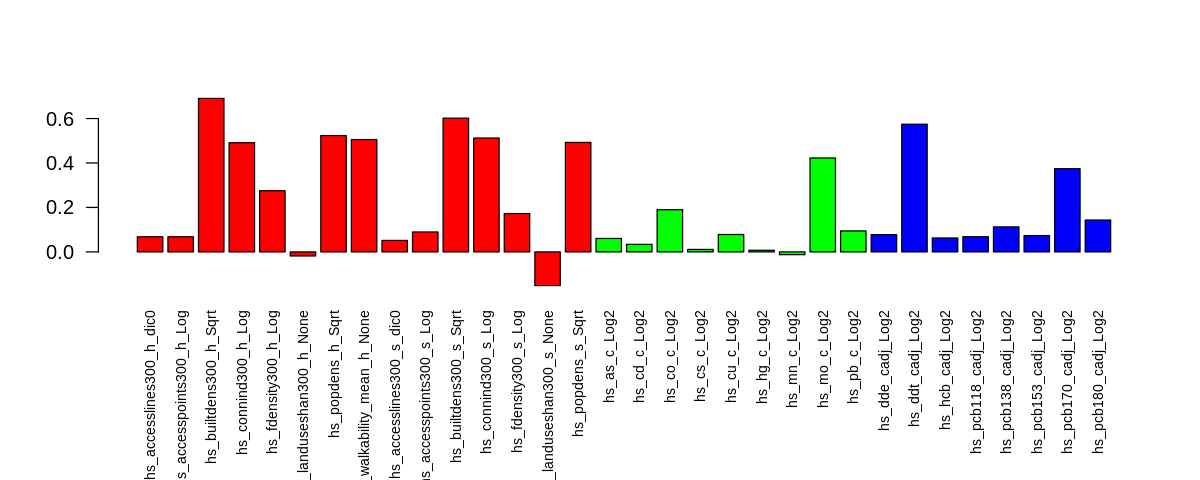

In [ ]:
options(repr.plot.width=10, repr.plot.height=4) # we define the size of the graph for colab
par(mar = c(8, 4, 4, 2) + 0.1)  # c(bottom, left, top, right) we adjust the margins
barplot(as.numeric(clus.means[1,2:ncol(clus.means)]),
        col=c(rep("red",15),rep("green",9),rep("blue",8)),
        names.arg=names(clus.means)[-1],
        cex.names=.7,
        las=2,
        srt=90)

* **Cluster 2 (N = 425):** High exposure to DDT and mn but low exposure to other organochlorines; Low population density (possibly rural).

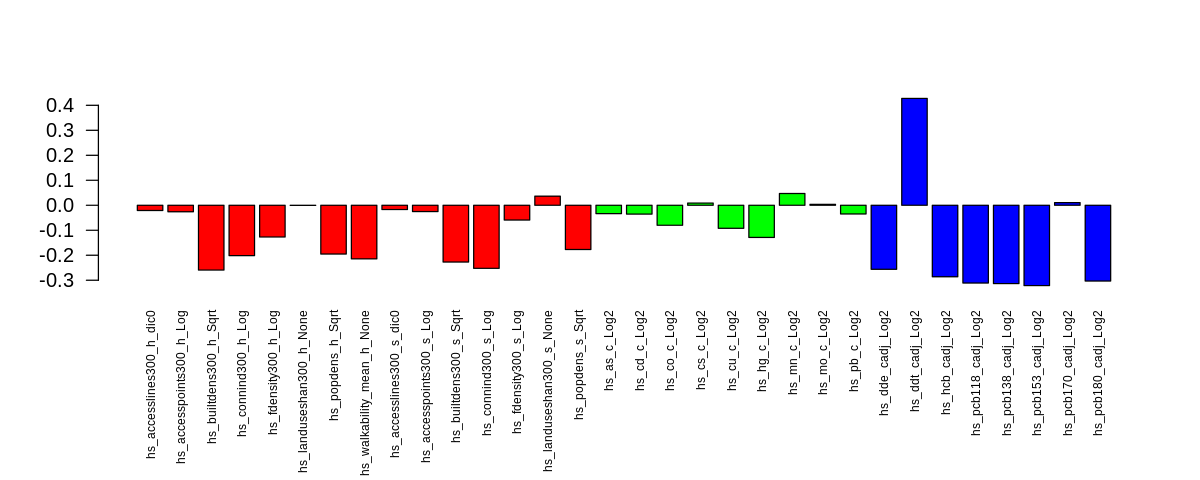

In [ ]:
options(repr.plot.width=10, repr.plot.height=4) # we define the size of the graph for colab
par(mar = c(8, 4, 4, 2) + 0.1)  # c(bottom, left, top, right) we adjust the margings
barplot(as.numeric(clus.means[2,2:ncol(clus.means)]), col=c(rep("red",15),rep("green",9),rep("blue",8)),
        names.arg=names(clus.means)[-1],
        cex.names=.6,
        las=2,
        srt=90)

* **Cluster 3 (N = 312):** Less dense residential area, exposure to mercury and all organochlorines

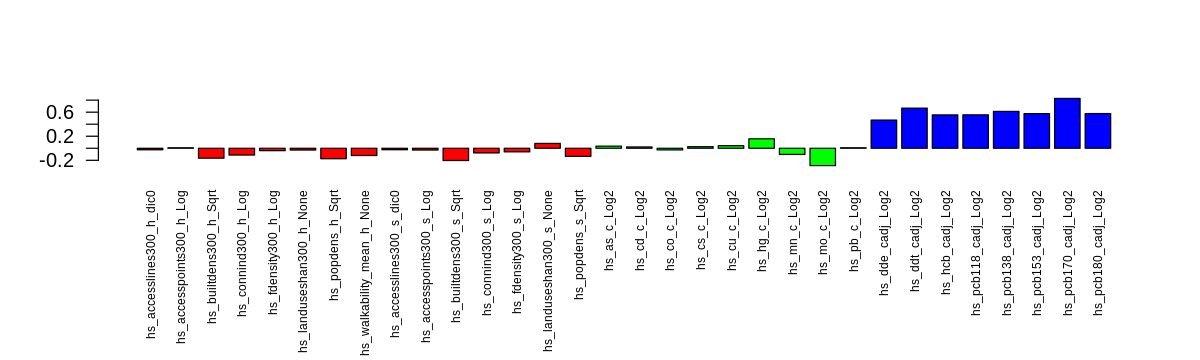

In [ ]:
options(repr.plot.width=10, repr.plot.height=3) # we define the size of the graph for colab
par(mar = c(8, 4, 4, 2) + 0.1)  # c(bottom, left, top, right) adjust the margings
barplot(as.numeric(clus.means[3,2:ncol(clus.means)]), col=c(rep("red",15),rep("green",9),rep("blue",8)),
        names.arg=names(clus.means)[-1],
        cex.names=.6, las=2, srt=90)

* **Cluster 4 (N = 113):** Less dense residential area, low exposure to all metals and all organochlorines

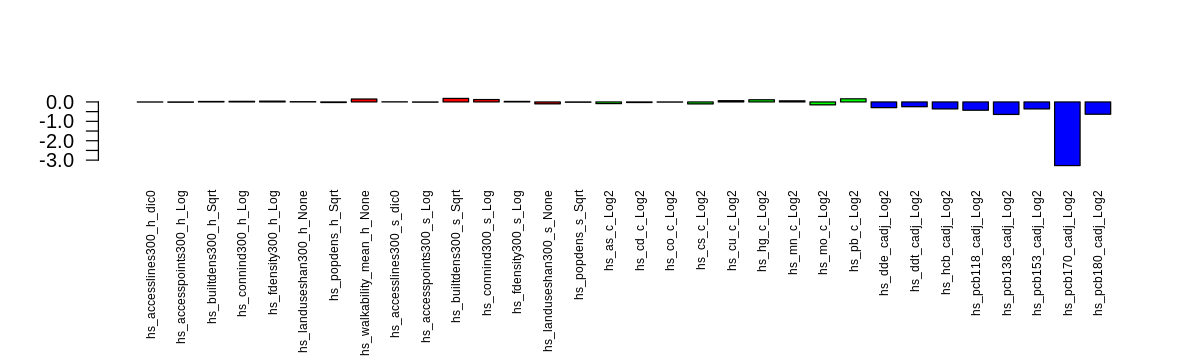

In [ ]:
options(repr.plot.width=10, repr.plot.height=3) #  we define the size of the graph for colab
par(mar = c(8, 4, 4, 2) + 0.1)  # c(bottom, left, top, right) adjust the margins
barplot(as.numeric(clus.means[4,2:ncol(clus.means)]), col=c(rep("red",15),rep("green",9),rep("blue",8)),
names.arg=names(clus.means)[-1],
        cex.names=.6, las=2, srt=90)

* **Cluster 5 (N = 212):** Similar to cluster 4 with even lower exposure to DDT

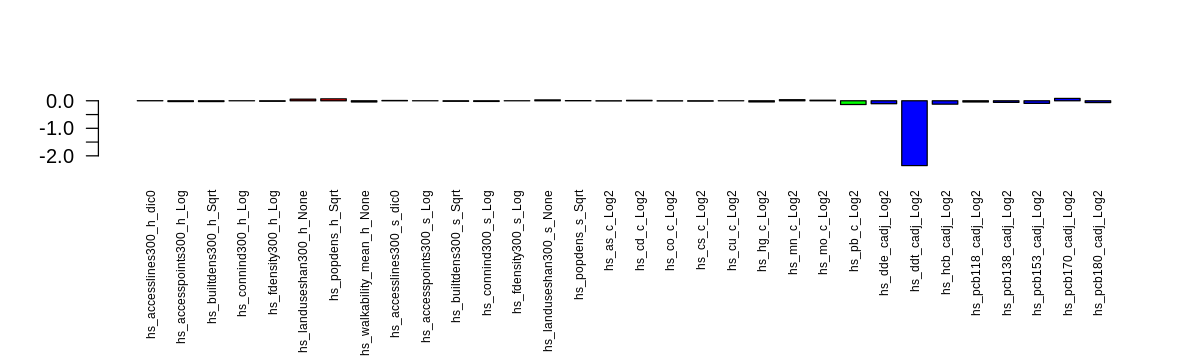

In [ ]:
options(repr.plot.width=10, repr.plot.height=3) # we set the graph size
par(mar = c(8, 4, 4, 2) + 0.1)  # c(bottom, left, top, right) we adjust the margings
barplot(as.numeric(clus.means[5,2:ncol(clus.means)]), col=c(rep("red",15),rep("green",9),rep("blue",8)),
names.arg=names(clus.means)[-1],
        cex.names=.6, las=2, srt=90)

Finally, we can explore the association of each of the clusters with the health outcome of interest by adjusting for some covariates of interest.

In [ ]:
mod_cluster <- lm(hs_zbmi_who ~ as.factor(km.res$cluster) + h_cohort + e3_sex_None + e3_yearbir_None, data = data) # we adjust the analysis by cohort, sex and year of birth
summary(mod_cluster)


Call:
lm(formula = hs_zbmi_who ~ as.factor(km.res$cluster) + h_cohort + 
    e3_sex_None + e3_yearbir_None, data = data)

Residuals:
    Min      1Q  Median      3Q     Max 
-3.7247 -0.7393 -0.0751  0.7175  3.8131 

Coefficients:
                           Estimate Std. Error t value Pr(>|t|)    
(Intercept)                -0.31055    0.34124  -0.910  0.36296    
as.factor(km.res$cluster)2  0.44636    0.09062   4.926 9.51e-07 ***
as.factor(km.res$cluster)3 -0.19275    0.09686  -1.990  0.04681 *  
as.factor(km.res$cluster)4  0.90059    0.13091   6.879 9.37e-12 ***
as.factor(km.res$cluster)5  0.26706    0.10806   2.471  0.01359 *  
h_cohort2                   0.38921    0.29804   1.306  0.19182    
h_cohort3                   0.95897    0.23162   4.140 3.69e-05 ***
h_cohort4                   0.35031    0.11296   3.101  0.00197 ** 
h_cohort5                   0.24656    0.21464   1.149  0.25090    
h_cohort6                   0.50678    0.11340   4.469 8.56e-06 ***
e3_sex_Nonemale      

In [ ]:
# Estimated execution time: 60 secs approx.
pacman::p_load(dotwhisker)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘bayestestR’, ‘datawizard’, ‘insight’, ‘parameters’, ‘performance’, ‘patchwork’, ‘ggstance’, ‘marginaleffects’



dotwhisker installed



Warning message:
“Using the `size` aesthetic with geom_segment was deprecated in ggplot2 3.4.0.
ℹ Please use the `linewidth` aesthetic instead.
ℹ The deprecated feature was likely used in the dotwhisker package.
  Please report the issue at <https://github.com/fsolt/dotwhisker/issues>.”


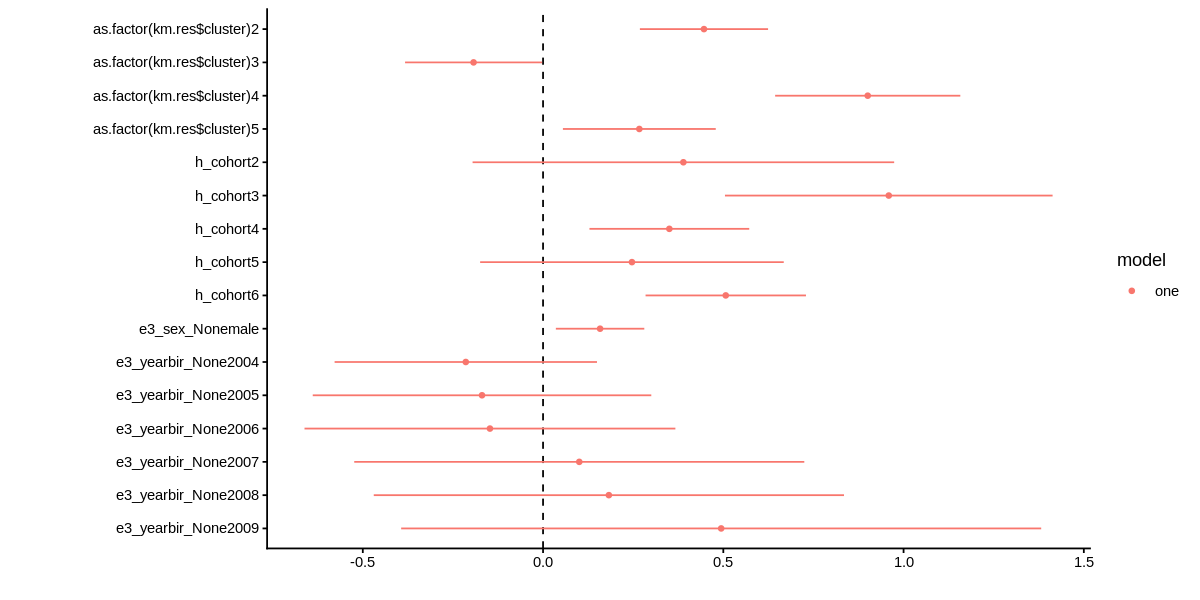

In [ ]:
options(repr.plot.width=10, repr.plot.height=5) # define the size of the graph in colab
# we wrap our function to remove warnings in colab
suppressWarnings(dotwhisker::dwplot(mod_cluster, vline = geom_vline(
           xintercept = 0,
           colour = "black",
           linetype = 2)) + theme_classic())

In the regression results we can see that belonging to **cluster 2**, **cluster 3** and **cluster 4** is associated with an increase in BMI, depending on the cluster we select as reference.   


### **4.4.- Mixture Analysis**

The main idea in mixtures analysis is that low levels of exposure to a given pollutant may produce no health effects (or effects too small to be detected), but combined exposure to multiple pollutants may generate an effect.

Commonly used approaches in environmental epidemiology fail to capture the complexity of assessing the combined effect of multiple exposures due to some limitations:

* They do not assess the joint effect of multiple exposures.
* They do not consider the interaction between different exposures.
* They face a high correlation between exposures.

Therefore more sophisticated methods are needed to investigate the health effects of mixtures or multiple exposures. In recent years several methods have been proposed to estimate the independent and joint effects of multiple exposures.

The **selection** of the right **method** in **mixture analysis** should be guided by the **research question** we want to answer (please, take a look on the figure below from Joubert et al. (2022) DOI: 10.3390/ijerph19031378).

<img src="https://github.com/alldominguez/ISGlobal.sesion4.Exposoma/blob/main/figures/PRIME.png?raw=1" alt="ISGlobal logo" width="500"/>  

In this section we will review three methods for mixture analysis.

**1. Weighted Quantile Sum Regression (WQS)**  
**2. Bayesian Kernel Machine Regression (BKMR)**  
**3. Quantile g-computation (qgcomp)**   

**Note:** Mixture analysis is very time consuming. Therefore, this section will show the code necessary to perform the analysis and the interpretation of the results, without running the cells.  



With the following line we install the necessary packages to perform the mix analysis.

In [ ]:
# We install/load the necessary packages to perform the analysis.
pacman::p_load(gWQS, bkmr, MASS)

To **facilitate the interpretation** of the results we will use only the organochlorine family for the mixture analysis.

In [ ]:
codebook$family

[1] Air Pollution                             
  [2] Air Pollution                             
  [3] Air Pollution                             
  [4] Air Pollution                             
  [5] Air Pollution                             
  [6] Air Pollution                             
  [7] Air Pollution                             
  [8] Air Pollution                             
  [9] Air Pollution                             
 [10] Air Pollution                             
 [11] Air Pollution                             
 [12] Air Pollution                             
 [13] Air Pollution                             
 [14] Air Pollution                             
 [15] Air Pollution                             
 [16] Air Pollution                             
 [17] Built environment                         
 [18] Built environment                         
 [19] Built environment                         
 [20] Built environment                         
 [21] Built environment                         
 [22] Built environment                         
 [23] Built environment                         
 [24] Built environment                         
 [25] Built environment                         
 [26] Built environment                         
 [27] Built environment                         
 [28] Built environment                         
 [29] Built environment                         
 [30] Built environment                         
 [31] Built environment                         
 [32] Built environment                         
 [33] Built environment                         
 [34] Built environment                         
 [35] Built environment                         
 [36] Built environment                         
 [37] Built environment                         
 [38] Built environment                         
 [39] Built environment                         
 [40] Built environment                         
 [41] Indoor air                                
 [42] Indoor air                                
 [43] Indoor air                                
 [44] Indoor air                                
 [45] Indoor air                                
 [46] Lifestyle                                 
 [47] Lifestyle                                 
 [48] Lifestyle                                 
 [49] Lifestyle                                 
 [50] Lifestyle                                 
 [51] Lifestyle                                 
 [52] Lifestyle                                 
 [53] Lifestyle                                 
 [54] Lifestyle                                 
 [55] Lifestyle                                 
 [56] Lifestyle                                 
 [57] Lifestyle                                 
 [58] Lifestyle                                 
 [59] Lifestyle                                 
 [60] Lifestyle                                 
 [61] Lifestyle                                 
 [62] Lifestyle                                 
 [63] Lifestyle                                 
 [64] Lifestyle                                 
 [65] Lifestyle                                 
 [66] Lifestyle                                 
 [67] Lifestyle                                 
 [68] Lifestyle                                 
 [69] Lifestyle                                 
 [70] Lifestyle                                 
 [71] Lifestyle                                 
 [72] Lifestyle                                 
 [73] Lifestyle                                 
 [74] Lifestyle                                 
 [75] Lifestyle                                 
 [76] Lifestyle                                 
 [77] Lifestyle                                 
 [78] Lifestyle                                 
 [79] Lifestyle                                 
 [80] Lifestyle                                 
 [81] Lifestyle                                 
 [82] Lifestyle                  

In [ ]:
# We make a subset of the expo.list using only organochlorine compounds (postnatal period).
expo.list <- as.character(codebook$variable_name[(codebook$family == "Organochlorines") &
                                                  codebook$period == "Postnatal"])
# hs_sumPCBs5_cadj_Log2 is the sum of PCBs that are already in the list individually: including it would
# count the same compounds twice in the mixture (we also excluded it in Section 2)
expo.list <- expo.list[expo.list != "hs_sumPCBs5_cadj_Log2"]
expo.list

In [ ]:
expo2 <- exposome[ ,c("ID", expo.list)]

In [ ]:
dat <- cbind(hs_zbmi_who = phenotype[ ,4],  # select the 4th column of the phenotype dataframe and name it hs_zbmi_who
             covariates[ ,2:13])  # we select from columns 2 to 13 of the dataframe covariates

# Then, combine both into one data frame
combined_data <- data.frame(expo2, dat)

* **Weighted Quantile Sum Regression (WQS)**.

It is a method that operates in a supervised learning framework, creating a single score (the weighted quantile sum) that summarises the overall exposure to the mixture and includes this score in a regression model. It aims to assess the overall effect of the mixture on the health outcome of interest. The score is calculated as a weighted sum (so that exposures with weaker effects on the outcome have less weight in the index) of all exposures categorised into quartiles, or more groups, so that outliers have less impact on the weight estimate.

In [ ]:
mod_wqs <- gwqs(hs_zbmi_who ~ wqs + h_cohort + e3_sex_None + e3_yearbir_None, mix_name = expo.list, data = combined_data,
                q = 10, validation = 0.6, b = 100, b1_pos = FALSE,
                b_constr = FALSE, family = "gaussian", seed = 2016)
# Arguments:
# - formula: outcome ~ wqs + covariates. "wqs" stands for the weighted index built from the mixture.
# - mix_name: exposures that form the mixture (here, the organochlorines).
# - data: data frame with the outcome, the covariates and the exposures.
# - q = 10: each exposure is categorised into deciles (0-9) before building the index. This puts all the
#   exposures on the same scale and reduces the influence of outliers.
# - validation = 0.6: 60% of the sample is used to test the index and 40% to estimate the weights
#   (training). Estimating and testing on different data avoids overfitting.
# - b = 100: number of bootstrap samples of the training set; the weights are averaged across them.
# - b1_pos = FALSE: the weights are estimated for a negative mixture effect (in ExWAS, the organochlorines
#   were inversely associated with BMI). WQS estimates the effect in one direction only, fixed a priori.
# - b_constr = FALSE: the sign of the index coefficient is not constrained during the estimation of the
#   weights. (Older versions of gWQS called it b1_constr, which now gives a deprecation warning.)
# - family = "gaussian": linear regression for a continuous outcome.
# - seed = 2016: reproducible training/validation split and bootstrap samples.

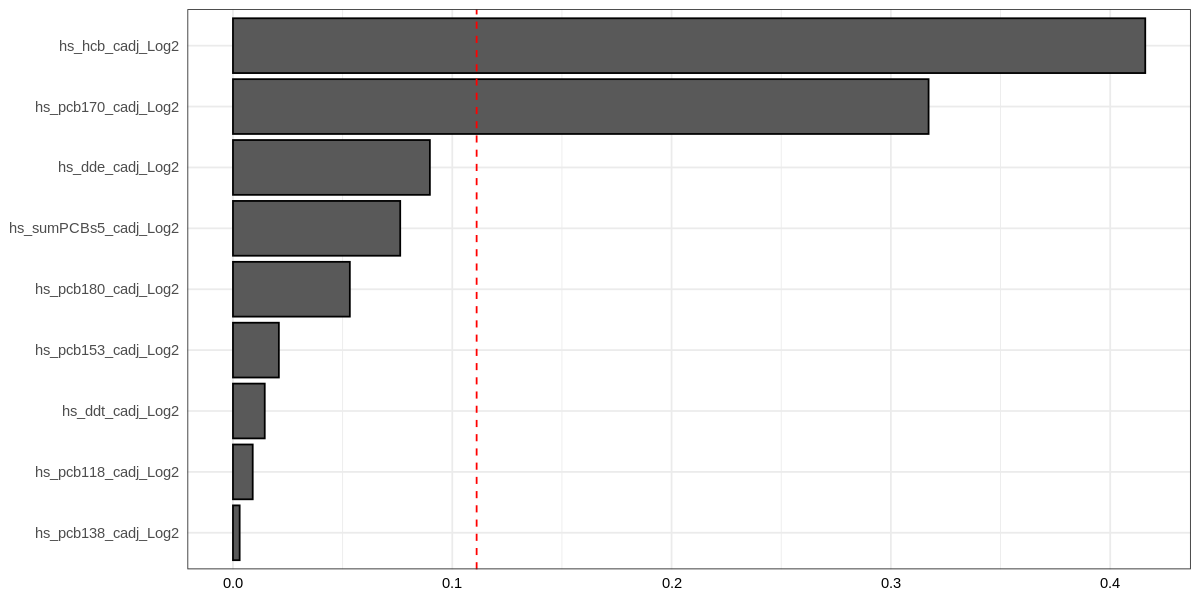

In [ ]:
options(repr.plot.width=10, repr.plot.height=5) # set graph dimensions
gwqs_barplot(mod_wqs)
# Red dashed line: 1/c (c = number of exposures in the mixture), the weight each exposure would have
# if all contributed equally. Exposures above it are the main contributors to the WQS index.

In [ ]:
summary(mod_wqs)


Call:
gwqs(formula = hs_zbmi_who ~ wqs + h_cohort + e3_sex_None + e3_yearbir_None, 
    data = data, mix_name = expo.list, b = 100, b1_pos = FALSE, 
    b1_constr = FALSE, q = 10, validation = 0.6, family = "gaussian", 
    seed = 2016)

Deviance Residuals: 
    Min       1Q   Median       3Q      Max  
-3.6321  -0.7213  -0.0245   0.6600   3.4428  

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)    
(Intercept)          0.35323    0.41557   0.850  0.39560    
wqs                 -0.25831    0.02053 -12.581  < 2e-16 ***
h_cohort2            0.86323    0.37104   2.327  0.02025 *  
h_cohort3            1.68176    0.29439   5.713 1.59e-08 ***
h_cohort4            1.26101    0.16560   7.615 7.76e-14 ***
h_cohort5            1.24147    0.27997   4.434 1.06e-05 ***
h_cohort6            0.74550    0.14034   5.312 1.42e-07 ***
e3_sex_Nonemale      0.21955    0.07739   2.837  0.00468 ** 
e3_yearbir_None2004 -0.46223    0.22398  -2.064  0.03938 *  
e3_yearbir_None2005 -0.

`geom_smooth()` using formula = 'y ~ x'


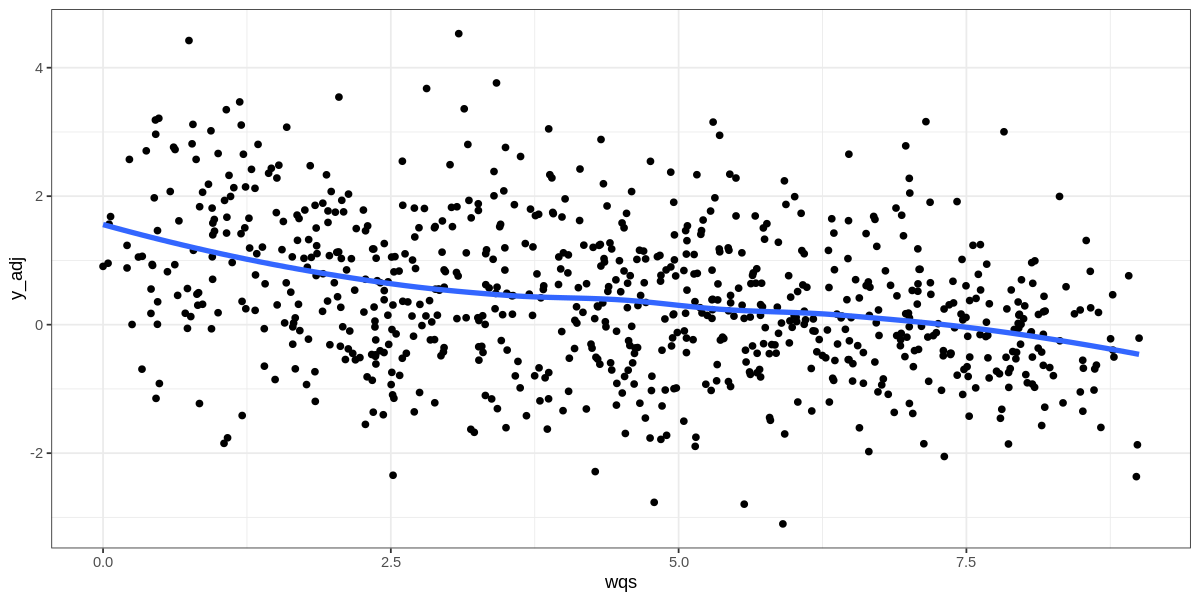

In [ ]:
options(repr.plot.width=10, repr.plot.height=5) # set graph dimensions
gwqs_scatterplot(mod_wqs)

Participants in the top deciles of the selected exposures are those associated with lower BMI.

*   **Question 6:** <font color='red'> **Does this model take into consideration possible interactions?** </font> <font color='green'> No, this model does not account for interactions since it consider an additive model when computing the index </font>

* **Bayesian Kernel Machine Regression (BKMR)**  

It is a method designed to address in a flexible and non-parametric way, several objectives such as;

**1. Detection and estimation of the overall effect of the mixture** ;

**2. Identification of the pollutant or group of pollutants responsible for the observed mixture effects** ;

**3. Visualisation of the exposure-response function** ;

**4. Detection of interactions between individual pollutants**.







In [ ]:
expo.list

In [ ]:
# We define a new dataframe using the data from the data object, previously used in the analysis.
# kmbayes() needs the covariates as numeric columns without intercept, so we create the dummy variables
# by hand (reference categories: cohort 1, male, born in 2003).
X = data.frame(cohort2=as.numeric(data$h_cohort==2), cohort3=as.numeric(data$h_cohort==3),cohort4=as.numeric(data$h_cohort==4),
               cohort5=as.numeric(data$h_cohort==5), cohort6=as.numeric(data$h_cohort==6), female=as.numeric(data$e3_sex_None=="female"),
               year2004=as.numeric(data$e3_yearbir_None==2004), year2005=as.numeric(data$e3_yearbir_None==2005),
               year2006=as.numeric(data$e3_yearbir_None==2006), year2007=as.numeric(data$e3_yearbir_None==2007),
               year2008=as.numeric(data$e3_yearbir_None==2008), year2009=as.numeric(data$e3_yearbir_None==2009))

 <font color='red'> **ALERT!!!! This process takes approximately 50 minutes**. </font> ❗❗❗❗❗❗







In [ ]:
# Estimated execution time: 50 minutes
set.seed(111)
fitkm <- kmbayes(y = combined_data$hs_zbmi_who, Z = combined_data[,expo.list], X = X,
                 iter = 10000, verbose = FALSE, varsel = TRUE)
# Arguments:
# - y: outcome (z-BMI).
# - Z: exposures of the mixture. They enter a flexible function h() through a Gaussian kernel, which
#   allows non-linear effects and interactions between exposures. kmbayes() uses Z as given (it does not
#   standardise it); as the kernel depends on the scale of the exposures, standardising them first
#   (e.g. with scale()) is common practice. Here they are on the log2 scale.
# - X: covariates (cohort, sex, year of birth), modelled linearly, without intercept.
# - iter = 10000: number of MCMC iterations. The summary functions discard the first half as burn-in.
# - verbose = FALSE: do not print the progress of the sampler.
# - varsel = TRUE: variable selection; estimates the posterior inclusion probability (PIP) of each exposure.

Iteration: 1000 (10% completed; 5.88109 mins elapsed)

Iteration: 2000 (20% completed; 11.68314 mins elapsed)

Iteration: 3000 (30% completed; 18.08196 mins elapsed)

Iteration: 4000 (40% completed; 25.01526 mins elapsed)

Iteration: 5000 (50% completed; 31.99395 mins elapsed)

Iteration: 6000 (60% completed; 38.36822 mins elapsed)

Iteration: 7000 (70% completed; 44.40513 mins elapsed)

Iteration: 8000 (80% completed; 50.71053 mins elapsed)

Iteration: 9000 (90% completed; 56.35971 mins elapsed)

Iteration: 10000 (100% completed; 1.06306 hours elapsed)



In [ ]:
# Fitted BKMR object
fitkm

Fitted object of class 'bkmrfit'
Iterations: 10000 
Outcome family: gaussian  
Model fit on: 2023-11-08 21:13:52.415214 

When using several iterations, it is important to assess the convergence of the parameters. By looking at the convergence plots we can verify this (we expect random behaviour around the straight line). What we usually observe is an initial 'burn-in' phase, which we should eliminate from the analysis. The `bkmr` summary functions do it by default: they discard the first half of the iterations (argument `sel`), so the trace plot below shows iterations 5,001 to 10,000.

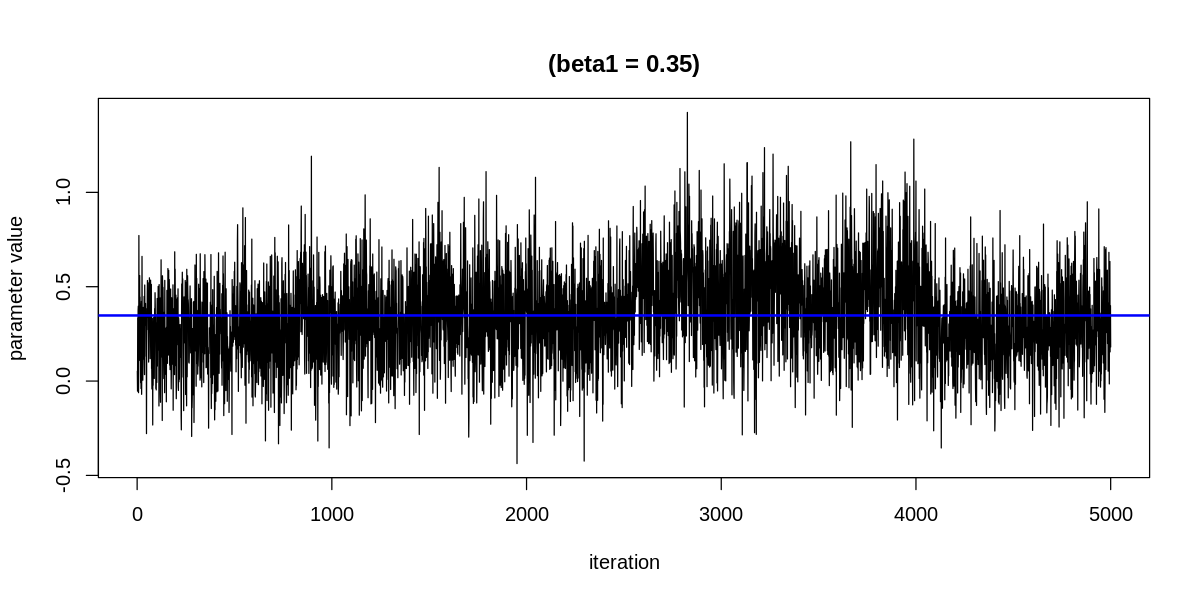

In [ ]:
bkmr::TracePlot(fit = fitkm, par = "beta")
# Trace of the MCMC samples of the first covariate coefficient (beta 1 = cohort2), after discarding the
# first half of the iterations (burn-in). We expect random fluctuation around a stable mean (blue line),
# without trends. Use sel = 1:fitkm$iter to see the whole chain, including the burn-in.

Additionally we can inspect the posterior inclusion probability (PIP) using `bkmr::ExtractPIPs`.

In [ ]:
bkmr::ExtractPIPs(fitkm)
# PIP: proportion of the MCMC iterations (after burn-in) in which each exposure is included in the model.
# Values close to 1 indicate strong evidence that the exposure contributes to the mixture effect;
# 0.5 is a commonly used threshold.

variable,PIP
<chr>,<dbl>
hs_dde_cadj_Log2,0.7776
hs_ddt_cadj_Log2,0.6440
hs_hcb_cadj_Log2,1.0000
hs_pcb118_cadj_Log2,0.4892
hs_pcb138_cadj_Log2,0.3814
hs_pcb153_cadj_Log2,0.3560
hs_pcb170_cadj_Log2,1.0000
hs_pcb180_cadj_Log2,0.2106
hs_sumPCBs5_cadj_Log2,0.2820


To obtain the exposure-response function for each predictor/exposure we use `bkmr::PredictorResponseUnivar`.

In [ ]:
pred.resp.univar <- bkmr::PredictorResponseUnivar(fit = fitkm)
# Exposure-response function h(z) of each exposure, with all the other exposures fixed at their median
# (q.fixed = 0.5, default). Other defaults: ngrid = 50 points over the observed range of each exposure;
# method = "approx" (fast approximation based on posterior means); center = TRUE (the curve is centred
# to mean zero, so the y-axis shows changes relative to the average).

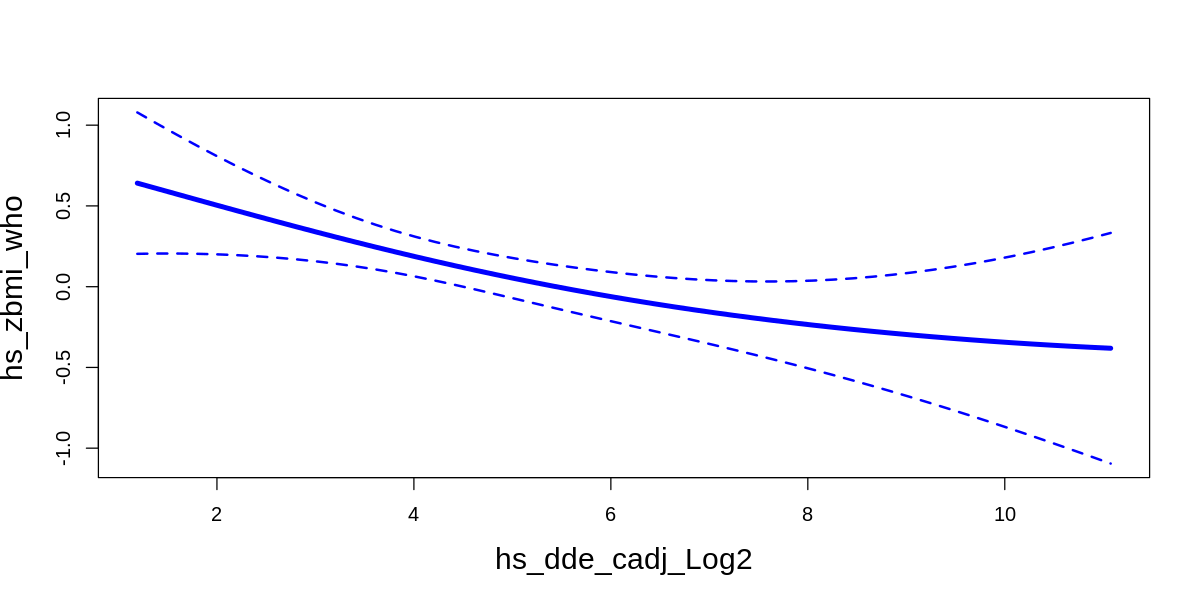

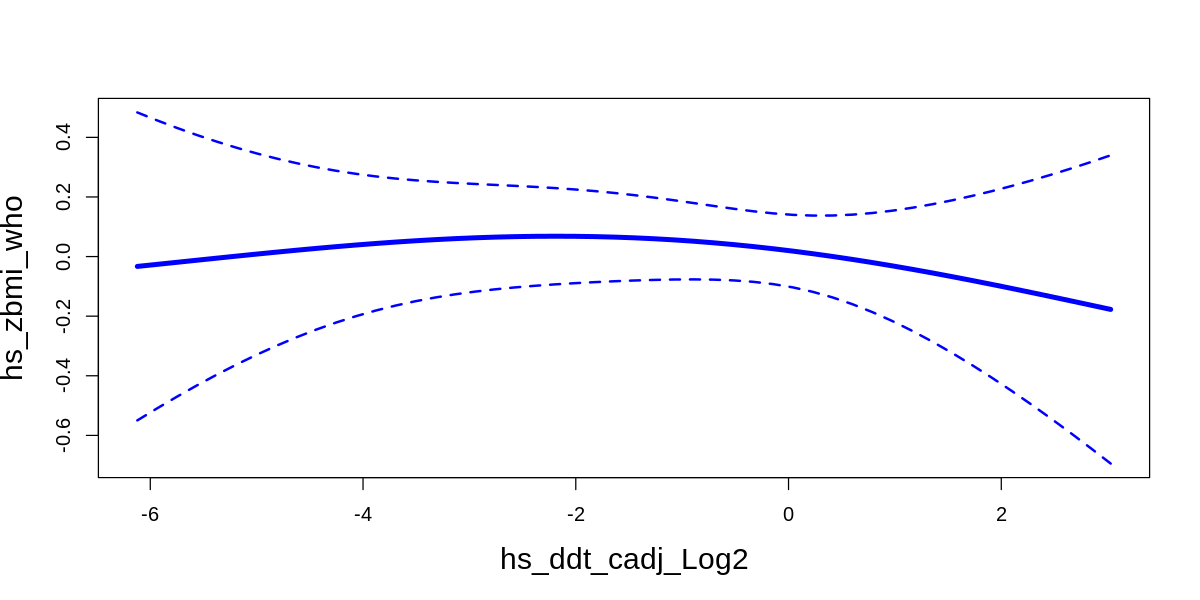

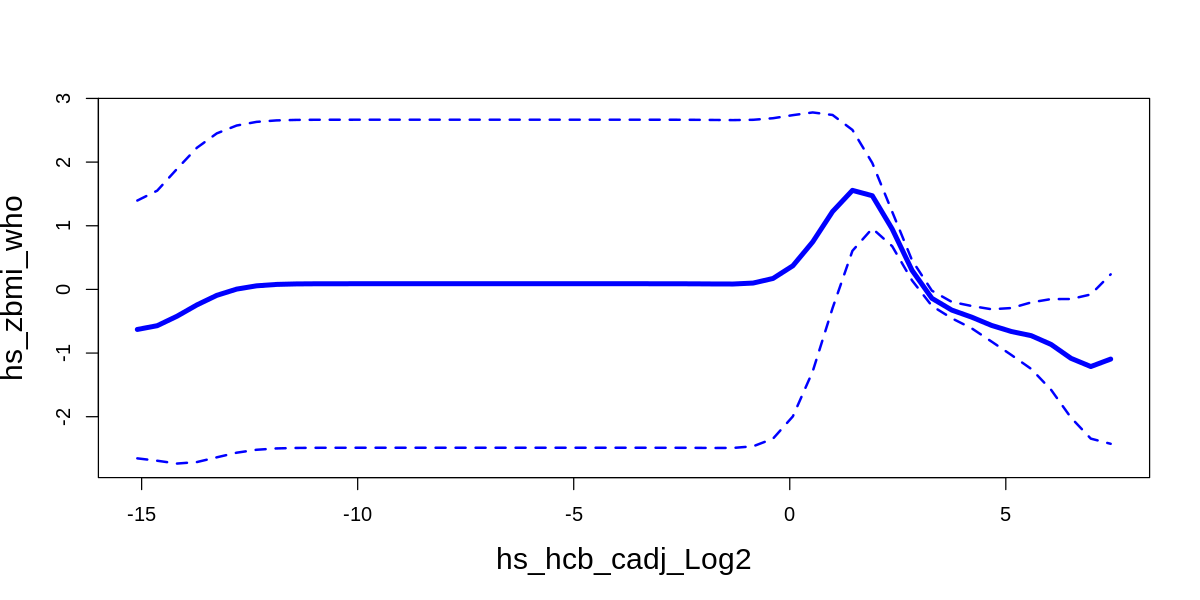

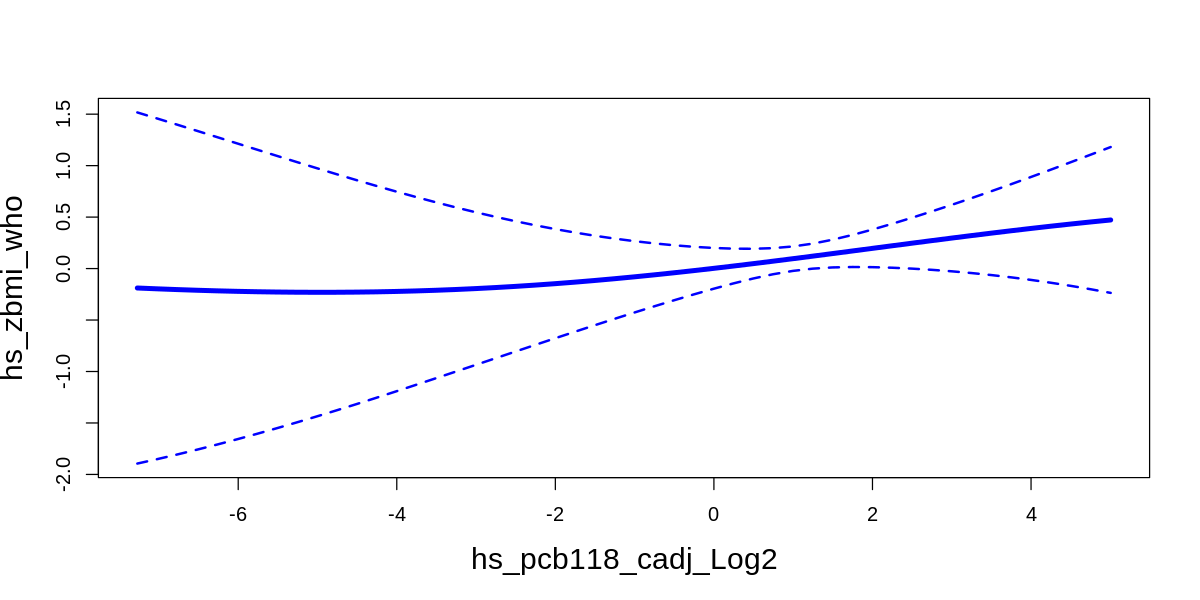

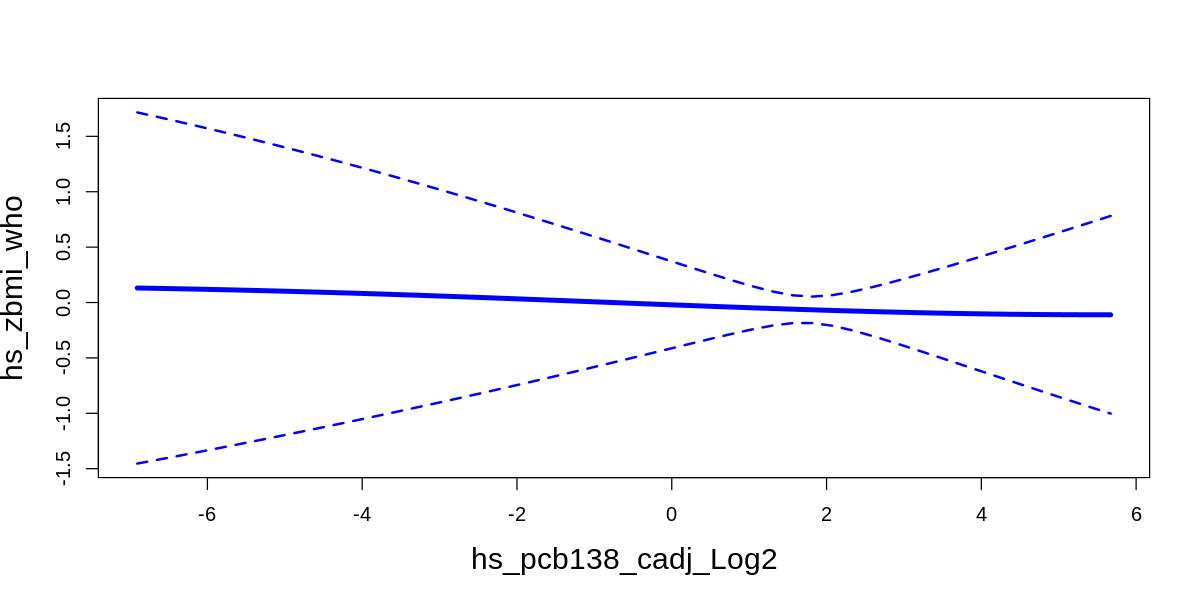

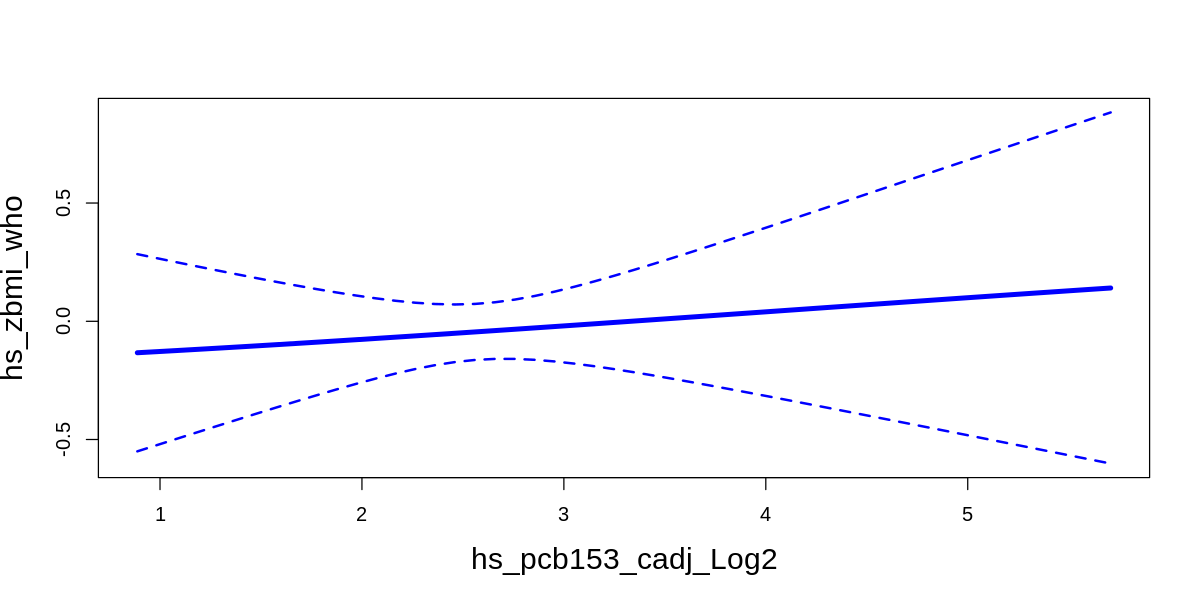

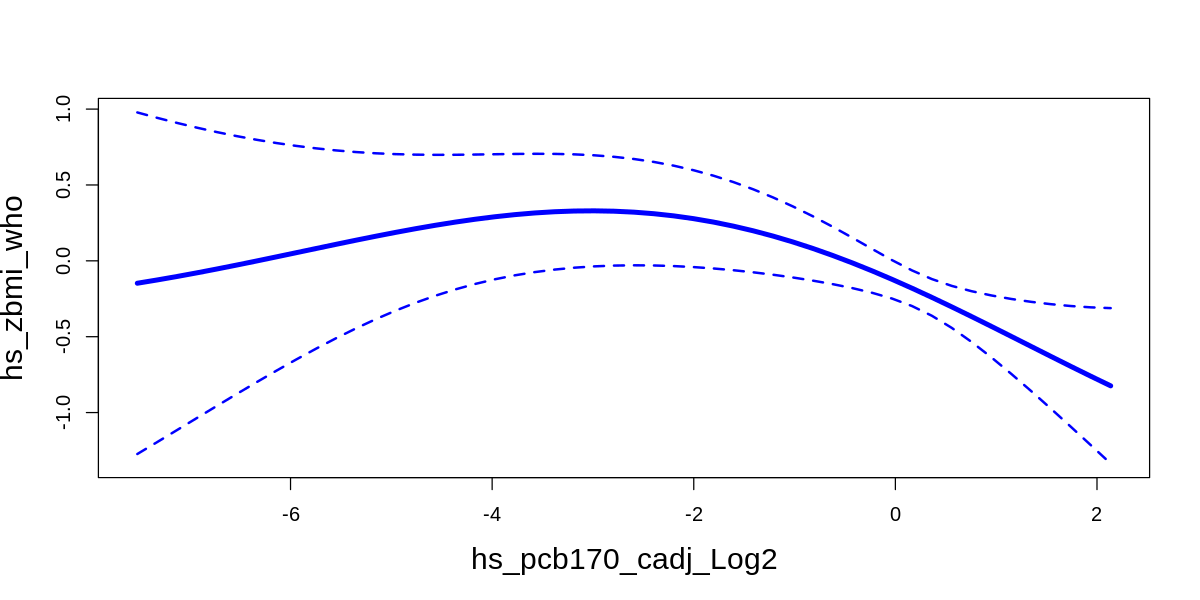

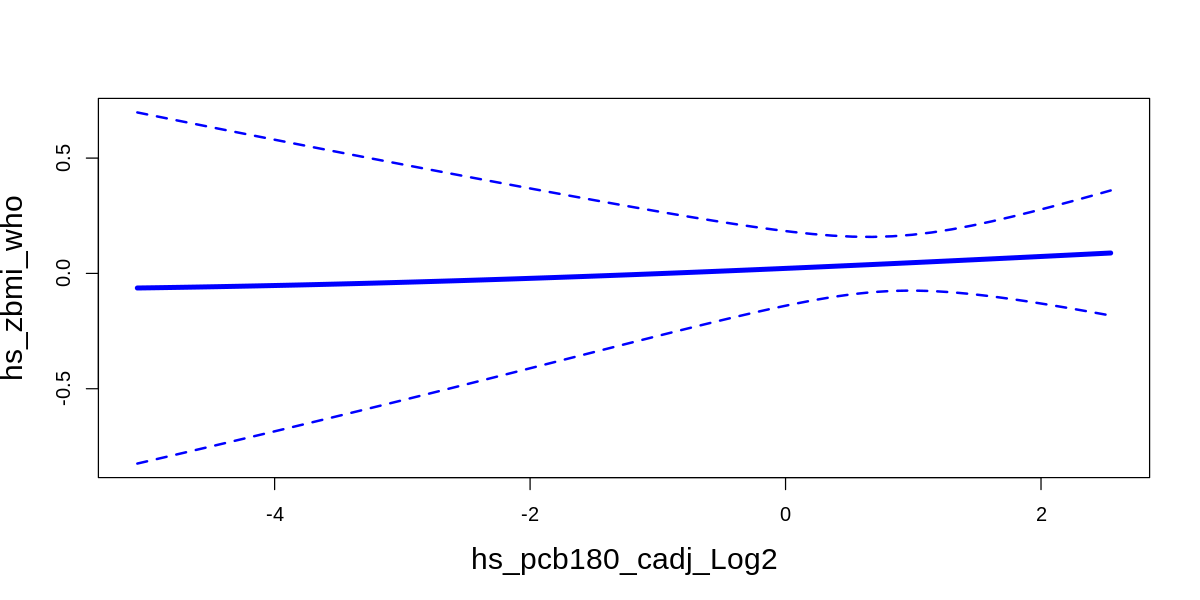

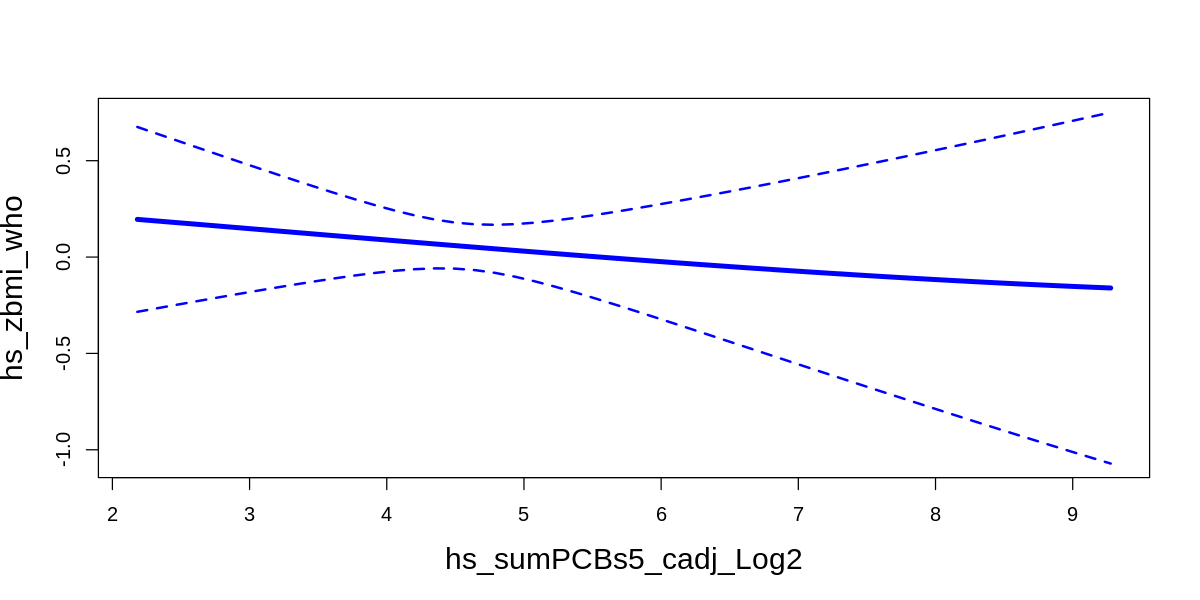

In [ ]:
for (i in 1:length(expo.list)) {
  z <- pred.resp.univar$z[pred.resp.univar$variable==expo.list[i]]
  est <- pred.resp.univar$est[pred.resp.univar$variable==expo.list[i]]
  lower <- pred.resp.univar$est[pred.resp.univar$variable==expo.list[i]]-1.96*pred.resp.univar$se[pred.resp.univar$variable==expo.list[i]]
  upper <- pred.resp.univar$est[pred.resp.univar$variable==expo.list[i]]+1.96*pred.resp.univar$se[pred.resp.univar$variable==expo.list[i]]
  plot(z,est,type="l", col="blue",lwd=4,
     xlab=expo.list[i],ylab="hs_zbmi_who", ylim=c(min(lower),max(upper)),cex.lab=1.5)
  lines(z,lower,lty=2, col="blue",lwd=2)
  lines(z,upper,lty=2, col="blue",lwd=2)
}

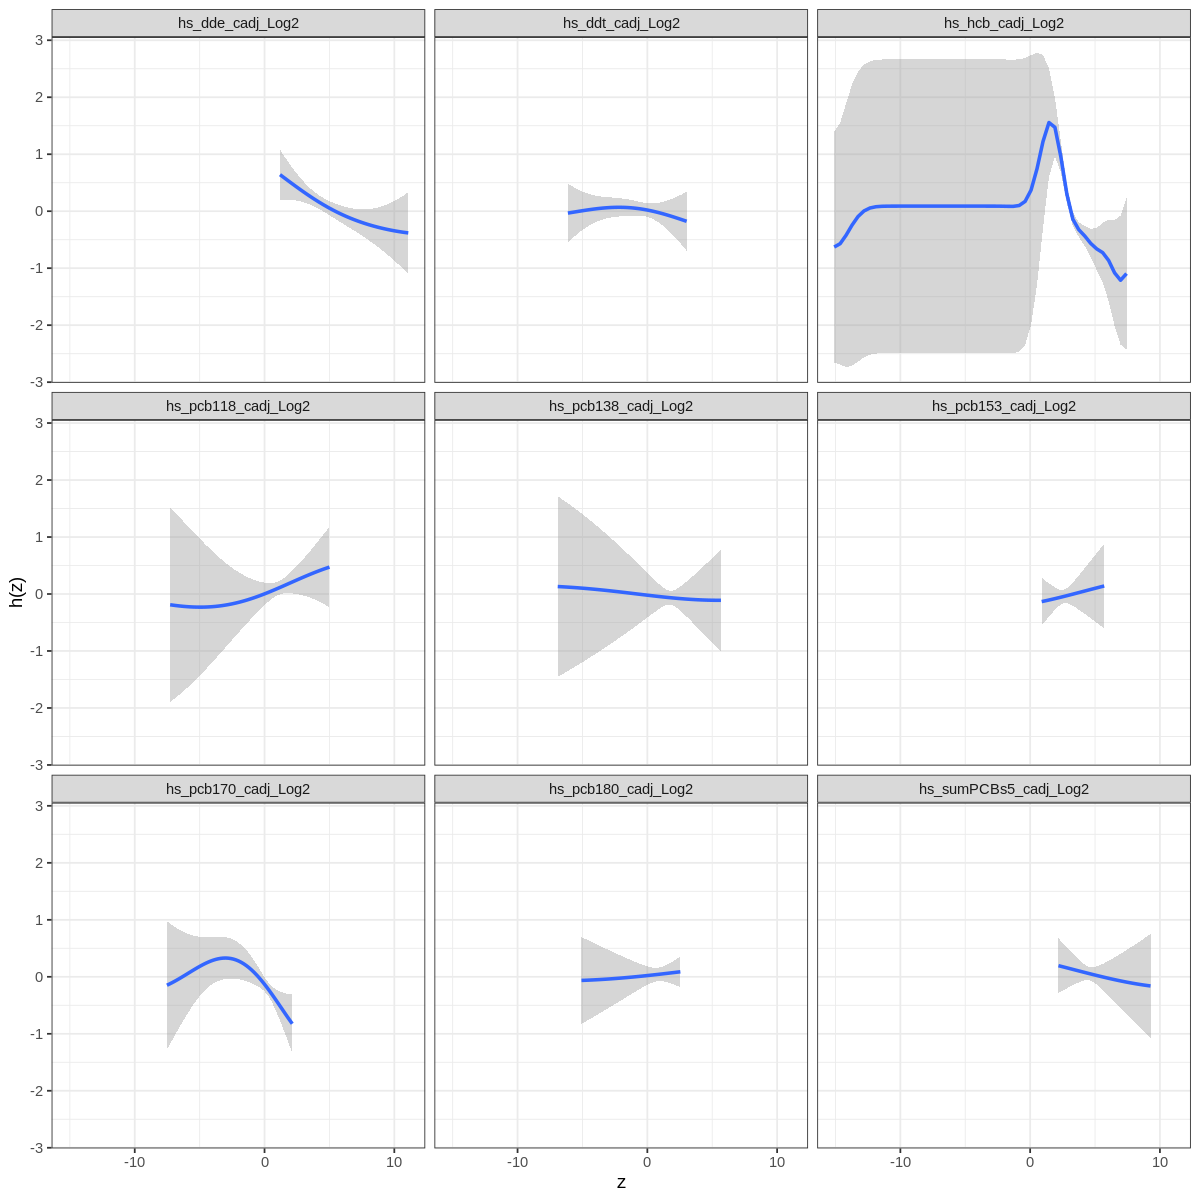

In [ ]:
# We can also use ggplot to look at the graphs
options(repr.plot.width = 10, repr.plot.height = 10) # set graph dimensions
ggplot(pred.resp.univar, aes(z, est, ymin = est - 1.96*se,
                             ymax = est + 1.96*se)) +
  geom_smooth(stat = "identity") + ylab("h(z)") +
  facet_wrap(~ variable) +
  theme_bw()

Additionally we can obtain the overall effect of the mix using the `bkmr::OverallRiskSummaries` function.

In [ ]:
risks.overall <- bkmr::OverallRiskSummaries(fit=fitkm, qs=seq(0.25, 0.75, by=0.05),
                                      q.fixed = 0.5, method = "approx")
# Overall effect of the mixture: change in h() when ALL the exposures are set at the same quantile
# (qs = 25th, 30th, ..., 75th percentiles) compared with all of them at their median (q.fixed = 0.5).
# method = "approx": fast approximation based on posterior means.

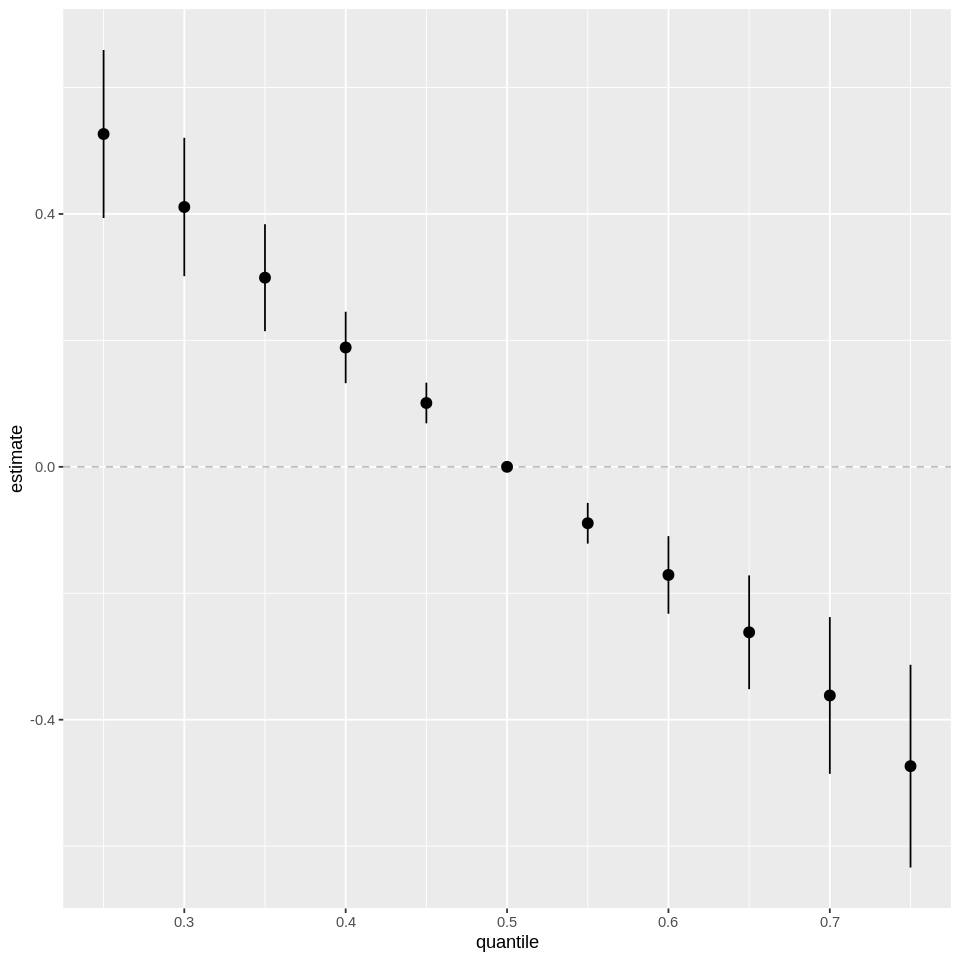

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 8) # set graph dimensions
ggplot(risks.overall, aes(quantile, est, ymin = est - 1.96*sd,
                          ymax = est + 1.96*sd)) +
  geom_hline(yintercept=00, linetype="dashed", color="gray") +
  geom_pointrange() + scale_y_continuous(name="estimate")

If we want to know the contribution of an individual predictor to the health outcome under analysis, we use the function `bkmr::SingVarRiskSummaries`.

In [ ]:
risks.singvar <- SingVarRiskSummaries(fit= fitkm, qs.diff = c(0.25, 0.75),
                                      q.fixed = c(0.25, 0.50, 0.75),
                                      method = "approx")
# Effect of each single exposure: change in h() when that exposure goes from its 25th to its 75th
# percentile (qs.diff), while the other exposures are fixed at their 25th, 50th or 75th percentile
# (q.fixed). If the effect of an exposure changes across the three q.fixed values, this suggests an
# interaction with the rest of the mixture.

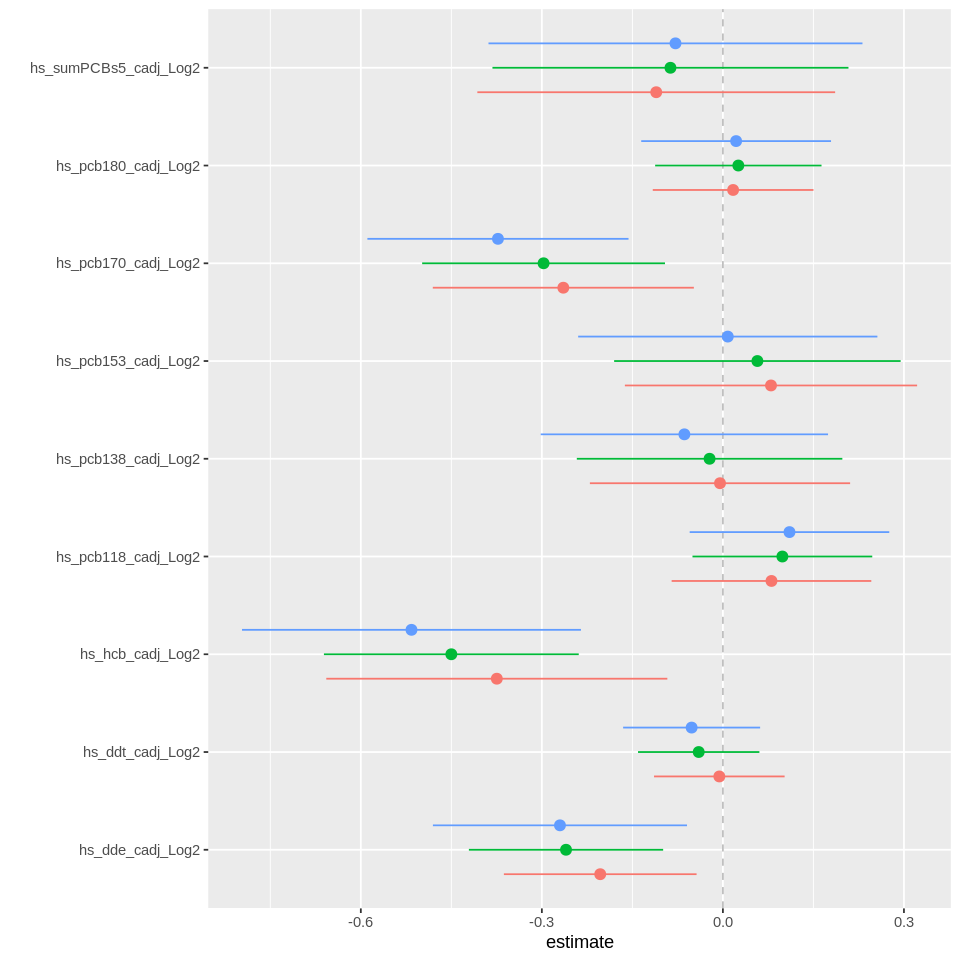

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 8) # set graph dimensions
ggplot(risks.singvar, aes(variable, est, ymin = est - 1.96*sd,
                          ymax = est + 1.96*sd, col = q.fixed)) +
       geom_hline(aes(yintercept=0), linetype="dashed", color="gray") +
       geom_pointrange(position = position_dodge(width = 0.75)) +
       coord_flip() + theme(legend.position="none")+scale_x_discrete(name="") +
       scale_y_continuous(name="estimate")

# Each point: change in zBMI when the exposure goes from its 25th to its 75th percentile (posterior mean),
# with its 95% credible interval.

# Colours: the other exposures are fixed at their 25th (red), 50th (green)
# or 75th (blue) percentile. Intervals not crossing 0 suggest an association.
# Interaction: if the three colours of an exposure were far apart, its effect would depend on the level
# of the rest of the mixture. For hcb and pcb170 the blue estimate is somewhat more negative than the red
# one, so the effect could be slightly stronger when the other exposures are high. However, the intervals
# overlap widely, so the evidence of interaction is weak.

**Quantile g-computation (qgcomp)**
 Quantile g-computation yields estimates of the effect of increasing all exposures by one quantile, simultaneously. Using terminology from methods developed for causal effect estimation, quantile g-computation estimates the parameters of a marginal structural model that characterizes the change in the expected potential outcome given a joint intervention on all exposures, possibly conditional on confounders. Under the assumptions of exchangeability, causal consistency, positivity, no interference, and correct model specification, this model yields a causal effect for an intervention on the mixture as a whole. While these assumptions may not be met exactly, they provide a useful road map for how to interpret the results of a qgcomp fit, and where efforts should be spent in terms of ensuring accurate model specification and selection of exposures that are sufficient to control co-pollutant confounding.

In [ ]:
# Quantile g-computation for the organochlorine mixture (the same exposures used in WQS and BKMR)
organochlorines <- c("hs_dde_cadj_Log2", "hs_ddt_cadj_Log2", "hs_hcb_cadj_Log2", "hs_pcb118_cadj_Log2",
                     "hs_pcb138_cadj_Log2", "hs_pcb153_cadj_Log2", "hs_pcb170_cadj_Log2", "hs_pcb180_cadj_Log2")

# Without bootstrap: fast, valid when the model is linear and additive in the exposures
qc.fit_OCs <- qgcomp.noboot(hs_zbmi_who ~ h_cohort + e3_sex_None + e3_yearbir_None +
                              hs_dde_cadj_Log2 + hs_ddt_cadj_Log2 + hs_hcb_cadj_Log2 + hs_pcb118_cadj_Log2 +
                              hs_pcb138_cadj_Log2 + hs_pcb153_cadj_Log2 + hs_pcb170_cadj_Log2 + hs_pcb180_cadj_Log2,
                            expnms = organochlorines, data = combined_data, family = gaussian(), q = 4)
# Arguments:
# - formula: outcome ~ covariates + exposures of the mixture.
# - expnms: exposures that form the mixture (only these are transformed into quantiles).
# - data: data frame with the outcome, the covariates and the exposures.
# - family = gaussian(): linear regression (passed on to glm).
# - q = 4: each exposure is transformed into quartiles (0, 1, 2, 3).
# psi = joint effect of increasing ALL the exposures of the mixture by one quartile at the same time.
qc.fit_OCs
plot(qc.fit_OCs)  # weights: contribution of each exposure to the positive and to the negative effects

In [ ]:
# With bootstrap: estimates the marginal (population-average) effect of the joint intervention on the
# mixture. Needed for non-linear models (degree > 1), interactions or non-identity links. Slower.
qc.fit_OCs_boot <- qgcomp.boot(hs_zbmi_who ~ h_cohort + e3_sex_None + e3_yearbir_None +
                                 hs_dde_cadj_Log2 + hs_ddt_cadj_Log2 + hs_hcb_cadj_Log2 + hs_pcb118_cadj_Log2 +
                                 hs_pcb138_cadj_Log2 + hs_pcb153_cadj_Log2 + hs_pcb170_cadj_Log2 + hs_pcb180_cadj_Log2,
                               expnms = organochlorines, data = combined_data, family = gaussian(), q = 4,
                               B = 500, seed = 125)
# Arguments (in addition to those of qgcomp.noboot):
# - B = 500: number of bootstrap samples used to compute the confidence intervals (default 200).
# - seed = 125: reproducible bootstrap.
qc.fit_OCs_boot
plot(qc.fit_OCs_boot)  # expected outcome at each joint quartile of the mixture, with its confidence band

## **5.- Other tutorials for exposome research** <a name="tutorials"></a>

Apart from this advanced tutorial, additional e-learning materials, code samples and online books have been generated by ATHLETE project explaining how to implement our developments. Each resource includes clear installation instructions, usage recommendations and real-data showcases illustrating real-world applications. Below we enumerate all of them:

- **Tutorial on ExposomeShiny app** ([link](https://isglobal-brge.github.io/exposome_bookdown/))  
  ExposomeShiny is a data-analysis toolbox implementing the full exposome pipeline: data handling (imputation, LOD, transformation, …), exposome characterization, exposome-wide association analysis, multivariate association, omic-data integration and post-omic analyses (CTD database or enrichment). It wraps Bioconductor packages (rexposome, omicRexposome, CTDquerier, etc.) so you can run them without writing any R code. This tutorial explains how to install and use the ExposomeShiny app.

- **Tutorial on Exposome data analysis with Bioconductor** ([link](https://rpubs.com/jrgonzalezISGlobal/rexposome))  
  Learn the full exposome pipeline in R: data handling (imputation, LOD, transformation, …), exposome characterization (dimensionality reduction, clustering), exposome-wide association, multivariate methods, etc. This tutorial introduces the `rexposome` package and provides reproducible code examples.

- **Tutorial on Repeated Exposome data analysis** ([link](https://github.com/AugustoAnguita/simulation_repeated_exposures))  
  A GitHub repo with R code and simulated data to compare statistical approaches for detecting exposome–health associations in longitudinal settings. Covers a variety of causal scenarios and regression-based methods, plus an application to the INMA mother-child cohort (Spain).

- **Tutorial on outcome-wide analysis methods** ([link](https://rpubs.com/aanguita/outcome_wide_analysis))  
  GitHub + Rpubs tutorial with scripts and a simulated multivariate dataset for outcome-wide methods in exposome research. Includes data standardization, model calibration, output curation and visualization.

- **Tutorial on resources and their use in DataSHIELD** ([link](https://isglobal-brge.github.io/exposome_bookdown/))  
  Online book and video tutorials teaching non-disclosive analysis of biomedical data with R and DataSHIELD. Shows how to use the `resourcer` package to analyze data in different formats (CSV, SPSS, R, …) and handle big-data settings (omics, geospatial).

- **Tutorial on using resources in Opal and DataSHIELD** ([link](https://rpubs.com/jrgonzalezISGlobal/tutorial_resources))  
  Step-by-step guide to set up Opal, upload resources and work with Opal servers in the DataSHIELD environment.

- **Tutorial on Exposome data analysis with DataSHIELD** ([link](https://rpubs.com/jrgonzalezISGlobal/exposomeDataSHIELD))  
  Extends the exposome R tutorials to a federated DataSHIELD setup.

- **Tutorial on omics data analysis with DataSHIELD** ([link](https://rpubs.com/jrgonzalezISGlobal/tutorial_DSomics))  
  Federated omics workflows in DataSHIELD: GWAS for SNP data, polygenic risk scores, genome-wide gene expression and DNA methylation analyses.

- **Tutorial on the use of dsLassoCov in DataSHIELD** ([link](https://rpubs.com/aanguita/986397))  
  Online companion demonstrating feature selection with LASSO and ElasticNet in DataSHIELD, using HELIX cohort data. Introduces the `dsLassoCov` functions for confounder control in penalized regression.


## **6.- Acknowledgment:** <a name="acknowledgement"></a>

ATHLETE project has received funding from the **European Union’s Horizon 2020** research and innovation programme under grant agreement **No 874583**. This publication reflects only the authors’ view and the European Commission is not responsible for any use that may be made of the information it contains.


<img src="https://github.com/alldominguez/ISGlobal.sesion4.Exposoma/blob/main/figures/exposoma.png?raw=1" alt="ISGlobal logo" width="500"/>